# A7 · Five-Layer Stacked RNN and LSTM
## Reproducible experimental report · PyTorch and Keras

**Two tasks:** sentiment classification of e-commerce reviews and next-session AAPL closing-price forecasting.
**Experiment matrix:** 2 datasets × 2 architectures × 2 frameworks = **8 primary models**.

**Intended environment:** 64-bit Windows, Anaconda, Intel Core i5-1235U, 8 GB RAM, Intel Iris Xe.
This notebook deliberately uses the CPU, trains one model at a time, uses `float32`, and releases each model after saving it.
The hardware screenshot shows 8 GB of system RAM; the integrated GPU's 128 MB figure is not evidence of CUDA capability.

**Delivery status:** this notebook is ready for you to run; no Kaggle training results have been filled in beforehand.
Every result table, experimental conclusion, and prediction chart is generated from an actual run.
During preparation, a technical smoke test ran all 8 models on the two real Kaggle CSV files and checked masking, forward equations,
parameter counts, chart creation, JSON export, and checkpoint loading. This test ran on Linux CPU (TensorFlow 2.18.1, PyTorch 2.6.0)
and does not replace your full run on Windows. No assumption is made that LSTM will outperform RNN. The `smoke` configuration
checks that the workflow runs; it must not be used as a reported result.

The report follows the structure of the supplied A6 notebook: project overview → data sources → theory → data preparation → models
→ evaluation → analysis → exported artifacts. A7 replaces the e-commerce service-process task with **review classification** and
replaces the Scratch/Keras/PyTorch comparison with **RNN/LSTM in PyTorch/Keras**. The scope is RNN and LSTM only; no KG, RAG, or Agent is implemented.

## Contents and how to use this notebook

| Section | Contents | Question answered |
|---|---|---|
| A | Overview, sources, environment, folders | What are we doing, with which data, and where? |
| B | Algebra, RNN, LSTM, function composition, BPTT | How do five recurrent layers compute and learn? |
| C | Reviews: audit → normalize → tokenize → split | How is text converted to tensors without leaking labels? |
| D | Stock: audit → features → time split → windows | How can we forecast using only information already known? |
| E | Architecture and training for 8 models | How is the same protocol implemented in two frameworks? |
| F | Metrics, baselines, charts, comparison | Which model performs well, at what cost and with what limitations? |
| G | Inference, web-ready exports, checklist | How can the models be rerun and reused? |

**Read the Markdown explanation before running the code beneath it.** On first use, install the environment and select its kernel.
Then choose **Kernel → Restart Kernel and Run All Cells**. You may run `smoke` first, then switch to `laptop`.

# A. Project overview and study design

### A1. Goals, hypotheses, and scope

- **Reviews:** predict 3 classes from English review text: `0=negative`, `1=neutral`, `2=positive`. Labels are derived from ratings: 1–2 stars → negative, 3 stars → neutral, 4–5 stars → positive. These are **proxy labels**: a 4-star review can still contain criticism. They are not expert sentiment annotations.
- **Stock:** use $L=30$ completed sessions to forecast the **Close of the next session**, after OHLCV for the current session is known. A session means a recorded trading day, not every calendar day. This is not a simultaneous multi-step forecast.
- **Hypothesis:** LSTM gates may preserve long-range dependencies better than a plain RNN, but five layers may be harder to optimize, take longer, and overfit when data is limited. The experiment must test this hypothesis.
- **Fairness:** use the same data, splits, vocabulary, scaler, hidden size, layer count, batch size, seed, epoch limit, and stopping rule. The same hidden size **does not** mean the same number of parameters: LSTM has more projections.
- **Scope of conclusions:** one English clothing-review dataset and one historical stock ticker do not represent every language, e-commerce platform, or market. A good price forecast does not by itself prove that a trading strategy is profitable.

### A2. Data sources and reproducibility

| Kaggle dataset | Main file | Use in A7 |
|---|---|---|
| [Women's E-Commerce Clothing Reviews](https://www.kaggle.com/datasets/nicapotato/womens-ecommerce-clothing-reviews) — nicapotato | `Womens Clothing E-Commerce Reviews.csv` | Review Text and Rating |
| [S&P 500 stock data](https://www.kaggle.com/datasets/camnugent/sandp500) — Cam Nugent | `all_stocks_5yr.csv` | Filter `Name == AAPL`; use date/open/high/low/close/volume |

The review source lists 23,486 rows; the number retained after cleaning is reported automatically.
The stock source covers approximately 2013–2018; the actual date range is read from the CSV. It is **not current-price data**.
The notebook does not replace the Kaggle source with `yfinance`. It records each file's SHA-256, split IDs, configuration, and library versions.
If Kaggle updates a dataset, the hash helps detect when the file differs from a previous run.

The notebook downloads data with `kagglehub`. If Kaggle requires sign-in or acceptance of terms, download the ZIP manually from the dataset page,
extract the CSV into the folders below, and rerun. Do not embed an access token in the notebook.

### A3. Project folder structure shown in the reference image

| Folder at the `DATA` root | Contents |
|---|---|
| `notebooks/` | Store `A7_RNN_LSTM_5Layers.ipynb` here |
| `data/ecommerce/` | Original review CSV |
| `data/stock/` | Original S&P 500 CSV |
| `data/processed/<run_id>/` | Audit, split manifest, preprocessing artifacts |
| `models/<run_id>/` | `.pt`, `.keras`, tokenizer, scaler, configuration, inference module |
| `outputs/<run_id>/` | Metrics, histories, predictions, figures, JSON, interactive HTML |
| `web/` | Reserved for a future local Flask web app |

`run_id` separates runs by configuration and data hash. A completed run with the same configuration can be reused.
An incomplete experiment is never marked `complete`. The notebook creates missing folders and `requirements-a7.txt` at the project root.
The web app is **not built in this notebook**; the data contract and inference function are prepared so a future `app.py` can live in `web/`
and run locally with `cd web` followed by `python app.py`, without retraining inside a web request.

### A4. Set up the Anaconda environment once

Open **Anaconda Prompt** and run each command. These pinned versions form a reproducible environment; they are not a claim to be the latest releases.

```bash
conda create -n a7-rnn python=3.11 -y
conda activate a7-rnn
python -m pip install --upgrade pip
python -m pip install numpy==1.26.4 pandas==2.2.3 scipy==1.14.1 scikit-learn==1.6.1 matplotlib==3.9.4 seaborn==0.13.2 plotly==6.0.1 joblib==1.4.2
python -m pip install torch==2.6.0 --index-url https://download.pytorch.org/whl/cpu
python -m pip install tensorflow==2.18.1 keras==3.8.0 ml-dtypes==0.4.1 kagglehub==0.3.12 notebook ipykernel
python -m ipykernel install --user --name a7-rnn --display-name "Python (A7 RNN-LSTM)"
jupyter notebook
```

Select the **Python (A7 RNN-LSTM)** kernel. Avoid installing into an existing environment with several TensorFlow/PyTorch versions.
Keras is accessed through `tf.keras`. Frameworks are imported only after CPU thread limits are set.
If TensorFlow reports a missing DLL on Windows, follow the official Microsoft Visual C++ Redistributable instructions;
do not download DLL files from an unknown source.

Installation references: [TensorFlow](https://www.tensorflow.org/install/pip), [PyTorch](https://pytorch.org/get-started/locally/).

In [72]:
# Purpose: configure CPU limits before importing frameworks to avoid excessive RAM and thread use.
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['OMP_NUM_THREADS'] = '4'
os.environ['MKL_NUM_THREADS'] = '4'
os.environ['TF_NUM_INTRAOP_THREADS'] = '4'
os.environ['TF_NUM_INTEROP_THREADS'] = '1'

from pathlib import Path
import sys, json, re, html, unicodedata, time, gc, math, hashlib, random, shutil, platform
from collections import Counter
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    precision_recall_fscore_support, classification_report, confusion_matrix,
    log_loss, roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    mean_absolute_error, mean_squared_error, r2_score)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
import tensorflow as tf
import plotly.graph_objects as go
import plotly.io as pio
pio.renderers.default = 'notebook_connected'
torch.set_num_threads(4)
try:
    tf.config.threading.set_intra_op_parallelism_threads(4)
    tf.config.threading.set_inter_op_parallelism_threads(1)
except RuntimeError:
    print('TensorFlow is initialized; restart the kernel to change its thread limits.')

sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_colwidth', 110)

# Run from DATA or DATA/notebooks; a Windows path can be set in ROOT_OVERRIDE.
ROOT_OVERRIDE = None  # Example: r'D:\Downloads\Intelligent System\assignment 7\DATA'
ROOT = Path(ROOT_OVERRIDE).expanduser().resolve() if ROOT_OVERRIDE else (
    Path.cwd().parent if Path.cwd().name.lower() == 'notebooks' else Path.cwd())
for folder in ['data/ecommerce', 'data/stock', 'data/processed', 'notebooks', 'models', 'outputs', 'web']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
print('Project root:', ROOT)
print('Python:', sys.version.split()[0], '| Torch:', torch.__version__, '| TensorFlow:', tf.__version__)
print('Training device: CPU. Check the project root before continuing.')


Project root: C:\Users\ADMIN\Downloads\Intelligent System\assignment 7\DATA
Python: 3.11.16 | Torch: 2.6.0+cpu | TensorFlow: 2.18.1
Training device: CPU. Check the project root before continuing.


### A5. Configuration and what each setting means

The default `laptop` preset uses 5 layers × 32 hidden units to fit within 8 GB of RAM. Models run sequentially.
`epochs` is the maximum number of passes through the training set, not the number of layers. Early stopping can end training sooner.

| Setting | Meaning |
|---|---|
| `layers=5` | Recurrent depth; each layer also repeats over time |
| `hidden=32` | Number of components in each hidden state |
| `embedding=48` | Number of components in each token vector |
| `vocab=10000` | Maximum vocabulary size, including PAD and UNK |
| `max_len=80` | Keep up to 80 leading tokens per review; the truncation rate is measured |
| `lookback=30` | Use 30 consecutive trading sessions as the stock input |
| `batch=32` | Number of examples used for one gradient update |
| `lr=0.001` | Adam's starting learning rate |
| `clip=1.0` | Global gradient-norm threshold to limit exploding gradients |
| `head_dropout=0.15` | Randomly drop 15% of the final hidden vector during training; disabled at inference |
| `patience=4` | Stop if validation loss fails to improve for 4 epochs |
| `max_train_text=10000` | Limit training reviews only; validation and test remain unchanged in laptop mode |

`full` removes the training limit and increases the training budget; it still uses five layers. `smoke` uses a small subset and one epoch.
One seed provides exploratory evidence only. For a more stable report, set `SEEDS=[42,123,2026]` and allow more time.
No laptop run time is promised before measurement; the history records the actual seconds per epoch.

In [73]:
# Purpose: keep experiment settings and rerun behavior in one place.
PRESET = 'full'  # 'smoke', 'laptop', 'full'
SEEDS = [42]
SPLIT_SEED = 42
AUTO_DOWNLOAD = True
REUSE_COMPLETED = True
PRESETS = {
    'smoke': dict(hidden=8, embedding=12, vocab=1000, max_len=24, lookback=30,
                  epochs=1, max_train_text=192),
    'laptop': dict(hidden=32, embedding=48, vocab=10000, max_len=80, lookback=30,
                   epochs=15, max_train_text=10000),
    'full': dict(hidden=48, embedding=64, vocab=15000, max_len=120, lookback=30,
                 epochs=30, max_train_text=None),
}
CFG = dict(PRESETS[PRESET], layers=5, batch=32, lr=5e-4, adam_eps=1e-7,
           clip=1.0, head_dropout=0.25, patience=6, min_delta=1e-5, ticker='AAPL')
assert CFG['layers'] == 5
LABELS = ['negative', 'neutral', 'positive']


def seed_all(seed):
    """Set the seed before each model; the same seed does not guarantee identical weights across frameworks."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    tf.keras.utils.set_random_seed(seed)


def save_json(path, data):
    """Write strict UTF-8 JSON; convert NumPy/Path values so the web app can read it independently of Python."""
    def convert(value):
        if isinstance(value, (np.integer,)): return int(value)
        if isinstance(value, (np.floating,)): return float(value)
        if isinstance(value, np.ndarray): return value.tolist()
        if isinstance(value, Path): return str(value)
        if isinstance(value, pd.Timestamp): return value.isoformat()
        raise TypeError(type(value).__name__)
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(data, ensure_ascii=False, indent=2,
                                   default=convert, allow_nan=False), encoding='utf-8')


def sha256_file(path):
    """Create a data fingerprint to detect changes to source CSV files."""
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

seed_all(SEEDS[0])
display(pd.DataFrame({'parameter': CFG.keys(), 'value': list(CFG.values())}))
requirements = """numpy==1.26.4
pandas==2.2.3
scipy==1.14.1
scikit-learn==1.6.1
matplotlib==3.9.4
seaborn==0.13.2
plotly==6.0.1
joblib==1.4.2
torch==2.6.0
tensorflow==2.18.1
keras==3.8.0
ml-dtypes==0.4.1
kagglehub==0.3.12
notebook
ipykernel
"""
(ROOT / 'requirements-a7.txt').write_text(requirements, encoding='utf-8')


,parameter,value
0,hidden,48
1,embedding,64
2,vocab,15000
3,max_len,120
4,lookback,30
5,epochs,30
6,max_train_text,None
7,layers,5
8,batch,32
9,lr,0.0005


223

# B. Mathematical foundations before building the models

### B1. Data, tensors, and notation

A tensor is a multidimensional array. A scalar is rank 0, a vector rank 1, and a matrix rank 2.
This notebook uses **row vectors** to match the matrix multiplication convention in the NumPy code.

| Symbol | Meaning | Size |
|---|---|---|
| $B$ | Batch size | Number of examples |
| $T$ | Sequence length; text up to `max_len`, stock `lookback` | Number of steps |
| $F$ | Stock features per session | Number of input columns |
| $V$ | Number of tokens in the vocabulary | Includes PAD/UNK |
| $E$ | Embedding dimension | `embedding` |
| $H$ | Hidden size of each layer | `hidden` |
| $\ell$ | Recurrent layer index | $1,2,3,4,5$ |
| $t$ | Time/token index | $1,\ldots,T$ |
| $h_t^{(\ell)}$ | Hidden state at layer $\ell$, step $t$ | $B\times H$ |
| $c_t^{(\ell)}$ | LSTM cell state | $B\times H$ |
| $\theta$ | All learned parameters | Weight matrices and biases |
| $\hat y$ | Prediction; the hat distinguishes it from true label $y$ | Depends on task |
| $\odot$ | Element-wise product | Compatible tensor shapes |
| $\circ$ | Function composition: $(f\circ g)(x)=f(g(x))$ | Apply $g$ first |

**Reviews:** raw string → token IDs $(B,T)$ → Embedding $(B,T,E)$ → 5 recurrent layers → logits $(B,3)$.
**Stock:** numeric tensor $(B,T,F)$ → 5 recurrent layers → linear output $(B,1)$.
Both tasks are **many-to-one**: one sequence produces one label or value. This is not next-word prediction.

### B2. Elementary functions and operations used to build the models

1. **Matrix multiplication** $XW$: combines input features using learned weights.
2. **Affine transform** $A(X)=XW+b$: a linear transform plus a bias shift; the bias is broadcast across examples.
3. **Sigmoid** $\sigma(z)=1/(1+e^{-z})$: outputs values in $(0,1)$ and acts as an LSTM gate opening level.
4. **Tanh** $\tanh(z)=(e^z-e^{-z})/(e^z+e^{-z})$: outputs values in $(-1,1)$, allowing positive and negative states.
5. **Hadamard product** $u\odot v$: multiplies entries in matching positions; it is not matrix multiplication.
6. **Softmax** $p_k=e^{z_k-m}/\sum_j e^{z_j-m}$, where $m=\max_j z_j$: converts logits into a probability distribution.
   Subtracting $m$ prevents numerical overflow; $\sum_k p_k=1$. A softmax score is not necessarily well calibrated.
7. **Linear head** $z=hW_y+b_y$: the classification output is 3-class logits; the regression output is one real number.

Derivatives: $\tanh'(z)=1-\tanh^2(z)$; $\sigma'(z)=\sigma(z)(1-\sigma(z))$.
When $|z|$ is very large, these functions saturate and their derivatives become small; gradients can weaken through a long composition.

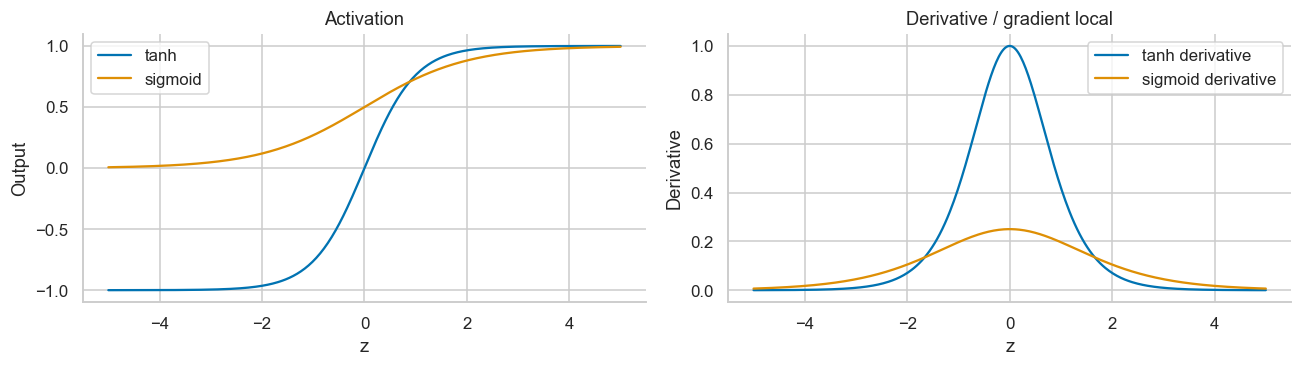

In [74]:
# Purpose: inspect elementary functions and derivatives rather than only memorizing formulas.
z = np.linspace(-5, 5, 400)
sigmoid = 1 / (1 + np.exp(-z))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(z, np.tanh(z), label='tanh')
axes[0].plot(z, sigmoid, label='sigmoid')
axes[0].set(title='Activation', xlabel='z', ylabel='Output')
axes[1].plot(z, 1-np.tanh(z)**2, label="tanh derivative")
axes[1].plot(z, sigmoid*(1-sigmoid), label="sigmoid derivative")
axes[1].set(title='Derivative / gradient local', xlabel='z', ylabel='Derivative')
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()


### B3. One RNN step and the composition of five layers

Let $u_t^{(1)}=x_t$ and $u_t^{(\ell)}=h_t^{(\ell-1)}$ for $\ell>1$:

$$a_t^{(\ell)}=u_t^{(\ell)}W_{xh}^{(\ell)}+h_{t-1}^{(\ell)}W_{hh}^{(\ell)}+b^{(\ell)}$$
$$h_t^{(\ell)}=\tanh(a_t^{(\ell)})\quad (\ell=1,\ldots,5).$$

For the first layer, $W_{xh}^{(1)}\in\mathbb R^{D\times H}$, where $D=E$ for reviews or $D=F$ for stock.
For layers 2–5, $W_{xh}^{(\ell)}\in\mathbb R^{H\times H}$. Every $W_{hh}^{(\ell)}\in\mathbb R^{H\times H}$;
$b^{(\ell)}\in\mathbb R^H$. The initial state is zero and is reset independently for each example.

At **one time step**, hold each $h_{t-1}^{(\ell)}$ fixed and define:
$$\phi_t^{(\ell)}(u)=\tanh(uW_{xh}^{(\ell)}+h_{t-1}^{(\ell)}W_{hh}^{(\ell)}+b^{(\ell)}).$$
Then:
$$h_t^{(5)}=(\phi_t^{(5)}\circ\phi_t^{(4)}\circ\phi_t^{(3)}\circ\phi_t^{(2)}\circ\phi_t^{(1)})(x_t).$$

At the **whole-sequence** level, let $\mathcal R_\ell$ denote running recurrent layer $\ell$ over the entire input sequence:
$$\hat y=\operatorname{Head}\circ\operatorname{LastValid}\circ\mathcal R_5\circ\mathcal R_4\circ\mathcal R_3\circ\mathcal R_2\circ\mathcal R_1(X).$$
`LastValid` selects the last real token (reviews) or session (stock). Weights are **shared across time within a layer**;
the five layers have five distinct parameter sets. Five layers does not mean five tokens, sessions, or hidden units.

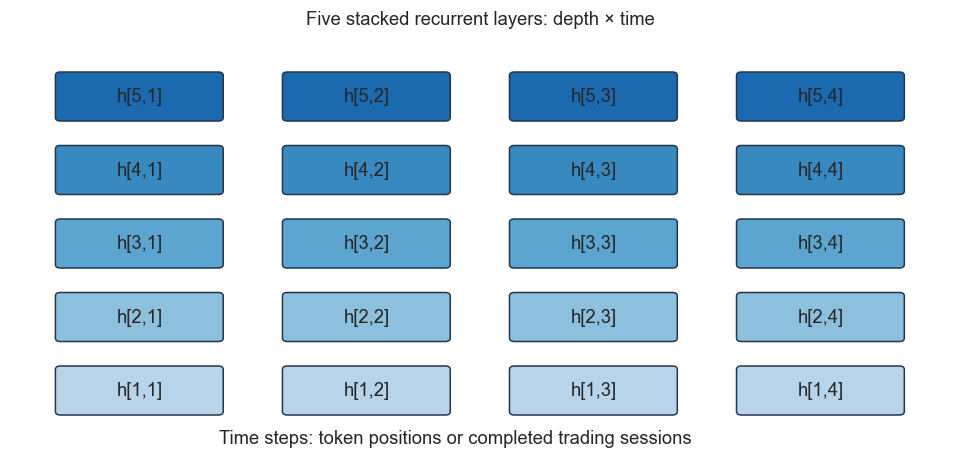

In [75]:
# Purpose: distinguish vertical layer depth from horizontal repetition across time.
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(11, 5))
for layer in range(5):
    for t in range(4):
        x, y = 2.3*t, 1.05*layer
        ax.add_patch(FancyBboxPatch((x,y),1.6,.6,boxstyle='round,pad=.05',
                                   facecolor=plt.cm.Blues(.3+.12*layer),edgecolor='#26354a'))
        ax.text(x+.8,y+.3,f'h[{layer+1},{t+1}]',ha='center',va='center')
        if t<3: ax.annotate('',(x+2.25,y+.3),(x+1.65,y+.3),arrowprops={'arrowstyle':'->'})
        if layer<4: ax.annotate('',(x+.8,y+1),(x+.8,y+.65),arrowprops={'arrowstyle':'->'})
ax.set(xlim=(-.5,9),ylim=(-.65,5.4),title='Five stacked recurrent layers: depth × time')
ax.text(4,-.45,'Time steps: token positions or completed trading sessions',ha='center')
ax.axis('off'); plt.show()


### B4. LSTM: four computation branches, three gates, and a cell state

An LSTM (Long Short-Term Memory) maintains both a **hidden state $h$** and a **cell state $c$**. The cell state is a memory path,
not an extra recurrent layer. For each layer $\ell$ and step $t$:

$$i_t=\sigma(u_tW_{xi}+h_{t-1}W_{hi}+b_i),\qquad
f_t=\sigma(u_tW_{xf}+h_{t-1}W_{hf}+b_f)$$
$$g_t=\tanh(u_tW_{xg}+h_{t-1}W_{hg}+b_g),\qquad
o_t=\sigma(u_tW_{xo}+h_{t-1}W_{ho}+b_o)$$
$$c_t=f_t\odot c_{t-1}+i_t\odot g_t,\qquad h_t=o_t\odot\tanh(c_t).$$

The layer index is omitted above for readability; each layer has its own parameters and states.

| Symbol | Name | Meaning |
|---|---|---|
| $i_t$ | Input gate | How much new information may be written |
| $f_t$ | Forget gate | How much of the old cell state is retained; near 1 means retain more |
| $g_t$ | Candidate state | Proposed new content; this is not a sigmoid gate |
| $o_t$ | Output gate | How much cell-state information is exposed as hidden state |
| $c_t$ | Cell state | Internal memory updated through two additive branches |
| $h_t$ | Hidden state | Output passed to the next layer and next time step |

**One-component example:** if $c_{t-1}=0.8$, $f_t=0.9$, $i_t=0.2$, and $g_t=-0.5$, then
$c_t=0.9\times0.8+0.2\times(-0.5)=0.62$. If $o_t=0.7$, then $h_t=0.7\tanh(0.62)\approx0.386$.
This is an illustrative calculation, not a value from a trained model.

**Composition of a five-layer LSTM:** $\mathcal L_\ell$ maps an input sequence to a sequence of hidden states using
Affine → sigmoid/tanh → element-wise multiplication → addition → tanh → multiplication. Across a whole sequence:
$$\hat y=\operatorname{Head}\circ\operatorname{LastValid}\circ\mathcal L_5\circ\mathcal L_4\circ\mathcal L_3\circ\mathcal L_2\circ\mathcal L_1(X).$$
At each step, an upper layer receives the lower layer's **$h_t$**; it does not directly receive the lower layer's $c_t$.
If we isolate the cell-state path while holding the gates fixed,
$\partial c_t/\partial c_{t-1}=\operatorname{diag}(f_t)$: when many $f_t$ components are near 1, information can persist longer
along this path. This is not the full derivative because the gates also depend on hidden states.
The additive path through $c_t$ can help gradient flow, but LSTMs can still suffer vanishing gradients, overfit, or learn poorly.

In [76]:
# Purpose: evaluate a cell’s elementary functions in NumPy; this is not an additional Scratch model.
def rnn_cell_demo(x, h, Wx, Wh, bias):
    """One RNN step using row vectors; returns the new hidden state."""
    return np.tanh(x @ Wx + h @ Wh + bias)


def lstm_cell_demo(x, h, c, Wx, Wh, bias):
    """One LSTM step; branch order i, f, g, o matches the implementation below."""
    gates = x @ Wx + h @ Wh + bias
    zi, zf, zg, zo = np.split(gates, 4, axis=-1)
    sig = lambda value: 1 / (1 + np.exp(-np.clip(value, -50, 50)))
    i, f, g, o = sig(zi), sig(zf), np.tanh(zg), sig(zo)
    new_c = f*c + i*g
    new_h = o*np.tanh(new_c)
    return new_h, new_c, {'input': i, 'forget': f, 'candidate': g, 'output': o}

rng = np.random.default_rng(42)
x, h, c = rng.normal(size=(2,3)), np.zeros((2,4)), np.zeros((2,4))
new_h, new_c, gates = lstm_cell_demo(x,h,c,rng.normal(0,.1,(3,16)),
                                   rng.normal(0,.1,(4,16)),np.zeros(16))
print('Input:',x.shape,'Hidden:',new_h.shape,'Cell:',new_c.shape)
display(pd.DataFrame({name: values[0] for name, values in gates.items()}))


Input: (2, 3) Hidden: (2, 4) Cell: (2, 4)


,input,forget,candidate,output
0,0.453852,0.480384,-0.142117,0.496101
1,0.513811,0.500779,0.032850,0.482118
2,0.524932,0.491962,0.114948,0.474239
3,0.512844,0.501489,0.060410,0.510657


### B5. Parameter count and why LSTM is larger

An RNN layer with input dimension $D$ and hidden size $H$ has $DH+H^2+H$ parameters with one bias.
An LSTM layer has four affine groups, so its count is $4(DH+H^2+H)$.
PyTorch defaults to two biases, `bias_ih` and `bias_hh`; Keras uses one bias.
Thus set $b=1$ for Keras, $b=2$ for PyTorch, $g=1$ for RNN, and $g=4$ for LSTM:

$$P_{recurrent}=g\left[DH+H^2+bH+4(2H^2+bH)\right].$$

The final factor 4 represents the **four remaining layers** in the five-layer architecture; it is distinct from $g=4$, the **four LSTM branches**.
The embedding adds $VE$ parameters; the Dense head adds $HC+C$, where $C=3$ for reviews or $C=1$ for stock.
For reviews, $D=E$; for stock, $D=F$. `model.count_params()` and total `numel()` verify the formula.
Parameter count does not directly measure training time; sequence length, batch size, and CPU kernels also matter.

### B6. Loss functions, BPTT, gradient clipping, and Adam

**Classification:** logits are converted to $p_{ic}$. For true label $y_i$:
$$\mathcal{L}_{CE}=-\frac1B\sum_{i=1}^{B}w_{y_i}\log p_{i,y_i}.$$
Weights $w_c=N/(C n_c)$ are computed from training data so a less frequent class contributes more. $N$ is the training sample count;
$n_c$ is the count for class $c$. Validation and test use unweighted loss for clearer comparison. Both frameworks use the same division by $B$.
the default PyTorch weighted mean with a different denominator is not used.

**Regression:** for a standardized target:
$$\mathcal L_{MSE}=\frac1B\sum_i(y_i-\hat y_i)^2.$$
MSE penalizes large errors more strongly than small ones. Reported metrics are converted back to the original price units.

**BPTT:** Backpropagation Through Time applies the chain rule through the sequence and five layers to compute
$\nabla_\theta\mathcal L$. In the equivalent column-vector convention, the one-step RNN Jacobian is
$J_t=\operatorname{diag}(1-h_t^2)W_{hh}^{T}$ under the row-vector weight convention above.
A product of many Jacobians can make gradients very small (vanishing) or very large (exploding).

**Global norm clipping:** $g\leftarrow g\min(1,\tau/(\|g\|_2+\epsilon))$, with $\tau=1$.
Clipping limits the gradient step size; it does not solve every vanishing-gradient problem.

**Adam:** maintain moving averages of the gradient $m_t=\beta_1m_{t-1}+(1-\beta_1)g_t$ and squared gradient
$v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2$; apply bias corrections $\hat m_t=m_t/(1-\beta_1^t)$,
$\hat v_t=v_t/(1-\beta_2^t)$, then update
$\theta_t=\theta_{t-1}-\eta\hat m_t/(\sqrt{\hat v_t}+\epsilon)$.
The notebook uses $\beta_1=0.9$, $\beta_2=0.999$, $\eta=10^{-3}$, and $\epsilon=10^{-7}$.

**Early stopping:** select the checkpoint with the lowest validation loss, never the test score. Each epoch trains → validates → saves if improved;
training stops when patience is exhausted, then restores the best checkpoint. RNN state is not carried between separate reviews or windows.

# C. Dataset 1 · E-commerce review analysis

### C1. Load the data and audit its source

Each row is one review. Only **Review Text** is passed to the model; Rating is used to create the label.
Do not include `Recommended IND`, rating, or columns that reflect the review outcome in the input because they could leak the label.
`Clothing ID` is for auditing and is not treated as text content.

| Raw column | Meaning | Use in this experiment |
|---|---|---|
| Unnamed: 0 | CSV row index, if present | Not used as a feature |
| Clothing ID | Clothing product identifier | Product audit; excluded from model input |
| Age | Reviewer's age | Excluded to avoid mixing demographics with text interpretation |
| Title | Review title; may be missing | Excluded by the body-only protocol |
| Review Text | English review content | Main input; normalized and tokenized |
| Rating | 1–5 star score | Used only to create the target label; never an input |
| Recommended IND | Whether the reviewer recommends the product | Excluded because it is strongly associated with sentiment labels |
| Positive Feedback Count | Number of helpful/positive responses to the review | Excluded; it may reflect information generated after the review was posted |
| Division Name | Broad product division | Metadata audit only; not an input |
| Department Name | Product department | Metadata audit only; not an input |
| Class Name | Specific product class | Metadata audit only; not an input |

Both title and review body may contain opinions. This protocol deliberately uses only the body to keep the input simple and consistent.

The loader checks local files first. If a file is missing, it downloads the specified Kaggle resource and copies the CSV into the project.
A missing file or unexpected schema raises a clear error; the notebook does not silently substitute mock data or another source.

In [77]:
# Purpose: download, validate, and load the exact Kaggle CSV files used by this project.
import zipfile


def csv_header(path):
    """Read a CSV header using supported text encodings; return its columns and read options."""
    path = Path(path)

    if not path.is_file():
        raise FileNotFoundError(f"CSV file does not exist: {path}")

    if zipfile.is_zipfile(path):
        raise ValueError(f"The file is a ZIP archive, not a CSV: {path}")

    errors = []

    for encoding, encoding_errors in [("utf-8-sig", None), ("cp1252", "replace")]:
        options = {
            "encoding": encoding,
            "engine": "python",
        }

        if encoding_errors is not None:
            options["encoding_errors"] = encoding_errors

        try:
            columns = list(pd.read_csv(path, nrows=0, **options).columns)
            return columns, options
        except (UnicodeDecodeError, pd.errors.ParserError, ValueError) as exc:
            errors.append(f"{encoding}: {exc}")

    preview = path.read_bytes()[:16].hex(" ")
    raise ValueError(
        f"Cannot read a CSV header from {path}. "
        f"First bytes: {preview}. Parser errors: {' | '.join(errors)}"
    )


def extract_csv_from_zip(archive_path, filename, destination):
    """Extract exactly one CSV with the requested filename without extracting other files."""
    archive_path = Path(archive_path)
    destination = Path(destination)

    with zipfile.ZipFile(archive_path) as archive:
        matches = [
            name for name in archive.namelist()
            if Path(name).name.casefold() == filename.casefold()
        ]

        if len(matches) != 1:
            raise ValueError(
                f"Expected exactly one {filename} in {archive_path}; found {len(matches)}."
            )

        target = destination / filename
        temporary = target.with_suffix(target.suffix + ".tmp")

        with archive.open(matches[0]) as source, temporary.open("wb") as output:
            shutil.copyfileobj(source, output)

        temporary.replace(target)

    return target


def valid_dataset_file(path, required_columns):
    """Accept a local file only if it is a readable CSV with the required columns."""
    path = Path(path)

    if not path.is_file() or path.stat().st_size == 0 or zipfile.is_zipfile(path):
        return False

    try:
        columns, _ = csv_header(path)
        return set(required_columns).issubset(columns)
    except (OSError, ValueError, pd.errors.ParserError):
        return False


def ensure_dataset(handle, filename, destination, required_columns):
    """Reuse a valid CSV or download and validate the requested file from Kaggle."""
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=True)
    target = destination / filename

    # Recover if a ZIP archive was previously saved with a .csv filename.
    if target.is_file() and zipfile.is_zipfile(target):
        try:
            target = extract_csv_from_zip(target, filename, destination)
        except (OSError, zipfile.BadZipFile, ValueError):
            target.unlink(missing_ok=True)

    # Do not treat an invalid or stale non-empty file as a valid dataset.
    if valid_dataset_file(target, required_columns):
        return target

    target.unlink(missing_ok=True)

    if not AUTO_DOWNLOAD:
        raise ValueError(
            f"The local file is missing or is not the expected CSV: {target}. "
            f"Required columns: {sorted(required_columns)}. "
            "Enable AUTO_DOWNLOAD or place the original Kaggle CSV in this folder."
        )

    try:
        import kagglehub

        # Download the dataset directory, then find the exact CSV by filename.
        downloaded = Path(kagglehub.dataset_download(handle))
        source = None

        if downloaded.is_file() and downloaded.name.casefold() == filename.casefold():
            source = downloaded

        elif downloaded.is_dir():
            matches = [
                item for item in downloaded.rglob(filename)
                if item.is_file() and not zipfile.is_zipfile(item)
            ]

            if len(matches) == 1:
                source = matches[0]

            elif len(matches) > 1:
                raise ValueError(
                    f"Found multiple files named {filename} under {downloaded}; "
                    "cannot select a source safely."
                )

            else:
                archives = [
                    item for item in downloaded.rglob("*.zip")
                    if item.is_file()
                ]
                zip_matches = []

                for archive_path in archives:
                    try:
                        with zipfile.ZipFile(archive_path) as archive:
                            contains_file = any(
                                Path(name).name.casefold() == filename.casefold()
                                for name in archive.namelist()
                            )

                        if contains_file:
                            zip_matches.append(archive_path)

                    except zipfile.BadZipFile:
                        continue

                if len(zip_matches) == 1:
                    source = zip_matches[0]
                else:
                    raise FileNotFoundError(
                        f"Could not locate exactly one {filename} in {downloaded}."
                    )

        elif downloaded.is_file() and zipfile.is_zipfile(downloaded):
            source = downloaded

        else:
            raise FileNotFoundError(
                f"KaggleHub returned an unexpected path: {downloaded}"
            )

        if zipfile.is_zipfile(source):
            extract_csv_from_zip(source, filename, destination)
        else:
            shutil.copy2(source, target)

        if not valid_dataset_file(target, required_columns):
            target.unlink(missing_ok=True)
            raise ValueError(
                "The downloaded file failed CSV/schema validation. "
                f"Required columns: {sorted(required_columns)}. "
                "Check the Kaggle dataset version and filename."
            )

    except Exception as exc:
        raise RuntimeError(
            f"Could not obtain a valid {filename} from Kaggle dataset {handle}. "
            f"Download the dataset ZIP from https://www.kaggle.com/datasets/{handle}, "
            f"extract the original {filename} into {destination}, and rerun. "
            f"Details: {exc}"
        ) from exc

    return target


def read_reviews_csv(path):
    """Load the verified reviews CSV and preserve extra commas in review text."""
    columns, options = csv_header(path)
    required = {"Review Text", "Rating", "Clothing ID"}
    missing = required - set(columns)

    if missing:
        raise ValueError(
            f"Review CSV schema is invalid; missing columns: {sorted(missing)}"
        )

    expected_fields = len(columns)
    review_column = columns.index("Review Text")
    repaired_rows = [0]

    def repair_overflow(fields):
        # Keep the row and label by merging extra comma-separated text into Review Text.
        overflow = len(fields) - expected_fields

        if overflow <= 0:
            return fields

        end = len(fields) - (expected_fields - review_column - 1)

        if end <= review_column:
            return None

        fields[review_column:end] = [",".join(fields[review_column:end])]

        if len(fields) != expected_fields:
            return None

        repaired_rows[0] += 1
        return fields

    frame = pd.read_csv(
        path,
        on_bad_lines=repair_overflow,
        **options,
    )

    missing = required - set(frame.columns)

    if missing:
        raise ValueError(
            f"Parsed review CSV is missing required columns: {sorted(missing)}"
        )

    if repaired_rows[0]:
        print(
            f"Repaired {repaired_rows[0]} row(s) by retaining extra commas "
            "in Review Text."
        )

    if len(frame) != 23_486:
        print(
            f"Warning: loaded {len(frame):,} review rows; the published source "
            "lists 23,486. Check the CSV file and any parser warnings."
        )

    return frame


REVIEW_COLUMNS = {"Review Text", "Rating", "Clothing ID"}
STOCK_COLUMNS = {"date", "open", "high", "low", "close", "volume", "Name"}

review_path = ensure_dataset(
    "nicapotato/womens-ecommerce-clothing-reviews",
    "Womens Clothing E-Commerce Reviews.csv",
    ROOT / "data/ecommerce",
    REVIEW_COLUMNS,
)

stock_path = ensure_dataset(
    "camnugent/sandp500",
    "all_stocks_5yr.csv",
    ROOT / "data/stock",
    STOCK_COLUMNS,
)

DATA_HASHES = {
    name: sha256_file(path)
    for name, path in [("reviews", review_path), ("stock", stock_path)]
}

versions = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "torch": str(torch.__version__),
    "tensorflow": tf.__version__,
    "sklearn": __import__("sklearn").__version__,
    "keras": tf.keras.__version__,
}

protocol = {
    "revision": "A7-v1.0",
    "preset": PRESET,
    "config": CFG,
    "seeds": SEEDS,
    "split_seed": SPLIT_SEED,
    "hashes": DATA_HASHES,
    "versions": versions,
}

RUN_ID = PRESET + "_" + hashlib.sha256(
    json.dumps(protocol, sort_keys=True).encode()
).hexdigest()[:12]

OUT = ROOT / "outputs" / RUN_ID
MODEL_DIR = ROOT / "models" / RUN_ID
PROCESSED = ROOT / "data/processed" / RUN_ID

for folder in [
    OUT,
    MODEL_DIR,
    PROCESSED,
    OUT / "figures",
    OUT / "predictions",
    OUT / "histories",
]:
    folder.mkdir(parents=True, exist_ok=True)

save_json(OUT / "run_config.json", protocol)
save_json(
    ROOT / "outputs/latest_run.json",
    {
        "run_id": RUN_ID,
        "status": "in_progress",
        "path": OUT.relative_to(ROOT).as_posix(),
    },
)


def finish_figure(name):
    """Save the PNG before display so the report and web app can reuse it."""
    plt.tight_layout()
    plt.savefig(OUT / "figures" / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


raw_reviews = read_reviews_csv(review_path)

review_audit = pd.DataFrame(
    {
        "dtype": raw_reviews.dtypes.astype(str),
        "missing": raw_reviews.isna().sum(),
        "unique": raw_reviews.nunique(),
    }
)

display(raw_reviews.head(3))
display(review_audit)
review_audit.to_csv(PROCESSED / "reviews_raw_audit.csv")

print("Raw review rows:", len(raw_reviews), "| Run:", RUN_ID)

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comfortable,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,"Love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i never would...",5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite s...,3,0,0,General,Dresses,Dresses


,dtype,missing,unique
Unnamed: 0,int64,0,23486
Clothing ID,int64,0,1206
Age,int64,0,77
Title,object,3810,13993
Review Text,object,845,22634
Rating,int64,0,5
Recommended IND,int64,0,2
Positive Feedback Count,int64,0,82
Division Name,object,14,3
Department Name,object,14,6


Raw review rows: 23486 | Run: full_1fea63a4c1b4


### C2. Cleaning, sentiment labels, and duplicate handling

Normalize HTML, Unicode, casing, and whitespace; tokenize English words, apostrophes, numbers, and `!?` punctuation.
Keep negations such as `not` and `never`; removing stopwords indiscriminately can erase sentiment. For example, “not good” differs from “good.”
The recurrent-model baseline does not use stemming or lemmatization, avoiding unnecessary transformations.

Remove reviews that are empty after normalization. Group exact content duplicates after normalization before splitting.
If identical content has conflicting labels, remove that entire conflicting group and record its size; if labels agree, keep one copy.
This prevents identical content from appearing in both train and test. Near-duplicate paraphrases may remain; that is a limitation.

Use a stratified 70% train, 15% validation, 15% test split to preserve class proportions. There is no reliable timestamp for a time-based split.
Products can occur in multiple splits, so conclusions concern new reviews from a similar product domain, not entirely unseen products.

In [78]:
# A7_EXPORT: preprocessing
# Purpose: define pure preprocessing functions shared by the notebook and future web app.
def tokenize(text):
    """Normalize an English review body and return tokens; preserve negation, apostrophes, and !?."""
    text = unicodedata.normalize('NFKC', html.unescape(str(text))).lower()
    text = re.sub(r'<[^>]+>', ' ', text).replace('’', "'")
    return re.findall(r"[a-z]+(?:'[a-z]+)?|\d+|[!?]", text)


def encode_texts(texts, vocabulary, max_len):
    """Map tokens to IDs, truncate the tail, pad on the right, and return IDs with the true truncated length."""
    ids = np.zeros((len(texts), max_len), dtype=np.int64)
    lengths = np.zeros(len(texts), dtype=np.int64)
    for row, text in enumerate(texts):
        tokens = tokenize(text)[:max_len]
        encoded = [vocabulary.get(token, 1) for token in tokens] or [1]
        ids[row, :len(encoded)] = encoded
        lengths[row] = len(encoded)
    return ids, lengths


In [79]:
# Purpose: create proxy labels, remove duplicate content, and fix the split before learning the vocabulary.
reviews = raw_reviews.copy()
reviews['row_id'] = np.arange(len(reviews))
reviews['Rating'] = pd.to_numeric(reviews['Rating'], errors='coerce')
reviews = reviews.loc[reviews['Review Text'].notna() & reviews['Rating'].isin([1,2,3,4,5])].copy()
reviews['text'] = reviews['Review Text'].map(lambda value: ' '.join(tokenize(value)))
reviews = reviews.loc[reviews['text'].str.len()>0].copy()
reviews['label'] = np.select([reviews['Rating']<=2,reviews['Rating']==3],[0,1],default=2).astype('int64')
conflicting = reviews.groupby('text')['label'].nunique()
conflicting_texts = set(conflicting[conflicting>1].index)
before = len(reviews)
reviews = reviews.loc[~reviews['text'].isin(conflicting_texts)].drop_duplicates('text').reset_index(drop=True)
print('Rows removed by conflicting/duplicate text:',before-len(reviews))
print('Clean rows:',len(reviews),'| conflicting normalized texts:',len(conflicting_texts))
train_df, rest_df = train_test_split(reviews,test_size=.30,stratify=reviews['label'],random_state=SPLIT_SEED)
val_df, test_df = train_test_split(rest_df,test_size=.5,stratify=rest_df['label'],random_state=SPLIT_SEED)
full_train_count = len(train_df)
if CFG['max_train_text'] and len(train_df)>CFG['max_train_text']:
    train_df, _ = train_test_split(train_df,train_size=CFG['max_train_text'],
                                  stratify=train_df['label'],random_state=SPLIT_SEED)
if PRESET=='smoke':
    val_df = val_df.groupby('label',group_keys=False).sample(n=16,random_state=SPLIT_SEED)
    test_df = test_df.groupby('label',group_keys=False).sample(n=16,random_state=SPLIT_SEED)
train_df, val_df, test_df = [frame.reset_index(drop=True) for frame in [train_df,val_df,test_df]]
assert not(set(train_df.text)&set(val_df.text) or set(train_df.text)&set(test_df.text) or set(val_df.text)&set(test_df.text))
for frame in [train_df,val_df,test_df]: assert set(frame.label)=={0,1,2}
split_manifest = pd.concat([frame[['row_id','Clothing ID','label']].assign(split=name)
    for name,frame in [('train',train_df),('validation',val_df),('test',test_df)]],ignore_index=True)
split_manifest.to_csv(PROCESSED/'reviews_split_manifest.csv',index=False)
save_json(PROCESSED/'reviews_audit.json',{'raw_rows':len(raw_reviews),'clean_rows':len(reviews),
    'conflicting_texts':len(conflicting_texts),'original_train_rows':full_train_count,
    'used_train_rows':len(train_df),'validation_rows':len(val_df),'test_rows':len(test_df)})
display(pd.crosstab(split_manifest['split'],split_manifest['label']).rename(columns=dict(enumerate(LABELS))))


Rows removed by conflicting/duplicate text: 7
Clean rows: 22634 | conflicting normalized texts: 0


label,negative,neutral,positive
split,,,
test,355,424,2617
train,1658,1976,12209
validation,356,423,2616


### C3. Exploratory data analysis with a purpose

The class distribution chart shows why accuracy alone can be misleading. A histogram of training-review lengths helps choose `max_len`;
test data must not be used to tune this setting. A bar chart of frequent words by class describes word frequency; it does not prove that a word causes a label.
A small neutral class or mixed-language reviews can reduce macro-F1. Preprocessing and hyperparameter decisions are fixed before the final test evaluation.

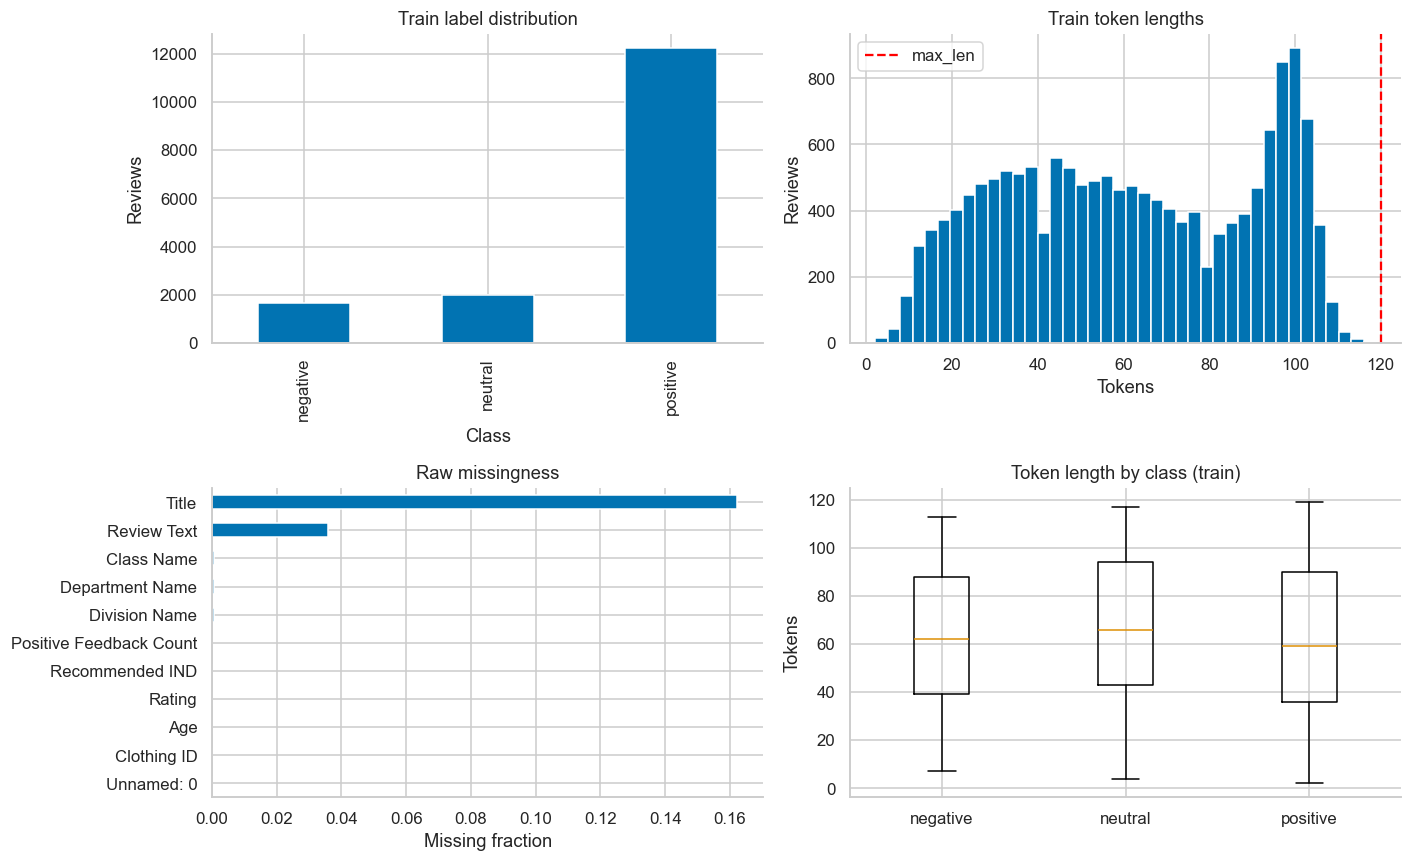

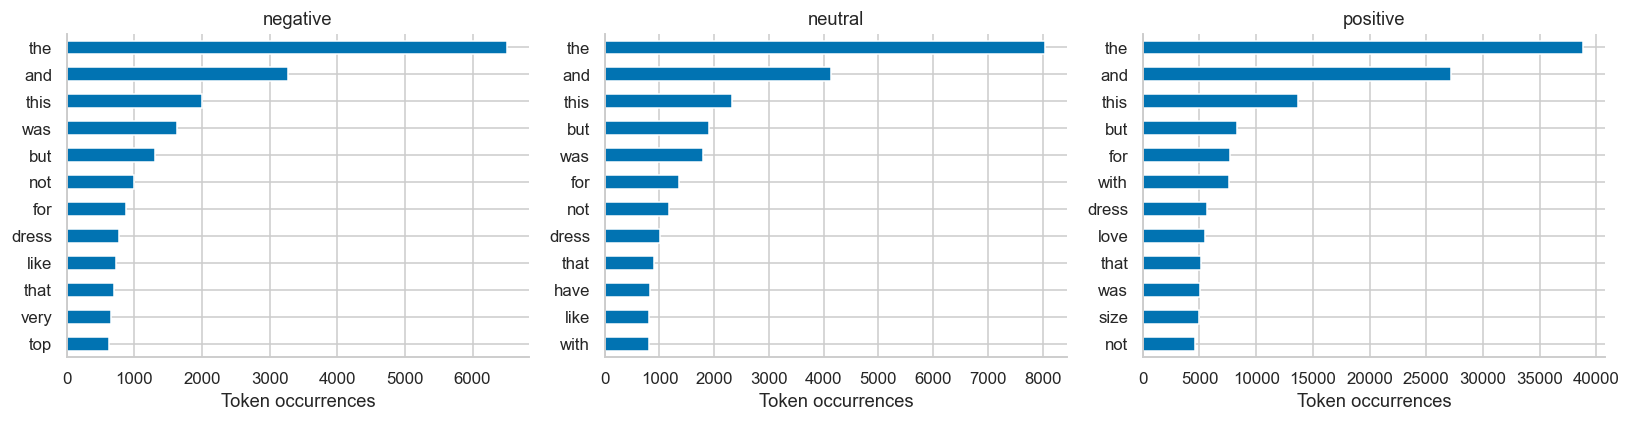

In [80]:
# Purpose: inspect class imbalance, review length, frequent words, and missing values in training/source data.
fig, axes = plt.subplots(2,2,figsize=(13,8))
train_df['label'].value_counts().sort_index().rename(index=dict(enumerate(LABELS))).plot.bar(ax=axes[0,0])
axes[0,0].set(title='Train label distribution',ylabel='Reviews',xlabel='Class')
lengths_raw = train_df.text.map(lambda text:len(tokenize(text)))
axes[0,1].hist(lengths_raw,bins=40)
axes[0,1].axvline(CFG['max_len'],color='red',linestyle='--',label='max_len')
axes[0,1].set(title='Train token lengths',xlabel='Tokens',ylabel='Reviews'); axes[0,1].legend()
raw_reviews.isna().mean().sort_values().plot.barh(ax=axes[1,0])
axes[1,0].set(title='Raw missingness',xlabel='Missing fraction')
length_by_class = [train_df.loc[train_df.label==i,'text'].map(lambda t:len(tokenize(t))) for i in range(3)]
axes[1,1].boxplot(length_by_class,tick_labels=LABELS,showfliers=False)
axes[1,1].set(title='Token length by class (train)',ylabel='Tokens')
finish_figure('reviews_eda')
fig, axes = plt.subplots(1,3,figsize=(15,4))
for label,ax in enumerate(axes):
    counts = Counter(token for text in train_df.loc[train_df.label==label,'text']
                     for token in tokenize(text) if len(token)>2)
    pd.Series(dict(counts.most_common(12))).sort_values().plot.barh(ax=ax)
    ax.set(title=LABELS[label],xlabel='Token occurrences')
finish_figure('reviews_top_words')


### C4. Vocabulary, embedding, PAD, and UNK

Build the vocabulary only from the **training data actually used for training**, never from validation or test.
`PAD=0` is a padding position; `UNK=1` represents an unseen token. IDs are lookup indices, not numeric quantities: ID 100 does not mean twice as much as ID 50.
The embedding learns a table $E_{table}\in\mathbb R^{V\times E}$; a token ID selects one row.

Keep at most `max_len` leading tokens; pad shorter sequences on the right. **Padding must be ignored by the recurrent layers**:
Keras uses `Embedding(mask_zero=True)` and passes a mask; PyTorch uses `pack_padded_sequence` with true lengths.
If the hidden state is read at a final PAD position without masking, padding can affect the representation.
The first four Keras layers return the full sequence (`return_sequences=True`); the fifth returns the final valid hidden state.

Report OOV rate = tokens outside the vocabulary / all observed tokens, and truncation rate = reviews longer than the limit.
Validation/test rates describe the protocol's limitations after the configuration has been fixed.

In [81]:
# Purpose: learn vocabulary from training data, create tensors for both frameworks, and export the tokenizer.
word_counts = Counter(token for text in train_df.text for token in tokenize(text))
ordered_words = sorted(word_counts,key=lambda word:(-word_counts[word],word))[:CFG['vocab']-2]
vocab = {'<PAD>':0,'<UNK>':1,**{word:i+2 for i,word in enumerate(ordered_words)}}
TEXT = {}
quality_rows = []
for split,frame in [('train',train_df),('val',val_df),('test',test_df)]:
    ids,lengths = encode_texts(frame.text.tolist(),vocab,CFG['max_len'])
    TEXT[split] = {'X':ids,'lengths':lengths,'y':frame.label.to_numpy(dtype=np.int64)}
    tokens = [token for text in frame.text for token in tokenize(text)]
    quality_rows.append({'split':split,'samples':len(frame),
        'OOV_rate':sum(token not in vocab for token in tokens)/max(1,len(tokens)),
        'truncated_rate':float(frame.text.map(lambda t:len(tokenize(t))>CFG['max_len']).mean())})
    assert ids.shape==(len(frame),CFG['max_len']) and np.all(lengths>0)
    assert all(np.all(row[length:]==0) for row,length in zip(ids,lengths))
counts = np.bincount(TEXT['train']['y'],minlength=3)
CLASS_WEIGHTS = (len(train_df)/(3*counts)).astype('float32')
save_json(MODEL_DIR/'tokenizer.json',{'vocab':vocab,'max_len':CFG['max_len'],
    'labels':LABELS,'normalization':'NFKC/html/lower/english-apostrophe-number-punctuation-v1'})
display(pd.DataFrame(quality_rows)); display(pd.DataFrame({'class':LABELS,'weight':CLASS_WEIGHTS}))
example_tokens = tokenize(train_df.text.iloc[0])[:15]
display(pd.DataFrame({'token':example_tokens,'id':[vocab.get(t,1) for t in example_tokens]}))
print('IDs shape:',TEXT['train']['X'].shape,'| Embedding shape after lookup:',
      (CFG['batch'],CFG['max_len'],CFG['embedding']))


,split,samples,OOV_rate,truncated_rate
0,train,15843,0.000000,0.0
1,val,3395,0.005318,0.0
2,test,3396,0.005394,0.0


,class,weight
0,negative,3.185163
1,neutral,2.672571
2,positive,0.432550


,token,id
0,i,3
1,got,92
2,this,8
3,top,27
4,in,10
5,an,62
6,xs,100
7,and,4
8,the,2
9,fit,28


IDs shape: (15843, 120) | Embedding shape after lookup: (32, 120, 64)


# D. Dataset 2 · Forecasting AAPL closing prices

### D1. Source, OHLCV meanings, and forecast timing

- **Open:** opening price; **High/Low:** highest/lowest price during the session; **Close:** closing price.
- **Volume:** number of shares traded during the session, not a monetary price.
- **Return:** relative change between consecutive closing prices.
- **Input:** completed sessions through time $t$; **target:** $Close_{t+1}$.
- Using High/Low/Volume from session $t$ is valid **after session $t$ closes**; it is not valid for a claim that the forecast was made before session $t$ opened.

This CSV does not provide a separate `Adj Close` column in this protocol. We use the provided price and do not claim that it is fully adjusted for dividends or splits.
The audit checks for unusual jumps and valid OHLC relationships. If a very large jump appears, investigate corporate actions with another source;
the notebook does not silently remove or interpolate that jump.

In [82]:
# Purpose: keep AAPL only, validate the schema, and detect price-data issues.
raw_stock = pd.read_csv(stock_path)
raw_stock.columns = raw_stock.columns.str.strip().str.lower()
assert {'date','open','high','low','close','volume','name'}.issubset(raw_stock.columns)
stock_raw = raw_stock.loc[raw_stock['name'].eq(CFG['ticker'])].copy()
assert len(stock_raw)>300, 'Not enough ticker data for this experiment.'
stock_raw['date'] = pd.to_datetime(stock_raw['date'],errors='coerce')
for col in ['open','high','low','close','volume']:
    stock_raw[col] = pd.to_numeric(stock_raw[col],errors='coerce')
print('Raw ticker rows:',len(stock_raw),'| duplicate dates:',stock_raw.date.duplicated().sum())
assert not stock_raw.date.duplicated().any(), 'Duplicate dates: inspect the source before deciding whether to keep or remove rows.'
missing_stock = stock_raw.isna().sum()
display(missing_stock.to_frame('missing'))
stock_raw = stock_raw.dropna(subset=['date','open','high','low','close','volume']).sort_values('date').reset_index(drop=True)
assert (stock_raw[['open','high','low','close']]>0).all().all()
assert (stock_raw.volume>=0).all()
assert (stock_raw.high+1e-7>=stock_raw[['open','close','low']].max(axis=1)).all(), 'Invalid OHLC values.'
assert (stock_raw.low-1e-7<=stock_raw[['open','close','high']].min(axis=1)).all(), 'Invalid OHLC values.'
large_moves = stock_raw.loc[stock_raw.close.pct_change().abs()>.30,['date','close']]
print('Date range:',stock_raw.date.min(),'→',stock_raw.date.max())
print('Moves larger than 30% to review:',len(large_moves)); display(large_moves)
stock_raw.to_csv(PROCESSED/'stock_clean.csv',index=False)
save_json(PROCESSED/'stock_audit.json',{'raw_ticker_rows':int((raw_stock.name==CFG['ticker']).sum()),
    'clean_rows':len(stock_raw),'start':str(stock_raw.date.min()),'end':str(stock_raw.date.max()),
    'large_move_count':len(large_moves),'dropped_missing_rows':int((raw_stock.name==CFG['ticker']).sum()-len(stock_raw))})
del raw_stock


Raw ticker rows: 1259 | duplicate dates: 0


,missing
date,0
open,0
high,0
low,0
close,0
volume,0
name,0


Date range: 2013-02-08 00:00:00 → 2018-02-07 00:00:00
Moves larger than 30% to review: 0


,date,close


### D2. Causal feature engineering

The following features use only current and past information; rolling windows do not use `center=True` and are not back-filled from the future.

| Feature | Formula / meaning |
|---|---|
| open, high, low, close | Prices observed in the session |
| log_volume | $\log(1+Volume_t)$ reduces scale differences and handles zero volume |
| return_1d | $Close_t/Close_{t-1}-1$ |
| range_pct | $(High_t-Low_t)/Close_t$ |
| body_pct | $(Close_t-Open_t)/Open_t$ |
| ma5_gap | $Close_t/MA_5(t)-1$, where $MA_5$ is the mean of the five closes through session $t$ |
| ma20_gap | Same calculation over 20 sessions |
| volatility20 | Sample standard deviation of the latest 20 daily returns; not annualized |

Drop leading rows that lack sufficient history after feature calculation. Do not use `shift(-1)` to create an input feature.
Some features are strongly related; a heatmap can reveal redundancy but does not establish causality.
More features do not necessarily improve performance; all four stock models use the same feature set.

In [83]:
# A7_EXPORT: stock_features
# Purpose: calculate features consistently during training and when the web app receives new OHLCV data.
def engineer_stock(frame):
    """Create features using information available through each session; input must include date and OHLCV."""
    frame = frame.copy().sort_values('date').reset_index(drop=True)
    if frame['date'].duplicated().any(): raise ValueError('Duplicate trading dates.')
    frame['log_volume'] = np.log1p(frame['volume'])
    frame['return_1d'] = frame['close'].pct_change(fill_method=None)
    frame['range_pct'] = (frame['high']-frame['low'])/frame['close']
    frame['body_pct'] = (frame['close']-frame['open'])/frame['open']
    frame['ma5_gap'] = frame['close']/frame['close'].rolling(5).mean()-1
    frame['ma20_gap'] = frame['close']/frame['close'].rolling(20).mean()-1
    frame['volatility20'] = frame['return_1d'].rolling(20).std(ddof=1)
    features = ['open','high','low','close','log_volume','return_1d',
                'range_pct','body_pct','ma5_gap','ma20_gap','volatility20']
    frame = frame.replace([np.inf,-np.inf],np.nan).dropna(subset=features).reset_index(drop=True)
    return frame, features


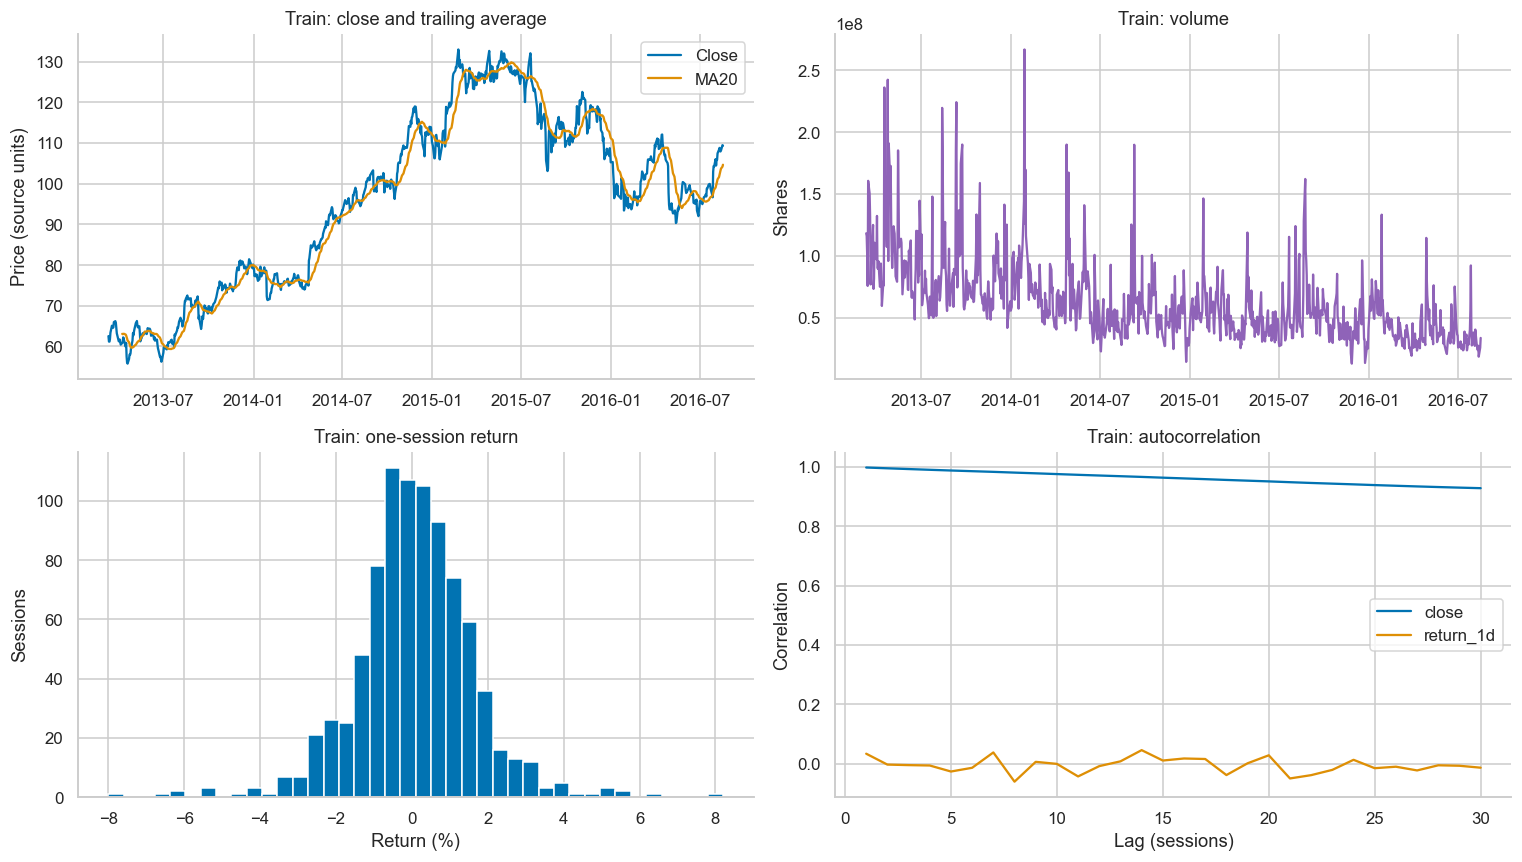

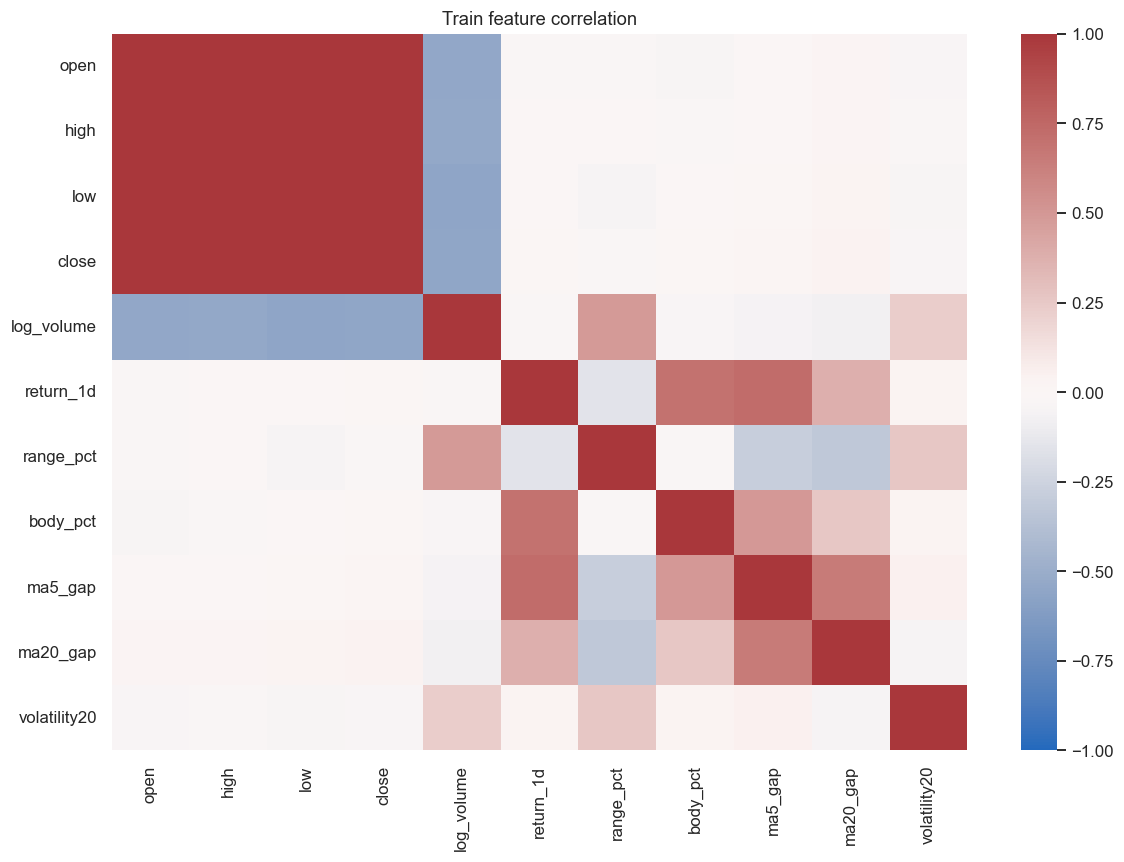

In [84]:
# Purpose: visualize price movement, volume, returns, autocorrelation, and correlations in training data.
stock, FEATURES = engineer_stock(stock_raw)
N_STOCK = len(stock)
TRAIN_END, VAL_END = int(.70*N_STOCK), int(.85*N_STOCK)
stock_train_view = stock.iloc[:TRAIN_END]
fig, axes = plt.subplots(2,2,figsize=(14,8))
axes[0,0].plot(stock_train_view.date,stock_train_view.close,label='Close')
axes[0,0].plot(stock_train_view.date,stock_train_view.close.rolling(20).mean(),label='MA20')
axes[0,0].set(title='Train: close and trailing average',ylabel='Price (source units)'); axes[0,0].legend()
axes[0,1].plot(stock_train_view.date,stock_train_view.volume,color='#8f63b8')
axes[0,1].set(title='Train: volume',ylabel='Shares')
axes[1,0].hist(100*stock_train_view.return_1d,bins=40)
axes[1,0].set(title='Train: one-session return',xlabel='Return (%)',ylabel='Sessions')
for col in ['close','return_1d']:
    axes[1,1].plot(range(1,31),[stock_train_view[col].autocorr(i) for i in range(1,31)],label=col)
axes[1,1].set(title='Train: autocorrelation',xlabel='Lag (sessions)',ylabel='Correlation'); axes[1,1].legend()
finish_figure('stock_train_eda')
plt.figure(figsize=(11,8)); sns.heatmap(stock_train_view[FEATURES].corr(),cmap='vlag',center=0,vmin=-1,vmax=1)
plt.title('Train feature correlation'); finish_figure('stock_correlations')


### D3. Time split, scaling, and window construction

For $n$ valid feature rows, split train/validation/test in chronological order: 70/15/15.
A sample with **target index $i$** uses:
$$X_i=[x_{i-L},\ldots,x_{i-1}]\in\mathbb R^{L\times F},\quad y_i=Close_i.$$
Training targets have $i<train\_end$; validation targets satisfy $train\_end\leq i<val\_end$; test targets have $i\geq val\_end$.
The first validation window can include training history. Later test windows can include previously observed test sessions.
This is **rolling one-step evaluation using the true historical prices**, not a multi-session autoregressive forecast from one start date.

StandardScaler: $z=(x-\mu_{train})/s_{train}$. Here $\mu$ is the training mean and $s$ is the training standard deviation.
Feature and target scalers are separate and are fit on training data only. Inverse transform predictions as
$\hat y=\hat z\,s_{y,train}+\mu_{y,train}$. Test prices can fall outside the training range; do not clip them to hide distribution shift.

Training windows may be shuffled during optimization because each window is an independent example. The time order **inside** each window stays unchanged.
Validation/test are not shuffled, and dates are retained for correctly ordered charts.

{'train': (837, 30, 11), 'val': (186, 30, 11), 'test': (186, 30, 11)}


,date,open,high,low,close,log_volume,return_1d,range_pct,body_pct,ma5_gap,ma20_gap,volatility20
25,2013-04-16,60.2242,60.9442,60.0814,60.8914,18.149162,0.015220,0.014169,0.011079,-0.006854,-0.029218,0.013878
26,2013-04-17,60.0385,60.0857,56.8728,57.5428,19.279931,-0.054993,0.055835,-0.041568,-0.046862,-0.077172,0.018064
27,2013-04-18,57.8557,57.9699,55.6774,56.0071,18.930134,-0.026688,0.040932,-0.031952,-0.053358,-0.095581,0.018653
28,2013-04-19,55.4242,57.0857,55.0142,55.7899,18.840669,-0.003878,0.037130,0.006598,-0.038800,-0.092578,0.018565
29,2013-04-22,56.0914,57.4571,55.8964,56.9528,18.491496,0.020844,0.027403,0.015357,-0.008427,-0.066808,0.018609


Target lies outside the input window: {'date': Timestamp('2013-04-23 00:00:00'), 'close': 58.0185}


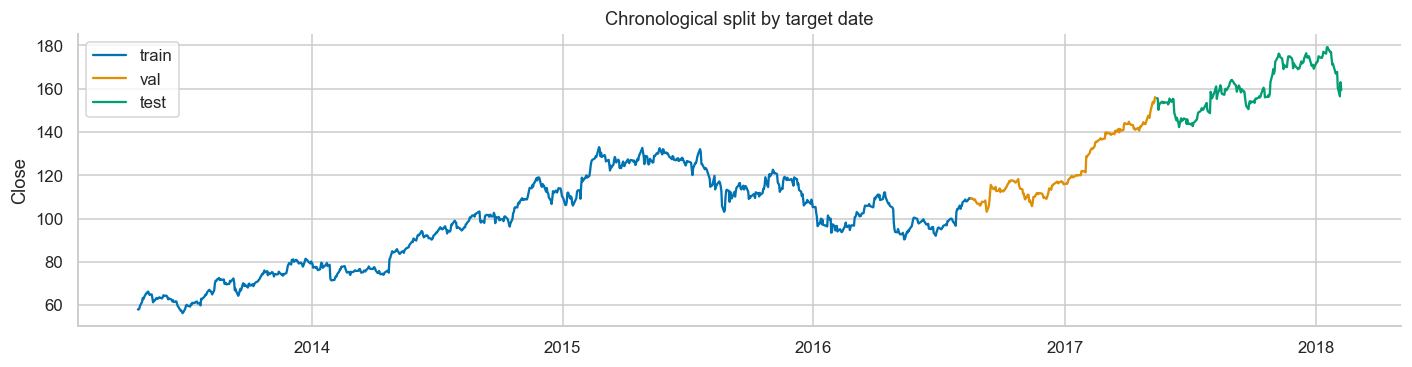

In [85]:
# Purpose: fit preprocessing on training data, then create samples with auditable target indices.
L = CFG['lookback']
x_scaler = StandardScaler().fit(stock.iloc[:TRAIN_END][FEATURES])
y_scaler = StandardScaler().fit(stock.iloc[L:TRAIN_END][['close']])
X_scaled = x_scaler.transform(stock[FEATURES]).astype('float32')
y_scaled = y_scaler.transform(stock[['close']]).astype('float32').ravel()
target_indices = np.arange(L,len(stock))
X_windows = np.stack([X_scaled[i-L:i] for i in target_indices])
y_windows = y_scaled[target_indices]
STOCK = {}
for split, mask in [('train',target_indices<TRAIN_END),
                    ('val',(target_indices>=TRAIN_END)&(target_indices<VAL_END)),
                    ('test',target_indices>=VAL_END)]:
    positions = np.flatnonzero(mask)
    if PRESET=='smoke': positions = positions[:min(64,len(positions))]
    idx = target_indices[positions]
    STOCK[split] = {'X':X_windows[positions], 'y':y_windows[positions],
        'lengths':np.full(len(idx),L,dtype=np.int64), 'idx':idx,
        'dates':stock.iloc[idx].date.dt.strftime('%Y-%m-%d').to_numpy(),
        'true':stock.close.to_numpy()[idx], 'previous':stock.close.to_numpy()[idx-1]}
    assert np.isfinite(STOCK[split]['X']).all()
assert STOCK['train']['idx'].max()<STOCK['val']['idx'].min()<STOCK['test']['idx'].min()
assert stock.date.iloc[STOCK['test']['idx'][0]-1]<stock.date.iloc[STOCK['test']['idx'][0]]
joblib.dump({'x':x_scaler,'y':y_scaler,'features':FEATURES,'lookback':L},MODEL_DIR/'stock_preprocess.joblib')
pd.concat([pd.DataFrame({'target_index':value['idx'],'date':value['dates'],'split':name})
           for name,value in STOCK.items()]).to_csv(PROCESSED/'stock_split_manifest.csv',index=False)
print({name:value['X'].shape for name,value in STOCK.items()})
example_i = STOCK['train']['idx'][0]
display(stock.iloc[example_i-L:example_i][['date']+FEATURES].tail(5))
print('Target lies outside the input window:',stock.iloc[example_i][['date','close']].to_dict())
fig,ax=plt.subplots(figsize=(13,3.5))
for split,values in STOCK.items(): ax.plot(pd.to_datetime(values['dates']),values['true'],label=split)
ax.set(title='Chronological split by target date',ylabel='Close'); ax.legend()
finish_figure('stock_time_split')


# E. Implementing and training five-layer RNN/LSTM models

### E1. Architecture mapping across frameworks

| Component | PyTorch | Keras/TensorFlow |
|---|---|---|
| Review input | `Embedding(V,E,padding_idx=0)` | `Embedding(V,E,mask_zero=True)` |
| 5-layer RNN | `nn.RNN(..., num_layers=5, batch_first=True)` | 5 consecutive `SimpleRNN` layers |
| 5-layer LSTM | `nn.LSTM(..., num_layers=5, batch_first=True)` | 5 consecutive `LSTM` layers |
| PAD | PackedSequence with true lengths | Mask from Embedding |
| Final hidden state | `h_n[-1]` | Fifth layer with `return_sequences=False` |
| Dropout | Only after the fifth hidden layer | Only after the fifth hidden layer |
| Head | Linear H→3 or H→1 | Dense H→3 or H→1 |

No bidirectionality, attention, or extra recurrent layer is used, keeping the comparison focused on the requested architectures.
Input/head weights use Glorot initialization and recurrent weights use orthogonal initialization; the LSTM forget bias sums to 1 in both frameworks.
PyTorch's two biases change parameter count and optimization relative to Keras. Random-number generators and CPU kernels also differ;
weights and results are not expected to match exactly. Stock inputs have no PAD, and a value of zero after scaling is **not** masked.

In [86]:
# A7_EXPORT: torch_model
# Purpose: define an explicitly configured model that can be rebuilt from its state_dict for web inference.
class StackedRecurrent(nn.Module):
    """Five-layer RNN/LSTM; reviews use packed sequences and stock uses complete numeric sequences."""
    def __init__(self, config):
        super().__init__()
        self.config = dict(config)
        self.task = config['task']
        self.kind = config['kind']
        H = config['hidden']
        if self.task == 'text':
            self.embedding = nn.Embedding(config['vocab_size'],config['embedding'],padding_idx=0)
            input_dim = config['embedding']
        else:
            self.embedding = None
            input_dim = config['input_dim']
        layer_type = nn.RNN if self.kind=='RNN' else nn.LSTM
        self.core = layer_type(input_dim,H,num_layers=5,batch_first=True,dropout=0.0,bidirectional=False)
        self.dropout = nn.Dropout(config['head_dropout'])
        self.head = nn.Linear(H,3 if self.task=='text' else 1)
        self.reset_parameters()

    def reset_parameters(self):
        """Initialization aligned with Keras calculations: zero biases and total forget bias = 1."""
        if self.embedding is not None:
            nn.init.uniform_(self.embedding.weight,-.05,.05)
            with torch.no_grad(): self.embedding.weight[0].zero_()
        for name,parameter in self.core.named_parameters():
            if 'weight_ih' in name: nn.init.xavier_uniform_(parameter)
            elif 'weight_hh' in name: nn.init.orthogonal_(parameter)
            else:
                nn.init.zeros_(parameter)
                if self.kind=='LSTM' and 'bias_ih' in name:
                    with torch.no_grad(): parameter[self.config['hidden']:2*self.config['hidden']].fill_(1.)
        nn.init.xavier_uniform_(self.head.weight)
        nn.init.zeros_(self.head.bias)

    def forward(self, x, lengths=None):
        """Return logits or a standardized target; do not apply softmax before cross-entropy."""
        if self.task=='text':
            sequence = self.embedding(x.long())
            if lengths is None: lengths = (x!=0).sum(dim=1).clamp(min=1)
            sequence = pack_padded_sequence(sequence,lengths.cpu(),batch_first=True,enforce_sorted=False)
        else:
            sequence = x.float()
        _,state = self.core(sequence)
        hidden = state[0] if self.kind=='LSTM' else state
        return self.head(self.dropout(hidden[-1]))


In [87]:
# Purpose: build exactly five Keras layers using standard layers that load without custom_objects.
def build_keras_model(config):
    """Build the Keras equivalent of StackedRecurrent, with logits/linear output and no activation."""
    if config['task']=='text':
        inputs = tf.keras.Input(shape=(None,),dtype='int32',name='token_ids')
        value = tf.keras.layers.Embedding(config['vocab_size'],config['embedding'],
                    mask_zero=True,embeddings_initializer=tf.keras.initializers.RandomUniform(-.05,.05),
                    name='embedding')(inputs)
    else:
        inputs = tf.keras.Input(shape=(config['lookback'],config['input_dim']),name='stock_window')
        value = inputs
    for layer in range(5):
        kwargs = dict(units=config['hidden'],return_sequences=(layer<4),
            kernel_initializer='glorot_uniform',recurrent_initializer='orthogonal',
            bias_initializer='zeros',dropout=0.,recurrent_dropout=0.,name=f'recurrent_{layer+1}')
        if config['kind']=='RNN':
            value = tf.keras.layers.SimpleRNN(activation='tanh',**kwargs)(value)
        else:
            value = tf.keras.layers.LSTM(activation='tanh',recurrent_activation='sigmoid',
                                         unit_forget_bias=True,**kwargs)(value)
    value = tf.keras.layers.Dropout(config['head_dropout'],name='head_dropout')(value)
    outputs = tf.keras.layers.Dense(3 if config['task']=='text' else 1,name='head')(value)
    model = tf.keras.Model(inputs,outputs,name=f"{config['task']}_{config['kind']}_5layers")
    loss = (tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
            if config['task']=='text' else tf.keras.losses.MeanSquaredError())
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=CFG['lr'],epsilon=CFG['adam_eps'],
                                                    global_clipnorm=CFG['clip']),loss=loss)
    return model


def model_config(task, kind):
    """Capture architecture parameters needed to restore the model, independent of globals during loading."""
    return {'task':task,'kind':kind,'layers':5,'hidden':CFG['hidden'],'embedding':CFG['embedding'],
            'head_dropout':CFG['head_dropout'],'vocab_size':len(vocab),'input_dim':len(FEATURES),
            'lookback':CFG['lookback'],'max_len':CFG['max_len']}


def expected_parameters(config, framework):
    """Check parameter counts for the embedding, five recurrent layers, and output head."""
    H = config['hidden']; bias_count = 2 if framework=='PyTorch' else 1
    D = config['embedding'] if config['task']=='text' else config['input_dim']
    gate_count = 1 if config['kind']=='RNN' else 4
    rec = gate_count*(D*H+H*H+bias_count*H+4*(2*H*H+bias_count*H))
    embed = config['vocab_size']*config['embedding'] if config['task']=='text' else 0
    C = 3 if config['task']=='text' else 1
    return embed+rec+H*C+C


### E2. Checks before training

These checks validate the computation contract: exactly five recurrent layers, correct output shape, correct parameter count, and—during evaluation—adding PAD does not change a review prediction.
Predictions are not compared across frameworks because their weights have not been synchronized.
Shape and parameter-count tables are generated from the actual models, not entered by hand.

In [88]:
# Purpose: catch layer-count, shape, or padding errors before spending time on training.
architecture_rows=[]
for task in ['text','stock']:
    data = TEXT if task=='text' else STOCK
    for kind in ['RNN','LSTM']:
        config = model_config(task,kind)
        seed_all(42)
        tm = StackedRecurrent(config).eval()
        tx = torch.as_tensor(data['train']['X'][:3])
        tl = torch.as_tensor(data['train']['lengths'][:3])
        with torch.no_grad(): ty=tm(tx,tl)
        assert tm.core.num_layers==5 and ty.shape==(3,3 if task=='text' else 1)
        tp = sum(p.numel() for p in tm.parameters())
        assert tp==expected_parameters(config,'PyTorch')
        if task=='text':
            padded = torch.cat([tx,torch.zeros((3,7),dtype=tx.dtype)],dim=1)
            with torch.no_grad(): assert torch.allclose(ty,tm(padded,tl),atol=1e-6)
        km = build_keras_model(config)
        kx = data['train']['X'][:3]
        ky = km(kx,training=False).numpy()
        assert sum(isinstance(l,(tf.keras.layers.SimpleRNN,tf.keras.layers.LSTM)) for l in km.layers)==5
        assert km.count_params()==expected_parameters(config,'Keras')
        if task=='text':
            padded = np.pad(kx,((0,0),(0,7)))
            np.testing.assert_allclose(ky,km(padded,training=False).numpy(),atol=1e-5)
        for framework,p in [('PyTorch',tp),('Keras',km.count_params())]:
            architecture_rows.append({'task':task,'kind':kind,'framework':framework,'layers':5,'parameters':p})
        del tm,km
        tf.keras.backend.clear_session(); gc.collect()
architecture_table=pd.DataFrame(architecture_rows)
display(architecture_table)
architecture_table.to_csv(OUT/'architecture_parameters.csv',index=False)


,task,kind,framework,layers,parameters
0,text,RNN,PyTorch,5,798387
1,text,RNN,Keras,5,798147
2,text,LSTM,PyTorch,5,871251
3,text,LSTM,Keras,5,870291
4,stock,RNN,PyTorch,5,21793
5,stock,RNN,Keras,5,21553
6,stock,LSTM,PyTorch,5,87025
7,stock,LSTM,Keras,5,86065


### E3. Evaluation metrics defined before examining results

**Classification:** for class $c$, TP is a correct prediction of that class, FP is an incorrect prediction assigned to that class, and FN is a missed example of that class.
$$Precision_c=\frac{TP_c}{TP_c+FP_c},\quad Recall_c=\frac{TP_c}{TP_c+FN_c},\quad
F1_c=\frac{2Precision_cRecall_c}{Precision_c+Recall_c}.$$
Undefined zero-division values are set to 0 in the report. **Macro-F1** is the unweighted mean of the three class F1 values; it is the primary metric because a majority class cannot dominate it.
**Weighted-F1** weights each class by its sample count. **Accuracy** = correct predictions / total examples.
**Balanced accuracy** = mean recall across classes.
**Log loss** $=-N^{-1}\sum_i\log p_{i,y_i}$ penalizes incorrect predictions made with excessive confidence; lower is better.
One-vs-rest ROC plots TPR=Recall against FPR=$FP/(FP+TN)$; PR plots precision against recall and is useful for rare classes.
A high ROC-AUC does not guarantee high precision; AP is precision weighted by recall increments and is not identical to every definition of PR-curve area.

**Stock (original price units):**
$$MAE=\frac1N\sum_i|y_i-\hat y_i|,\quad RMSE=\sqrt{\frac1N\sum_i(y_i-\hat y_i)^2},$$
$$MAPE=\frac{100}{N}\sum_i\left|\frac{y_i-\hat y_i}{y_i}\right|,\quad
R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}.$$
Lower MAE/RMSE is better; they are expressed in price units. MAPE is a percentage and is unsuitable when targets are near zero; here prices are positive.
$R^2$ can be negative; $R^2=0$ means the sum of squared errors equals that of predicting the evaluation-set target mean.
Do not confuse this mean-based reference in $R^2$ with the persistence baseline that predicts the previous session's price.

**Three-state directional accuracy:** compare the signs of $\hat y_i-Close_{i-1}$ and $y_i-Close_{i-1}$;
negative=down, 0=flat, positive=up. Persistence always predicts flat, so it must not be labeled as a down prediction.
**MAE improvement %** $=100(MAE_{baseline}-MAE_{model})/MAE_{baseline}$; a negative value means worse than baseline.
Do not compare F1 directly with RMSE or average metrics across the two different tasks.

In [89]:
# Purpose: share metric calculations so frameworks are not evaluated with different formulas.
def probabilities(logits):
    """Numerically stable softmax for classification logits; used only during evaluation/inference."""
    logits=np.asarray(logits,dtype=np.float64)
    exponent=np.exp(logits-logits.max(axis=1,keepdims=True))
    return exponent/exponent.sum(axis=1,keepdims=True)


def classification_metrics(y, prob):
    """Three-class metrics in label order 0,1,2; probabilities have shape N×3."""
    pred=prob.argmax(axis=1)
    encoded=label_binarize(y,classes=[0,1,2])
    return {'accuracy':accuracy_score(y,pred),'balanced_accuracy':balanced_accuracy_score(y,pred),
            'macro_f1':f1_score(y,pred,labels=[0,1,2],average='macro',zero_division=0),
            'weighted_f1':f1_score(y,pred,average='weighted',zero_division=0),
            'log_loss':log_loss(y,prob,labels=[0,1,2]),
            'roc_auc_macro_ovr':roc_auc_score(y,prob,multi_class='ovr',average='macro'),
            'average_precision_macro':average_precision_score(encoded,prob,average='macro')}


def direction(true_or_pred, previous):
    """Encode down/flat/up as -1/0/1; a small tolerance avoids floating-point sign artifacts."""
    delta=np.asarray(true_or_pred)-np.asarray(previous)
    return np.where(np.isclose(delta,0,atol=1e-8,rtol=0),0,np.sign(delta)).astype(int)


def regression_metrics(y,pred,previous):
    """Evaluate inverse-transformed prices; every comparison uses the same target dates."""
    y=np.asarray(y).ravel(); pred=np.asarray(pred).ravel()
    return {'MAE':mean_absolute_error(y,pred),'RMSE':np.sqrt(mean_squared_error(y,pred)),
            'MAPE_percent':100*np.mean(np.abs((y-pred)/y)), 'R2':r2_score(y,pred),
            'directional_accuracy':float(np.mean(direction(y,previous)==direction(pred,previous))),
            'median_AE':float(np.median(np.abs(y-pred))), 'p95_AE':float(np.quantile(np.abs(y-pred),.95))}


def model_metrics(task, raw_output, split='test'):
    """Convert internal outputs to probabilities or real prices before calculating metrics."""
    if task=='text':
        prob=probabilities(raw_output)
        return classification_metrics(TEXT[split]['y'],prob),prob
    pred=y_scaler.inverse_transform(np.asarray(raw_output).reshape(-1,1)).ravel()
    return regression_metrics(STOCK[split]['true'],pred,STOCK[split]['previous']),pred


### E4. PyTorch training loop

For each mini-batch: clear gradients → forward pass → loss → backward pass → measure/clip global norm → Adam update.
Gradients must be cleared because PyTorch accumulates them by default. `model.train()` enables dropout; `eval()` disables it.
Validation runs under `torch.no_grad()` and does not update parameters. The checkpoint always stores the best validation model.
`DataLoader(num_workers=0)` avoids notebook multiprocessing issues on Windows.

In [90]:
# Purpose: train with early stopping and real histories; never use test data to select an epoch.
def train_torch(config, data, seed, checkpoint):
    """Train one CPU model; return the best-restored model, history, and elapsed time."""
    seed_all(seed)
    model=StackedRecurrent(config)
    optimizer=torch.optim.Adam(model.parameters(),lr=CFG['lr'],eps=CFG['adam_eps'])
    weights=torch.as_tensor(CLASS_WEIGHTS,dtype=torch.float32)
    tensors=torch.utils.data.TensorDataset(torch.as_tensor(data['train']['X']),
                torch.as_tensor(data['train']['lengths']),torch.as_tensor(data['train']['y']))
    generator=torch.Generator().manual_seed(seed)
    loader=torch.utils.data.DataLoader(tensors,batch_size=CFG['batch'],shuffle=True,
                                      num_workers=0,generator=generator)
    history=[]; best=float('inf'); waiting=0; best_epoch=0
    started=time.perf_counter()
    for epoch in range(1,CFG['epochs']+1):
        epoch_start=time.perf_counter(); model.train(); total=0.; n=0; norms=[]
        for x,lengths,y in loader:
            optimizer.zero_grad(set_to_none=True)
            output=model(x,lengths)
            if config['task']=='text':
                per_sample=nn.functional.cross_entropy(output,y.long(),reduction='none')
                loss=(per_sample*weights[y.long()]).mean()
            else:
                loss=nn.functional.mse_loss(output.squeeze(-1),y.float())
            if not torch.isfinite(loss): raise FloatingPointError('Loss is not finite; inspect the data and learning rate.')
            loss.backward()
            norm=nn.utils.clip_grad_norm_(model.parameters(),CFG['clip'])
            norms.append(float(norm)); optimizer.step()
            total+=float(loss.detach())*len(y); n+=len(y)
        model.eval(); val_total=0.; val_n=0
        with torch.no_grad():
            for start in range(0,len(data['val']['y']),CFG['batch']):
                sl=slice(start,start+CFG['batch'])
                out=model(torch.as_tensor(data['val']['X'][sl]),torch.as_tensor(data['val']['lengths'][sl]))
                y=torch.as_tensor(data['val']['y'][sl])
                loss=(nn.functional.cross_entropy(out,y.long()) if config['task']=='text'
                      else nn.functional.mse_loss(out.squeeze(-1),y.float()))
                val_total+=float(loss)*len(y); val_n+=len(y)
        val_loss=val_total/val_n
        row={'epoch':epoch,'train_loss':total/n,'val_loss':val_loss,
             'epoch_seconds':time.perf_counter()-epoch_start,'gradient_norm_before_clip':float(np.mean(norms))}
        history.append(row)
        print(f"Epoch {epoch:02d} | train={row['train_loss']:.5f} | val={val_loss:.5f} | {row['epoch_seconds']:.1f}s")
        if val_loss<best-CFG['min_delta']:
            best=val_loss; best_epoch=epoch; waiting=0
            torch.save({'state_dict':model.state_dict(),'config':config,'seed':seed},checkpoint)
        else:
            waiting+=1
            if waiting>=CFG['patience']: break
    elapsed=time.perf_counter()-started
    saved=torch.load(checkpoint,map_location='cpu',weights_only=True)
    model.load_state_dict(saved['state_dict']); model.eval()
    return model,history,elapsed,best_epoch


def predict_torch(model, split):
    """Run batched inference to avoid loading the entire test set into intermediate memory."""
    outputs=[]; model.eval()
    with torch.no_grad():
        for start in range(0,len(split['y']),CFG['batch']):
            sl=slice(start,start+CFG['batch'])
            outputs.append(model(torch.as_tensor(split['X'][sl]),
                                 torch.as_tensor(split['lengths'][sl])).numpy())
    return np.concatenate(outputs)


### E5. Keras training loop

`fit()` packages the forward pass, backward pass, and update. `EarlyStopping(restore_best_weights=True)` restores the best weights.
A `tf.data.Dataset` uses a small thread count and batch/sample weights consistent with PyTorch.
Validation has no sample weights. Training loss includes dropout and class weights while validation loss does not;
a higher training loss than validation loss does not by itself indicate an error.
The frameworks are not forced to have identical run times: packing, masking, graph compilation, and kernels differ.

In [91]:
# Purpose: train Keras on CPU with loss, patience, and clipping aligned with PyTorch.
class EpochTimer(tf.keras.callbacks.Callback):
    """Record per-epoch time including training and validation, excluding final model saving."""
    def on_train_begin(self, logs=None): self.times=[]
    def on_epoch_begin(self, epoch, logs=None): self.started=time.perf_counter()
    def on_epoch_end(self, epoch, logs=None): self.times.append(time.perf_counter()-self.started)


def keras_dataset(split, task, training, seed):
    """Create a compact Dataset; apply sample weights only to classification training."""
    x=split['X'].astype('int32' if task=='text' else 'float32')
    y=split['y'].astype('int32' if task=='text' else 'float32')
    if task!='text': y=y.reshape(-1,1)
    if training and task=='text':
        ds=tf.data.Dataset.from_tensor_slices((x,y,CLASS_WEIGHTS[y]))
    else: ds=tf.data.Dataset.from_tensor_slices((x,y))
    if training: ds=ds.shuffle(len(y),seed=seed,reshuffle_each_iteration=True)
    options=tf.data.Options()
    options.threading.private_threadpool_size=1
    options.threading.max_intra_op_parallelism=4
    options.experimental_deterministic=True
    return ds.batch(CFG['batch']).with_options(options).prefetch(1)


def train_keras(config, data, seed, checkpoint):
    """Train Keras and save the .keras format containing architecture and weights."""
    tf.keras.backend.clear_session(); seed_all(seed)
    model=build_keras_model(config)
    timer=EpochTimer()
    stop=tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=CFG['patience'],
        min_delta=CFG['min_delta'],restore_best_weights=True,mode='min')
    started=time.perf_counter()
    hist=model.fit(keras_dataset(data['train'],config['task'],True,seed),
        validation_data=keras_dataset(data['val'],config['task'],False,seed),
        epochs=CFG['epochs'],callbacks=[timer,stop,tf.keras.callbacks.TerminateOnNaN()],verbose=2)
    elapsed=time.perf_counter()-started
    if not np.isfinite(hist.history['val_loss']).all(): raise FloatingPointError('Keras validation loss is not finite.')
    history=[{'epoch':i+1,'train_loss':float(a),'val_loss':float(b),'epoch_seconds':float(s)}
             for i,(a,b,s) in enumerate(zip(hist.history['loss'],hist.history['val_loss'],timer.times))]
    # Callback uses min_delta; its best_epoch identifies the actual restored checkpoint.
    best_epoch=int(stop.best_epoch)+1
    model.save(checkpoint)
    return model,history,elapsed,best_epoch


def predict_keras(model, split):
    """Run direct mini-batch inference to avoid creating a thread pool for each predict call."""
    return np.concatenate([model(split['X'][start:start+CFG['batch']],training=False).numpy()
                           for start in range(0,len(split['y']),CFG['batch'])])


### E6. Inspecting hidden states and gates from the trained model

To make the mechanism inspectable, the function below reproduces a forward pass in NumPy using the trained weights.
It records hidden-state norms for all five layers over time, a layer-five hidden-state heatmap, and LSTM gates.
The final logits must match the framework within a tolerance; otherwise, execution stops to catch a gate-order, bias, or mask mismatch.
This is a **mechanism diagnostic**, not a causal explanation for a prediction.

In [92]:
# Purpose: verify that the elementary-function equations match both trained frameworks.
def trace_model(model, framework, config, sample, length):
    """Reproduce a five-layer forward pass for one sample; return hidden/gate plot data without modifying the model."""
    H=config['hidden']; T=int(length)
    if framework=='PyTorch':
        model.eval()
        if config['task']=='text': sequence=model.embedding.weight.detach().numpy()[sample[:T]]
        else: sequence=sample[:T]
        parameters=[]
        for layer in range(5):
            weights=model.core.state_dict()
            parameters.append((weights[f'weight_ih_l{layer}'].numpy().T,
                weights[f'weight_hh_l{layer}'].numpy().T,
                (weights[f'bias_ih_l{layer}']+weights[f'bias_hh_l{layer}']).numpy()))
        head=(model.head.weight.detach().numpy().T,model.head.bias.detach().numpy())
        with torch.no_grad(): reference=model(torch.as_tensor(sample[None]),torch.tensor([T])).numpy()[0]
    else:
        sequence=(model.get_layer('embedding').get_weights()[0][sample[:T]]
                  if config['task']=='text' else sample[:T])
        parameters=[model.get_layer(f'recurrent_{layer+1}').get_weights() for layer in range(5)]
        head=model.get_layer('head').get_weights()
        reference=model(sample[None],training=False).numpy()[0]
    states=np.zeros((5,T,H),dtype=np.float64)
    gate_trace={name:np.zeros((T,H)) for name in ['input','forget','candidate','output']}
    for layer,(Wx,Wh,b) in enumerate(parameters):
        h=np.zeros((1,H)); c=np.zeros((1,H))
        for t in range(T):
            x=sequence[t:t+1] if layer==0 else states[layer-1,t:t+1]
            if config['kind']=='LSTM':
                h,c,gates=lstm_cell_demo(x,h,c,Wx,Wh,b)
                if layer==4:
                    for name in gate_trace: gate_trace[name][t]=gates[name][0]
            else: h=rnn_cell_demo(x,h,Wx,Wh,b)
            states[layer,t]=h[0]
    reconstructed=states[-1,-1]@head[0]+head[1]
    np.testing.assert_allclose(reconstructed,reference,rtol=2e-4,atol=2e-4)
    return {'hidden_norms':np.linalg.norm(states,axis=-1).tolist(),
            'last_layer_hidden':states[-1].tolist(),
            'gates':{name:value.tolist() for name,value in gate_trace.items()} if config['kind']=='LSTM' else {},
            'valid_length':T,'max_output_difference':float(np.max(np.abs(reconstructed-reference)))}


### E7. Run eight experiments and save each result as it completes

Each following cell runs one dataset/framework/architecture combination for the selected seeds.
Each model saves its checkpoint, history, validation score, test predictions, metrics, and trace.
If the computer shuts down after some models finish, rerun with `REUSE_COMPLETED=True` to reuse completed models with the same configuration.
The notebook cannot resume in the middle of an interrupted epoch; an incomplete model must train again.

`training_seconds` includes training, validation, and checkpointing within PyTorch; Keras graph compilation occurs in the first epoch.
`inference_ms_per_sample` measures test prediction after one warm-up batch and excludes model loading; it is a reference measurement on the current computer.

In [93]:
# Purpose: standardize result saving, limit models kept in RAM, and support restarting.
RESULTS=[]
PREDICTIONS={}
HISTORIES={}
TRACES={}


def run_experiment(task, framework, kind, seed):
    """Run or restore one experiment; mark it complete only after all artifacts have been saved."""
    key=f'{task}_{framework.lower()}_{kind.lower()}_s{seed}'
    meta_path=OUT/f'{key}.json'
    pred_path=OUT/'predictions'/f'{key}.npy'
    history_path=OUT/'histories'/f'{key}.json'
    trace_path=OUT/'histories'/f'{key}_trace.json'
    extension='.pt' if framework=='PyTorch' else '.keras'
    checkpoint=MODEL_DIR/f'{key}{extension}'
    if REUSE_COMPLETED and all(p.exists() for p in [meta_path,pred_path,history_path,trace_path,checkpoint]):
        record=json.loads(meta_path.read_text(encoding='utf-8'))
        if record.get('status')=='complete':
            print('Reusing:',key)
            return record,np.load(pred_path),json.loads(history_path.read_text()),json.loads(trace_path.read_text())
    data=TEXT if task=='text' else STOCK
    config=model_config(task,kind)
    print('\nTraining',key,'| CPU | 5 layers')
    if framework=='PyTorch':
        model,history,elapsed,best_epoch=train_torch(config,data,seed,checkpoint)
        predict=predict_torch; parameter_count=sum(p.numel() for p in model.parameters())
    else:
        model,history,elapsed,best_epoch=train_keras(config,data,seed,checkpoint)
        predict=predict_keras; parameter_count=model.count_params()
    assert parameter_count==expected_parameters(config,framework)
    val_raw=predict(model,data['val'])
    val_metrics,_=model_metrics(task,val_raw,'val')
    warmup={name:value[:min(CFG['batch'],len(value))] for name,value in data['test'].items()}
    predict(model,warmup)
    began=time.perf_counter(); raw=predict(model,data['test']); inference_time=time.perf_counter()-began
    metrics,pred=model_metrics(task,raw)
    trace=trace_model(model,framework,config,data['test']['X'][0],data['test']['lengths'][0])
    np.save(pred_path,pred)
    if task=='text':
        table=pd.DataFrame({'row_id':test_df.row_id,'text':test_df.text,'true_label':TEXT['test']['y'],
                            'pred_label':pred.argmax(axis=1),'confidence':pred.max(axis=1)})
        for i,label in enumerate(LABELS): table[f'p_{label}']=pred[:,i]
    else:
        table=pd.DataFrame({'date':STOCK['test']['dates'],'actual':STOCK['test']['true'],
                            'previous_close':STOCK['test']['previous'],'predicted':pred})
        table['residual']=table.actual-table.predicted
    table.to_csv(OUT/'predictions'/f'{key}.csv',index=False)
    record={'status':'complete','key':key,'task':task,'framework':framework,'kind':kind,'seed':seed,
        'parameters':parameter_count,'epochs_run':len(history),'best_epoch':best_epoch,
        'training_seconds':elapsed,'inference_ms_per_sample':1000*inference_time/len(pred),
        'validation_metrics':val_metrics,'metrics':metrics,'config':config,
        'checkpoint':checkpoint.relative_to(ROOT).as_posix(),
        'predictions_csv':(OUT/'predictions'/f'{key}.csv').relative_to(ROOT).as_posix()}
    save_json(history_path,history); save_json(trace_path,trace); save_json(meta_path,record)
    del model; tf.keras.backend.clear_session(); gc.collect()
    return record,pred,history,trace


def collect_experiment(task,framework,kind):
    """Save to the shared results table; rerunning the cell replaces the same key instead of duplicating it."""
    for seed in SEEDS:
        record,pred,history,trace=run_experiment(task,framework,kind,seed)
        RESULTS[:]=[r for r in RESULTS if r['key']!=record['key']]
        RESULTS.append(record)
        PREDICTIONS[record['key']]=pred
        HISTORIES[record['key']]=history
        TRACES[record['key']]=trace
        display(pd.DataFrame([record['metrics']]))


### E7 · TEXT / PyTorch / RNN · 5 stacked layers

Input: token IDs with true sequence lengths; output: three logits, evaluated using macro-F1 and per-class metrics.
The RNN maintains one hidden state and applies tanh at each layer.
The same fixed dataset split is used for every model in this task.

In [94]:
# Purpose: train and evaluate the PyTorch RNN on review text.
collect_experiment('text','PyTorch','RNN')



Training text_pytorch_rnn_s42 | CPU | 5 layers
Epoch 01 | train=1.17077 | val=0.95321 | 105.0s
Epoch 02 | train=1.00329 | val=0.59736 | 109.5s
Epoch 03 | train=0.79648 | val=0.60427 | 133.2s
Epoch 04 | train=0.55069 | val=0.72622 | 101.9s
Epoch 05 | train=0.30825 | val=0.93347 | 104.9s
Epoch 06 | train=0.16912 | val=0.93134 | 105.7s
Epoch 07 | train=0.10857 | val=1.10262 | 110.4s
Epoch 08 | train=0.07605 | val=1.24290 | 117.4s


,accuracy,balanced_accuracy,macro_f1,weighted_f1,log_loss,roc_auc_macro_ovr,average_precision_macro
0,0.764723,0.529892,0.50594,0.756148,0.587971,0.833754,0.550067


### E7 · TEXT / PyTorch / LSTM · 5 stacked layers

Input: token IDs with true sequence lengths; output: three logits, evaluated using macro-F1 and per-class metrics.
The LSTM maintains both hidden state h and cell state c at each layer.
The same fixed dataset split is used for every model in this task.

In [95]:
# Purpose: train and evaluate the PyTorch LSTM on review text.
collect_experiment('text','PyTorch','LSTM')



Training text_pytorch_lstm_s42 | CPU | 5 layers
Epoch 01 | train=0.93032 | val=0.73883 | 231.7s
Epoch 02 | train=0.75791 | val=0.59089 | 265.5s
Epoch 03 | train=0.69414 | val=0.58773 | 235.6s
Epoch 04 | train=0.61908 | val=0.54911 | 230.7s
Epoch 05 | train=0.54870 | val=0.64097 | 260.5s
Epoch 06 | train=0.47910 | val=0.59650 | 262.8s
Epoch 07 | train=0.42916 | val=0.61490 | 248.1s
Epoch 08 | train=0.37609 | val=0.71298 | 234.7s
Epoch 09 | train=0.33941 | val=0.69030 | 271.3s
Epoch 10 | train=0.30569 | val=0.71275 | 245.4s


,accuracy,balanced_accuracy,macro_f1,weighted_f1,log_loss,roc_auc_macro_ovr,average_precision_macro
0,0.774735,0.616636,0.594901,0.793958,0.535547,0.879796,0.602478


### E7 · TEXT / Keras / RNN · 5 stacked layers

Input: token IDs with true sequence lengths; output: three logits, evaluated using macro-F1 and per-class metrics.
The RNN maintains one hidden state and applies tanh at each layer.
The same fixed dataset split is used for every model in this task.

In [96]:
# Purpose: train and evaluate the Keras RNN on review text.
collect_experiment('text','Keras','RNN')



Training text_keras_rnn_s42 | CPU | 5 layers
Epoch 1/30
496/496 - 91s - 183ms/step - loss: 1.1935 - val_loss: 1.0514
Epoch 2/30
496/496 - 83s - 167ms/step - loss: 1.1430 - val_loss: 1.0216
Epoch 3/30
496/496 - 83s - 166ms/step - loss: 0.9446 - val_loss: 0.8137
Epoch 4/30
496/496 - 83s - 167ms/step - loss: 0.7727 - val_loss: 0.6428
Epoch 5/30
496/496 - 93s - 188ms/step - loss: 0.5977 - val_loss: 0.5569
Epoch 6/30
496/496 - 84s - 169ms/step - loss: 0.3807 - val_loss: 0.7340
Epoch 7/30
496/496 - 76s - 154ms/step - loss: 0.2085 - val_loss: 0.7717
Epoch 8/30
496/496 - 77s - 156ms/step - loss: 0.1342 - val_loss: 1.0312
Epoch 9/30
496/496 - 78s - 157ms/step - loss: 0.1132 - val_loss: 1.0897
Epoch 10/30
496/496 - 80s - 162ms/step - loss: 0.0683 - val_loss: 1.2217
Epoch 11/30
496/496 - 77s - 155ms/step - loss: 0.0558 - val_loss: 1.3866


,accuracy,balanced_accuracy,macro_f1,weighted_f1,log_loss,roc_auc_macro_ovr,average_precision_macro
0,0.777091,0.545501,0.537773,0.782796,0.552857,0.858478,0.553631


### E7 · TEXT / Keras / LSTM · 5 stacked layers

Input: token IDs with true sequence lengths; output: three logits, evaluated using macro-F1 and per-class metrics.
The LSTM maintains both hidden state h and cell state c at each layer.
The same fixed dataset split is used for every model in this task.

In [97]:
# Purpose: train and evaluate the Keras LSTM on review text.
collect_experiment('text','Keras','LSTM')



Training text_keras_lstm_s42 | CPU | 5 layers
Epoch 1/30
496/496 - 160s - 322ms/step - loss: 0.9085 - val_loss: 0.8417
Epoch 2/30
496/496 - 152s - 307ms/step - loss: 0.7704 - val_loss: 0.5915
Epoch 3/30
496/496 - 144s - 290ms/step - loss: 0.6945 - val_loss: 0.7112
Epoch 4/30
496/496 - 144s - 290ms/step - loss: 0.6261 - val_loss: 0.6201
Epoch 5/30
496/496 - 150s - 303ms/step - loss: 0.5560 - val_loss: 0.5742
Epoch 6/30
496/496 - 152s - 306ms/step - loss: 0.4900 - val_loss: 0.6592
Epoch 7/30
496/496 - 149s - 301ms/step - loss: 0.4345 - val_loss: 0.6302
Epoch 8/30
496/496 - 153s - 309ms/step - loss: 0.3682 - val_loss: 0.7118
Epoch 9/30
496/496 - 147s - 296ms/step - loss: 0.3606 - val_loss: 0.7208
Epoch 10/30
496/496 - 155s - 313ms/step - loss: 0.3217 - val_loss: 0.8531
Epoch 11/30
496/496 - 148s - 299ms/step - loss: 0.2887 - val_loss: 0.7446


,accuracy,balanced_accuracy,macro_f1,weighted_f1,log_loss,roc_auc_macro_ovr,average_precision_macro
0,0.803004,0.630823,0.623193,0.81072,0.532788,0.883729,0.631453


### E7 · STOCK / PyTorch / RNN · 5 stacked layers

Input: a 30-session window × features; output: standardized Close, inverse-transformed before MAE/RMSE are calculated.
The RNN maintains one hidden state and applies tanh at each layer.
The same fixed dataset split is used for every model in this task.

In [98]:
# Purpose: train and evaluate the PyTorch RNN on stock data.
collect_experiment('stock','PyTorch','RNN')



Training stock_pytorch_rnn_s42 | CPU | 5 layers
Epoch 01 | train=0.85002 | val=0.34725 | 2.2s
Epoch 02 | train=0.31364 | val=0.29876 | 2.5s
Epoch 03 | train=0.24582 | val=0.30924 | 1.9s
Epoch 04 | train=0.22234 | val=0.26072 | 1.8s
Epoch 05 | train=0.17398 | val=0.27216 | 1.8s
Epoch 06 | train=0.14191 | val=0.18408 | 1.8s
Epoch 07 | train=0.13434 | val=0.17840 | 1.9s
Epoch 08 | train=0.10279 | val=0.24974 | 1.8s
Epoch 09 | train=0.09701 | val=0.21957 | 1.9s
Epoch 10 | train=0.08655 | val=0.15822 | 1.9s
Epoch 11 | train=0.07920 | val=0.18140 | 1.8s
Epoch 12 | train=0.06857 | val=0.17164 | 1.9s
Epoch 13 | train=0.06126 | val=0.14531 | 1.8s
Epoch 14 | train=0.05518 | val=0.18903 | 1.8s
Epoch 15 | train=0.04658 | val=0.15800 | 1.8s
Epoch 16 | train=0.04167 | val=0.16074 | 1.8s
Epoch 17 | train=0.04306 | val=0.17728 | 1.8s
Epoch 18 | train=0.03695 | val=0.12175 | 1.7s
Epoch 19 | train=0.03749 | val=0.10811 | 1.7s
Epoch 20 | train=0.03237 | val=0.14640 | 1.6s
Epoch 21 | train=0.02803 | val=

,MAE,RMSE,MAPE_percent,R2,directional_accuracy,median_AE,p95_AE
0,25.472159,27.139936,15.558593,-6.2799,0.483871,24.280572,39.347027


### E7 · STOCK / PyTorch / LSTM · 5 stacked layers

Input: a 30-session window × features; output: standardized Close, inverse-transformed before MAE/RMSE are calculated.
The LSTM maintains both hidden state h and cell state c at each layer.
The same fixed dataset split is used for every model in this task.

In [99]:
# Purpose: train and evaluate the PyTorch LSTM on stock data.
collect_experiment('stock','PyTorch','LSTM')



Training stock_pytorch_lstm_s42 | CPU | 5 layers
Epoch 01 | train=0.31624 | val=0.47473 | 1.9s
Epoch 02 | train=0.05830 | val=0.29644 | 2.3s
Epoch 03 | train=0.04106 | val=0.26864 | 2.1s
Epoch 04 | train=0.03672 | val=0.39126 | 1.6s
Epoch 05 | train=0.03421 | val=0.43991 | 1.9s
Epoch 06 | train=0.03129 | val=0.31228 | 1.8s
Epoch 07 | train=0.03184 | val=0.29301 | 1.5s
Epoch 08 | train=0.02961 | val=0.29661 | 1.3s
Epoch 09 | train=0.02772 | val=0.30468 | 1.2s


,MAE,RMSE,MAPE_percent,R2,directional_accuracy,median_AE,p95_AE
0,24.590701,25.950256,15.053483,-5.655659,0.483871,23.73137,38.074883


### E7 · STOCK / Keras / RNN · 5 stacked layers

Input: a 30-session window × features; output: standardized Close, inverse-transformed before MAE/RMSE are calculated.
The RNN maintains one hidden state and applies tanh at each layer.
The same fixed dataset split is used for every model in this task.

In [100]:
# Purpose: train and evaluate the Keras RNN on stock data.
collect_experiment('stock','Keras','RNN')



Training stock_keras_rnn_s42 | CPU | 5 layers
Epoch 1/30
27/27 - 6s - 238ms/step - loss: 0.4840 - val_loss: 0.4818
Epoch 2/30
27/27 - 1s - 26ms/step - loss: 0.2878 - val_loss: 0.4334
Epoch 3/30
27/27 - 1s - 27ms/step - loss: 0.2461 - val_loss: 0.2831
Epoch 4/30
27/27 - 1s - 24ms/step - loss: 0.1750 - val_loss: 0.3366
Epoch 5/30
27/27 - 1s - 25ms/step - loss: 0.1544 - val_loss: 0.2824
Epoch 6/30
27/27 - 1s - 49ms/step - loss: 0.1327 - val_loss: 0.1726
Epoch 7/30
27/27 - 1s - 25ms/step - loss: 0.1077 - val_loss: 0.2355
Epoch 8/30
27/27 - 1s - 25ms/step - loss: 0.0911 - val_loss: 0.1547
Epoch 9/30
27/27 - 1s - 25ms/step - loss: 0.1122 - val_loss: 0.1657
Epoch 10/30
27/27 - 1s - 26ms/step - loss: 0.0771 - val_loss: 0.1912
Epoch 11/30
27/27 - 1s - 25ms/step - loss: 0.0582 - val_loss: 0.1342
Epoch 12/30
27/27 - 1s - 26ms/step - loss: 0.0538 - val_loss: 0.1382
Epoch 13/30
27/27 - 1s - 26ms/step - loss: 0.0487 - val_loss: 0.0860
Epoch 14/30
27/27 - 1s - 25ms/step - loss: 0.0355 - val_loss: 0.

,MAE,RMSE,MAPE_percent,R2,directional_accuracy,median_AE,p95_AE
0,23.126367,24.948463,14.09329,-5.151703,0.483871,21.792262,37.262727


### E7 · STOCK / Keras / LSTM · 5 stacked layers

Input: a 30-session window × features; output: standardized Close, inverse-transformed before MAE/RMSE are calculated.
The LSTM maintains both hidden state h and cell state c at each layer.
The same fixed dataset split is used for every model in this task.

In [101]:
# Purpose: train and evaluate the Keras LSTM on stock data.
collect_experiment('stock','Keras','LSTM')



Training stock_keras_lstm_s42 | CPU | 5 layers
Epoch 1/30
27/27 - 8s - 300ms/step - loss: 0.5033 - val_loss: 0.4071
Epoch 2/30
27/27 - 1s - 54ms/step - loss: 0.0775 - val_loss: 0.6327
Epoch 3/30
27/27 - 1s - 51ms/step - loss: 0.0448 - val_loss: 0.5305
Epoch 4/30
27/27 - 1s - 51ms/step - loss: 0.0393 - val_loss: 0.5327
Epoch 5/30
27/27 - 1s - 51ms/step - loss: 0.0334 - val_loss: 0.4967
Epoch 6/30
27/27 - 1s - 51ms/step - loss: 0.0343 - val_loss: 0.3821
Epoch 7/30
27/27 - 1s - 51ms/step - loss: 0.0299 - val_loss: 0.4194
Epoch 8/30
27/27 - 1s - 51ms/step - loss: 0.0296 - val_loss: 0.3293
Epoch 9/30
27/27 - 1s - 52ms/step - loss: 0.0310 - val_loss: 0.4704
Epoch 10/30
27/27 - 1s - 50ms/step - loss: 0.0255 - val_loss: 0.5719
Epoch 11/30
27/27 - 3s - 97ms/step - loss: 0.0283 - val_loss: 0.4569
Epoch 12/30
27/27 - 1s - 50ms/step - loss: 0.0228 - val_loss: 0.4047
Epoch 13/30
27/27 - 1s - 51ms/step - loss: 0.0235 - val_loss: 0.3469
Epoch 14/30
27/27 - 1s - 52ms/step - loss: 0.0234 - val_loss: 0

,MAE,RMSE,MAPE_percent,R2,directional_accuracy,median_AE,p95_AE
0,27.553481,28.978355,16.876909,-7.299563,0.483871,25.794117,41.353239


# F. Baselines, comparison, and visualizations

### F1. Why do we need baselines?

**Majority class** always predicts the most frequent training class: accuracy may look high simply because positive reviews are common.
**TF-IDF + Logistic Regression** is a strong, inexpensive sentiment baseline. It uses the same training set and the same review text truncated to `max_len`,
so neither the baseline nor the recurrent model receives more text than the other. TF-IDF is fit on training data; Logistic Regression uses the same class weights.
TF-IDF loses long-range word order, although bigrams preserve phrases such as `not good`.

**Stock persistence:** $\hat y_i=Close_{i-1}$. Prices are often strongly autocorrelated, so a forecast line can look close to the true line
and have a high $R^2$ without being useful. Compare neural models with persistence MAE/RMSE. This baseline requires no neural-network training.

In [102]:
# Purpose: create reference baselines on the same test set and save their artifacts.
BASELINES=[]
majority=int(np.bincount(TEXT['train']['y']).argmax())
majority_prob=np.full((len(test_df),3),1e-7)
majority_prob[:,majority]=1-2e-7  # Prevent log(0); a very large loss still reflects overconfident predictions.
majority_metrics=classification_metrics(TEXT['test']['y'],majority_prob)
BASELINES.append({'task':'text','model':'Majority','training_seconds':0.,**majority_metrics})
PREDICTIONS['baseline_majority']=majority_prob

train_baseline=[' '.join(tokenize(t)[:CFG['max_len']]) for t in train_df.text]
test_baseline=[' '.join(tokenize(t)[:CFG['max_len']]) for t in test_df.text]
linear_baseline=make_pipeline(TfidfVectorizer(max_features=20000,ngram_range=(1,2),min_df=2),
    LogisticRegression(C=1.0,max_iter=1000,class_weight=dict(enumerate(CLASS_WEIGHTS)),random_state=42))
started=time.perf_counter(); linear_baseline.fit(train_baseline,TEXT['train']['y'])
linear_time=time.perf_counter()-started
linear_prob=linear_baseline.predict_proba(test_baseline)
assert np.array_equal(linear_baseline.classes_,[0,1,2])
BASELINES.append({'task':'text','model':'TFIDF_LogReg','training_seconds':linear_time,
                  **classification_metrics(TEXT['test']['y'],linear_prob)})
PREDICTIONS['baseline_tfidf']=linear_prob
joblib.dump(linear_baseline,MODEL_DIR/'tfidf_logreg.joblib')
persistence=STOCK['test']['previous'].copy()
BASELINES.append({'task':'stock','model':'Persistence','training_seconds':0.,
                  **regression_metrics(STOCK['test']['true'],persistence,STOCK['test']['previous'])})
PREDICTIONS['baseline_persistence']=persistence
baseline_table=pd.DataFrame(BASELINES)
baseline_table.to_csv(OUT/'baselines.csv',index=False)
save_json(OUT/'baselines.json',BASELINES)
display(baseline_table)


,task,model,training_seconds,accuracy,balanced_accuracy,macro_f1,weighted_f1,log_loss,roc_auc_macro_ovr,average_precision_macro,MAE,RMSE,MAPE_percent,R2,directional_accuracy,median_AE,p95_AE
0,text,Majority,0.000000,0.770612,0.333333,0.290149,0.670778,3.697290,0.500000,0.333333,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,text,TFIDF_LogReg,3.189018,0.795053,0.657861,0.627311,0.810242,0.518068,0.895643,0.642595,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,stock,Persistence,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.463978,2.076701,0.915138,0.957376,0.005376,0.96,4.055


### F2. Results table and model selection

The test table describes final performance; do not use it to select a seed or epoch and then continue treating that same test as independent.
Choose a representative model for deeper analysis **using validation**: highest macro-F1 for reviews and lowest RMSE for stock.
With multiple seeds, report mean and standard deviation by architecture/framework. Standard deviation is undefined for one seed and must not be interpreted as stability.
When a validation-selected seed is used in the demo, identify it clearly; do not claim it represents the average run.

In [103]:
# Purpose: summarize results across eight experiments and seeds; keep metrics with different units in separate tables.
expected=8*len(SEEDS)
assert len(RESULTS)==expected, f'Expected {expected} experiments, found {len(RESULTS)}.'
flat_results=pd.DataFrame([{k:r[k] for k in ['key','task','framework','kind','seed','parameters','epochs_run',
    'best_epoch','training_seconds','inference_ms_per_sample']} | r['metrics'] for r in RESULTS])
flat_results.to_csv(OUT/'all_results.csv',index=False)
text_results=flat_results.loc[flat_results.task=='text',[
    'key','framework','kind','seed','accuracy','balanced_accuracy','macro_f1','weighted_f1','log_loss',
    'parameters','training_seconds','inference_ms_per_sample']].copy()
stock_results=flat_results.loc[flat_results.task=='stock',[
    'key','framework','kind','seed','MAE','RMSE','MAPE_percent','R2','directional_accuracy',
    'parameters','training_seconds','inference_ms_per_sample']].copy()
base_mae=regression_metrics(STOCK['test']['true'],persistence,STOCK['test']['previous'])['MAE']
stock_results['MAE_improvement_percent']=100*(base_mae-stock_results.MAE)/base_mae
text_results.to_csv(OUT/'text_results.csv',index=False)
stock_results.to_csv(OUT/'stock_results.csv',index=False)
display(text_results.round(4)); display(stock_results.round(4))
BEST_TEXT=max((r for r in RESULTS if r['task']=='text'),key=lambda r:r['validation_metrics']['macro_f1'])
BEST_STOCK=min((r for r in RESULTS if r['task']=='stock'),key=lambda r:r['validation_metrics']['RMSE'])
print('Validation-selected representatives:',BEST_TEXT['key'], '|', BEST_STOCK['key'])
if len(SEEDS)>1:
    display(text_results.groupby(['framework','kind'])[['macro_f1','training_seconds']].agg(['mean','std']))
    display(stock_results.groupby(['framework','kind'])[['RMSE','MAE','training_seconds']].agg(['mean','std']))


,key,framework,kind,seed,accuracy,balanced_accuracy,macro_f1,weighted_f1,log_loss,parameters,training_seconds,inference_ms_per_sample
0,text_pytorch_rnn_s42,PyTorch,RNN,42,0.7647,0.5299,0.5059,0.7561,0.5880,798387,888.0273,1.8401
1,text_pytorch_lstm_s42,PyTorch,LSTM,42,0.7747,0.6166,0.5949,0.7940,0.5355,871251,2486.3677,2.9624
2,text_keras_rnn_s42,Keras,RNN,42,0.7771,0.5455,0.5378,0.7828,0.5529,798147,904.7643,43.9137
3,text_keras_lstm_s42,Keras,LSTM,42,0.8030,0.6308,0.6232,0.8107,0.5328,870291,1654.4624,62.7400


,key,framework,kind,seed,MAE,RMSE,MAPE_percent,R2,directional_accuracy,parameters,training_seconds,inference_ms_per_sample,MAE_improvement_percent
4,stock_pytorch_rnn_s42,PyTorch,RNN,42,25.4722,27.1399,15.5586,-6.2799,0.4839,21793,53.3906,0.5361,-1639.9271
5,stock_pytorch_lstm_s42,PyTorch,LSTM,42,24.5907,25.9503,15.0535,-5.6557,0.4839,87025,15.6729,0.2633,-1579.7174
6,stock_keras_rnn_s42,Keras,RNN,42,23.1264,24.9485,14.0933,-5.1517,0.4839,21553,20.8549,8.1797,-1479.6931
7,stock_keras_lstm_s42,Keras,LSTM,42,27.5535,28.9784,16.8769,-7.2996,0.4839,86065,35.7063,11.8028,-1782.0960


Validation-selected representatives: text_keras_lstm_s42 | stock_keras_rnn_s42


### F3. Learning curves and computational cost

Learning curves plot loss by epoch to show learning speed, the train/validation gap, and the best checkpoint.
Compare losses only within the same task: cross-entropy and standardized-target MSE have different units.
Review training loss is class-weighted and includes dropout while validation loss is not, so interpret the gap with that design in mind.
Runtime and parameter-count charts show trade-offs; run time does not measure a framework's “intelligence.”

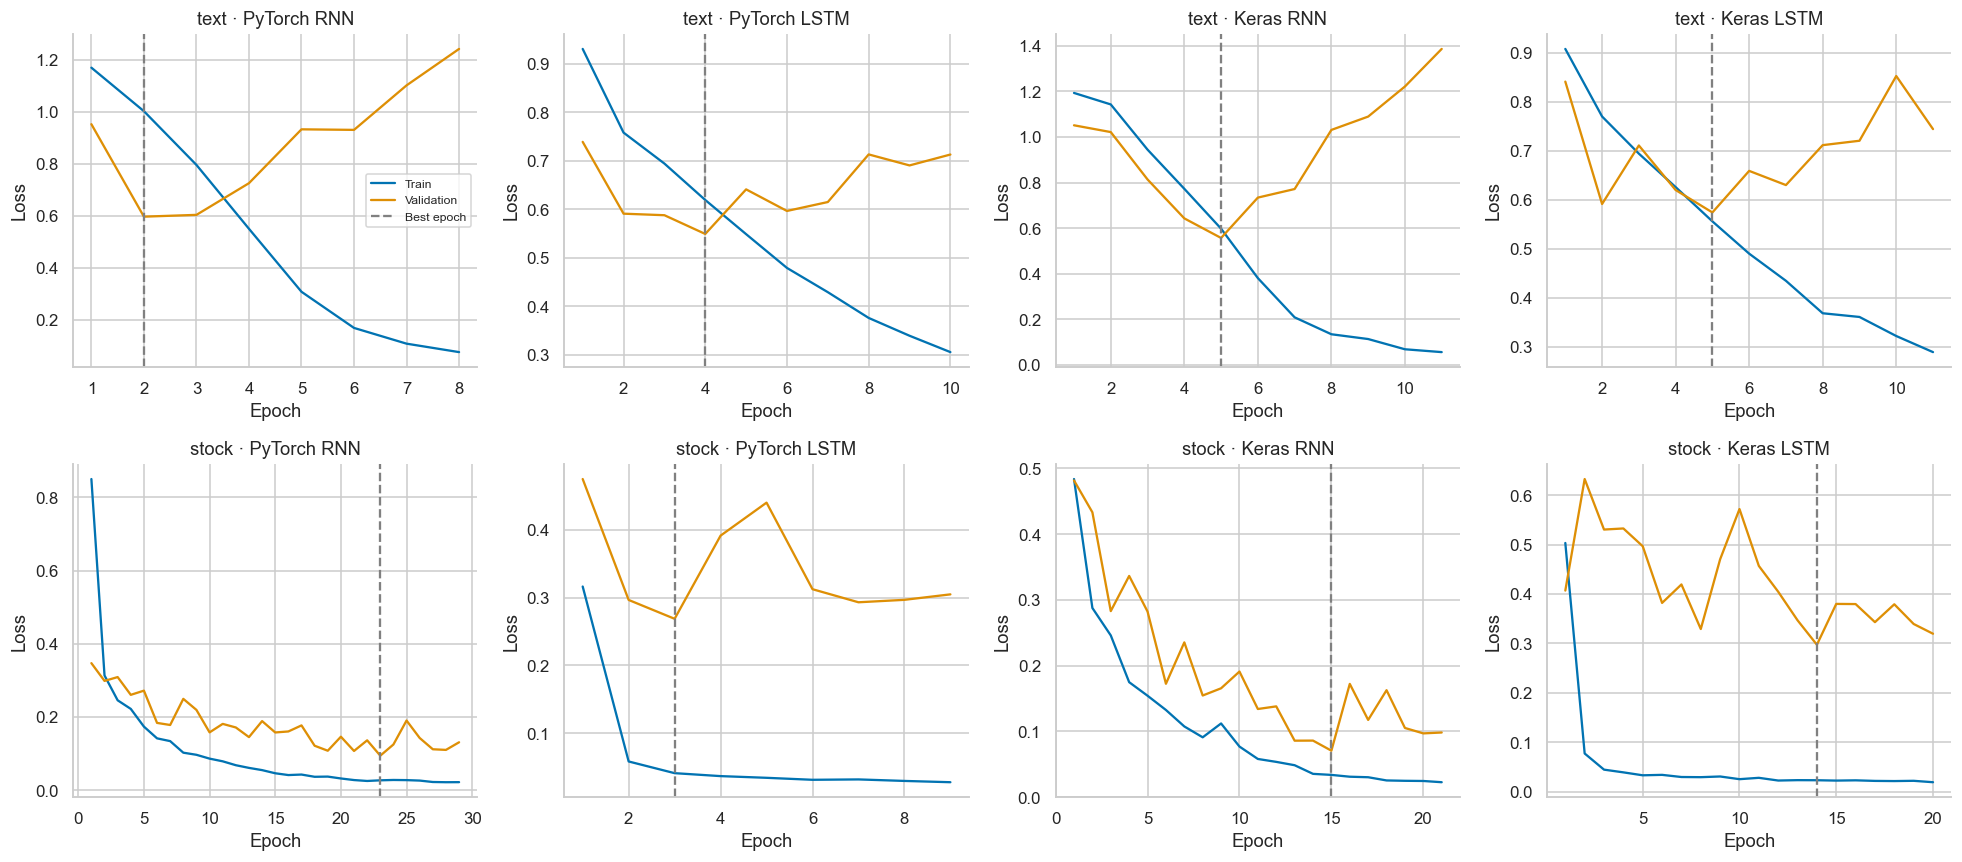

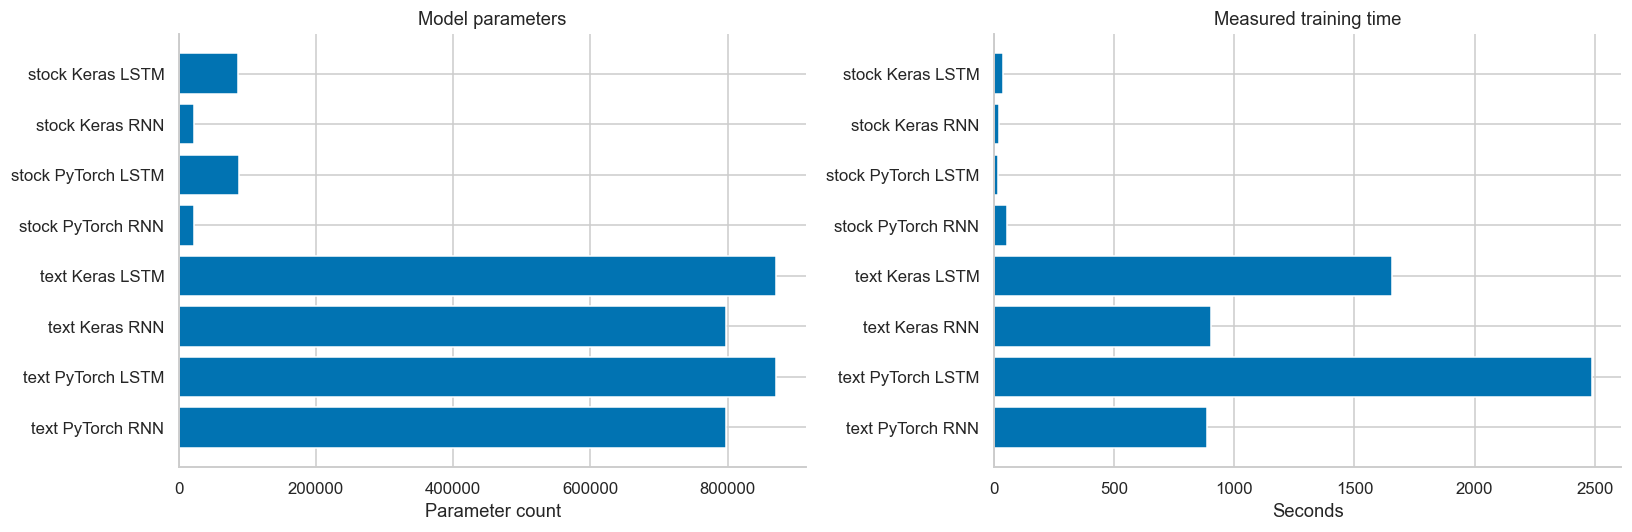

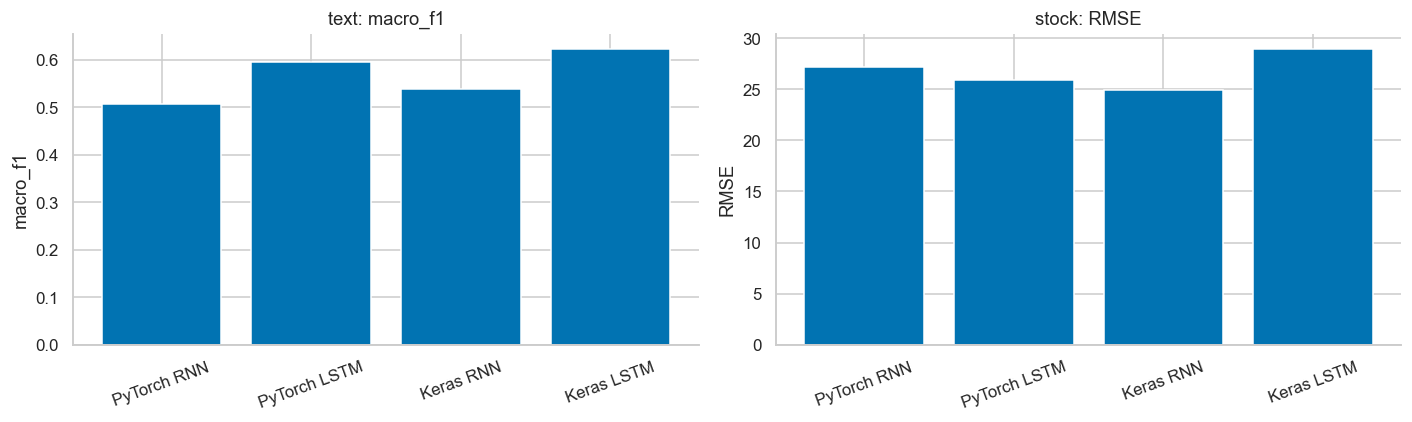

In [104]:
# Purpose: plot the eight learning curves for the first seed and compare run time/parameter count.
seed0=SEEDS[0]
fig,axes=plt.subplots(2,4,figsize=(18,8))
for ax,record in zip(axes.ravel(),[r for r in RESULTS if r['seed']==seed0]):
    history=pd.DataFrame(HISTORIES[record['key']])
    ax.plot(history.epoch,history.train_loss,label='Train')
    ax.plot(history.epoch,history.val_loss,label='Validation')
    ax.axvline(record['best_epoch'],ls='--',color='grey',label='Best epoch')
    ax.set(title=f"{record['task']} · {record['framework']} {record['kind']}",xlabel='Epoch',ylabel='Loss')
axes[0,0].legend(fontsize=8); finish_figure('all_learning_curves')
fig,axes=plt.subplots(1,2,figsize=(15,5))
small=flat_results.loc[flat_results.seed==seed0].copy()
short=small.task+' '+small.framework+' '+small.kind
axes[0].barh(short,small.parameters); axes[0].set(title='Model parameters',xlabel='Parameter count')
axes[1].barh(short,small.training_seconds); axes[1].set(title='Measured training time',xlabel='Seconds')
finish_figure('cost_comparison')
fig,axes=plt.subplots(1,2,figsize=(13,4))
for task,metric,ax in [('text','macro_f1',axes[0]),('stock','RMSE',axes[1])]:
    subset=flat_results[(flat_results.task==task)&(flat_results.seed==seed0)]
    ax.bar(subset.framework+' '+subset.kind,subset[metric])
    ax.tick_params(axis='x',rotation=20); ax.set(title=f'{task}: {metric}',ylabel=metric)
finish_figure('primary_metric_comparison')


### F4. Sentiment analysis: confusion matrix, ROC/PR, confidence, and errors

Rows in the confusion matrix are true labels; columns are predicted labels. Row normalization shows recall, including for rare classes.
The classification report lists precision/recall/F1/support; support is the number of true reviews in that class.
ROC/PR evaluates each class one-versus-rest. The confidence chart bins the maximum predicted probability and compares
**mean confidence** with the **observed accuracy**; a large gap indicates poor calibration.
Do not claim that confidence=0.9 guarantees a particular review is correct with 90% probability.

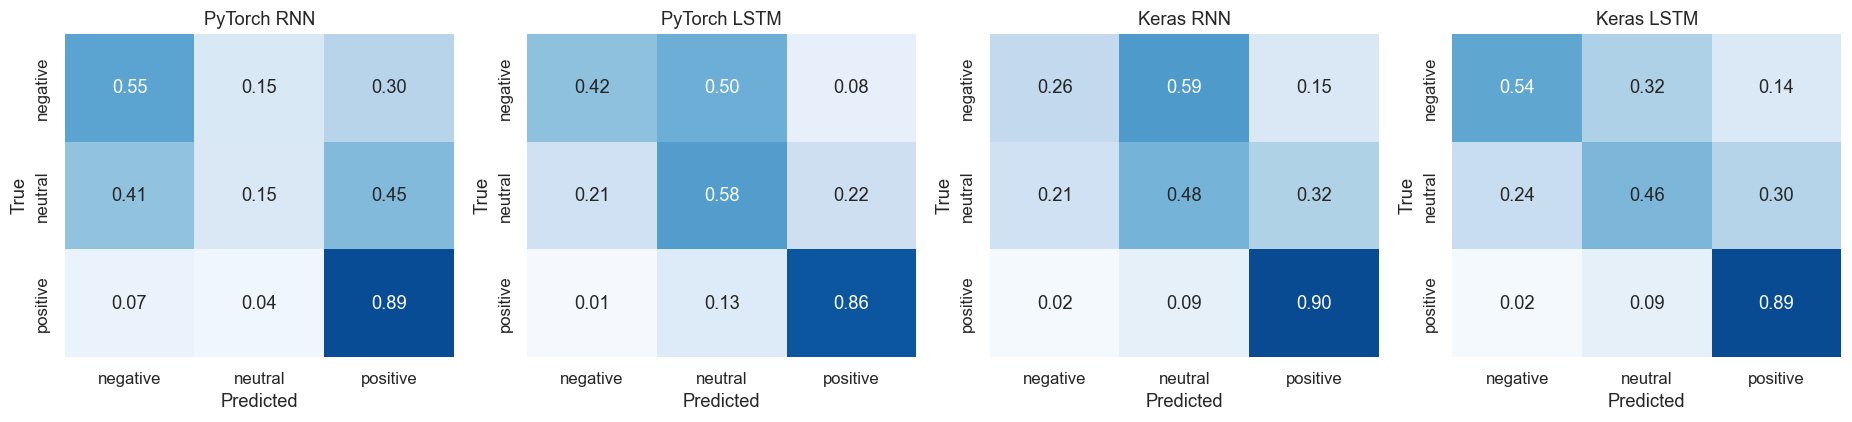

,precision,recall,f1-score,support
negative,0.571856,0.538028,0.554427,355.000000
neutral,0.359779,0.459906,0.403727,424.000000
positive,0.928968,0.894536,0.911427,2617.000000
accuracy,0.803004,0.803004,0.803004,0.803004
macro avg,0.620201,0.630823,0.623193,3396.000000
weighted avg,0.820573,0.803004,0.810720,3396.000000


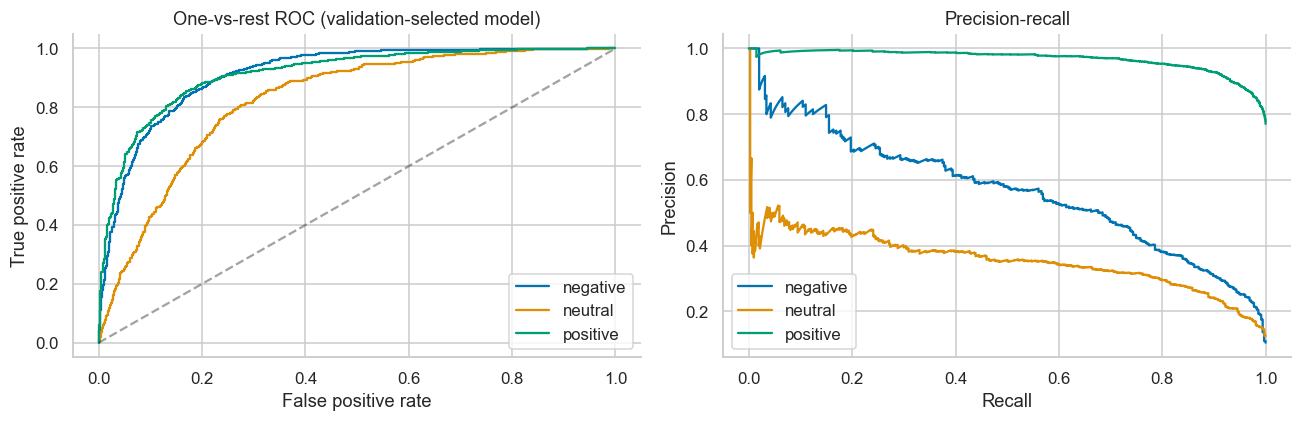

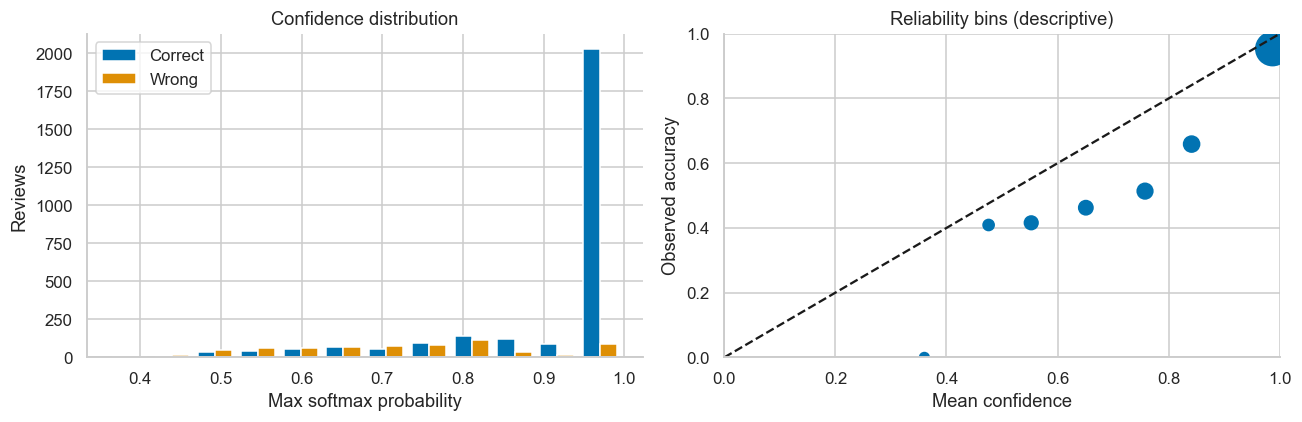

,row_id,text,label,predicted,confidence
2744,21416,it's a lovely pattern on a soft tee the fit is similar to how it looks on the model not clingy at all it s...,1,2,0.996451
1407,10517,i saw this dress in the catalog and had to have it when i went to the store it was sold out so i had them ...,0,2,0.996235
729,5264,the color on these are amazing i am 5 2 and these are really meant for that long lean profile note they ha...,1,2,0.995781
1893,7067,this lift weight cardigan is true to size perfect for fall or spring colors are quite nice especially the ...,1,2,0.995630
1667,12214,this dress in coral is a beautiful color and awesome material only problem is it runs a little big i am a ...,1,2,0.995441
1663,11227,i'm all over this trend but this vest is quite thick poufy and on me i feel like it triangles out and all ...,1,2,0.995434
1286,10334,i love these pants ! best fitting pants i've ever owned flattering stretchy don't stretch out i am so sad ...,1,2,0.995296
535,3694,i agree with the other reviewer this is a nice piece i felt so so about it when i tried it on though see b...,1,2,0.995248
3257,701,i think the model is wearing a larger size per the first review i am 5 2 and 105 lbs and the xs fits about...,1,2,0.995147
823,22989,the reason for the title above is this skirt doesn't wow me i felt like i could find this anywhere and i d...,0,2,0.995063


In [105]:
# Purpose: inspect per-class errors for all four text models, not just overall accuracy.
fig,axes=plt.subplots(1,4,figsize=(17,4))
for ax,r in zip(axes,[r for r in RESULTS if r['task']=='text' and r['seed']==seed0]):
    cm=confusion_matrix(TEXT['test']['y'],PREDICTIONS[r['key']].argmax(1),labels=[0,1,2],normalize='true')
    sns.heatmap(cm,annot=True,fmt='.2f',vmin=0,vmax=1,cmap='Blues',xticklabels=LABELS,yticklabels=LABELS,ax=ax,cbar=False)
    ax.set(title=f"{r['framework']} {r['kind']}",xlabel='Predicted',ylabel='True')
finish_figure('text_confusion_matrices')
text_prob=PREDICTIONS[BEST_TEXT['key']]
text_pred=text_prob.argmax(1)
report=classification_report(TEXT['test']['y'],text_pred,labels=[0,1,2],target_names=LABELS,
                             zero_division=0,output_dict=True)
display(pd.DataFrame(report).T)
save_json(OUT/'text_classification_report.json',report)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for c,label in enumerate(LABELS):
    binary=(TEXT['test']['y']==c).astype(int)
    fpr,tpr,_=roc_curve(binary,text_prob[:,c]); precision,recall,_=precision_recall_curve(binary,text_prob[:,c])
    axes[0].plot(fpr,tpr,label=label); axes[1].plot(recall,precision,label=label)
axes[0].plot([0,1],[0,1],'k--',alpha=.4)
axes[0].set(title='One-vs-rest ROC (validation-selected model)',xlabel='False positive rate',ylabel='True positive rate')
axes[1].set(title='Precision-recall',xlabel='Recall',ylabel='Precision')
for ax in axes: ax.legend()
finish_figure('text_roc_pr')
confidence=text_prob.max(1); correct=(text_pred==TEXT['test']['y']).astype(float)
calibration=[]
for left,right in zip(np.linspace(0,1,11)[:-1],np.linspace(0,1,11)[1:]):
    mask=(confidence>=left)&(confidence<right if right<1 else confidence<=right)
    if mask.any(): calibration.append({'confidence':float(confidence[mask].mean()),
        'accuracy':float(correct[mask].mean()),'count':int(mask.sum())})
calibration=pd.DataFrame(calibration)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].hist([confidence[correct==1],confidence[correct==0]],bins=12,label=['Correct','Wrong'])
axes[0].set(title='Confidence distribution',xlabel='Max softmax probability',ylabel='Reviews'); axes[0].legend()
axes[1].plot([0,1],[0,1],'k--'); axes[1].scatter(calibration.confidence,calibration.accuracy,s=40+calibration['count']/5)
axes[1].set(xlim=(0,1),ylim=(0,1),title='Reliability bins (descriptive)',xlabel='Mean confidence',ylabel='Observed accuracy')
finish_figure('text_confidence')
errors=test_df[['row_id','text','label']].copy()
errors['predicted']=text_pred; errors['confidence']=confidence
errors=errors.loc[errors.label!=errors.predicted].sort_values('confidence',ascending=False)
display(errors.head(12)); errors.to_csv(OUT/'text_errors.csv',index=False)


### F5. Stock: actual/predicted prices, residuals, rolling error, and direction

Residual $e_i=y_i-\hat y_i$: a positive value means the forecast is below the true price. A histogram reveals systematic bias and error tails.
A predicted-versus-actual scatter close to the diagonal is desirable, but not sufficient because persistence may also be close.
A 20-session rolling MAE shows when the model struggles; use it for final test analysis only, not to tune on test.
The directional confusion matrix uses down/flat/up consistently with the metric definition.

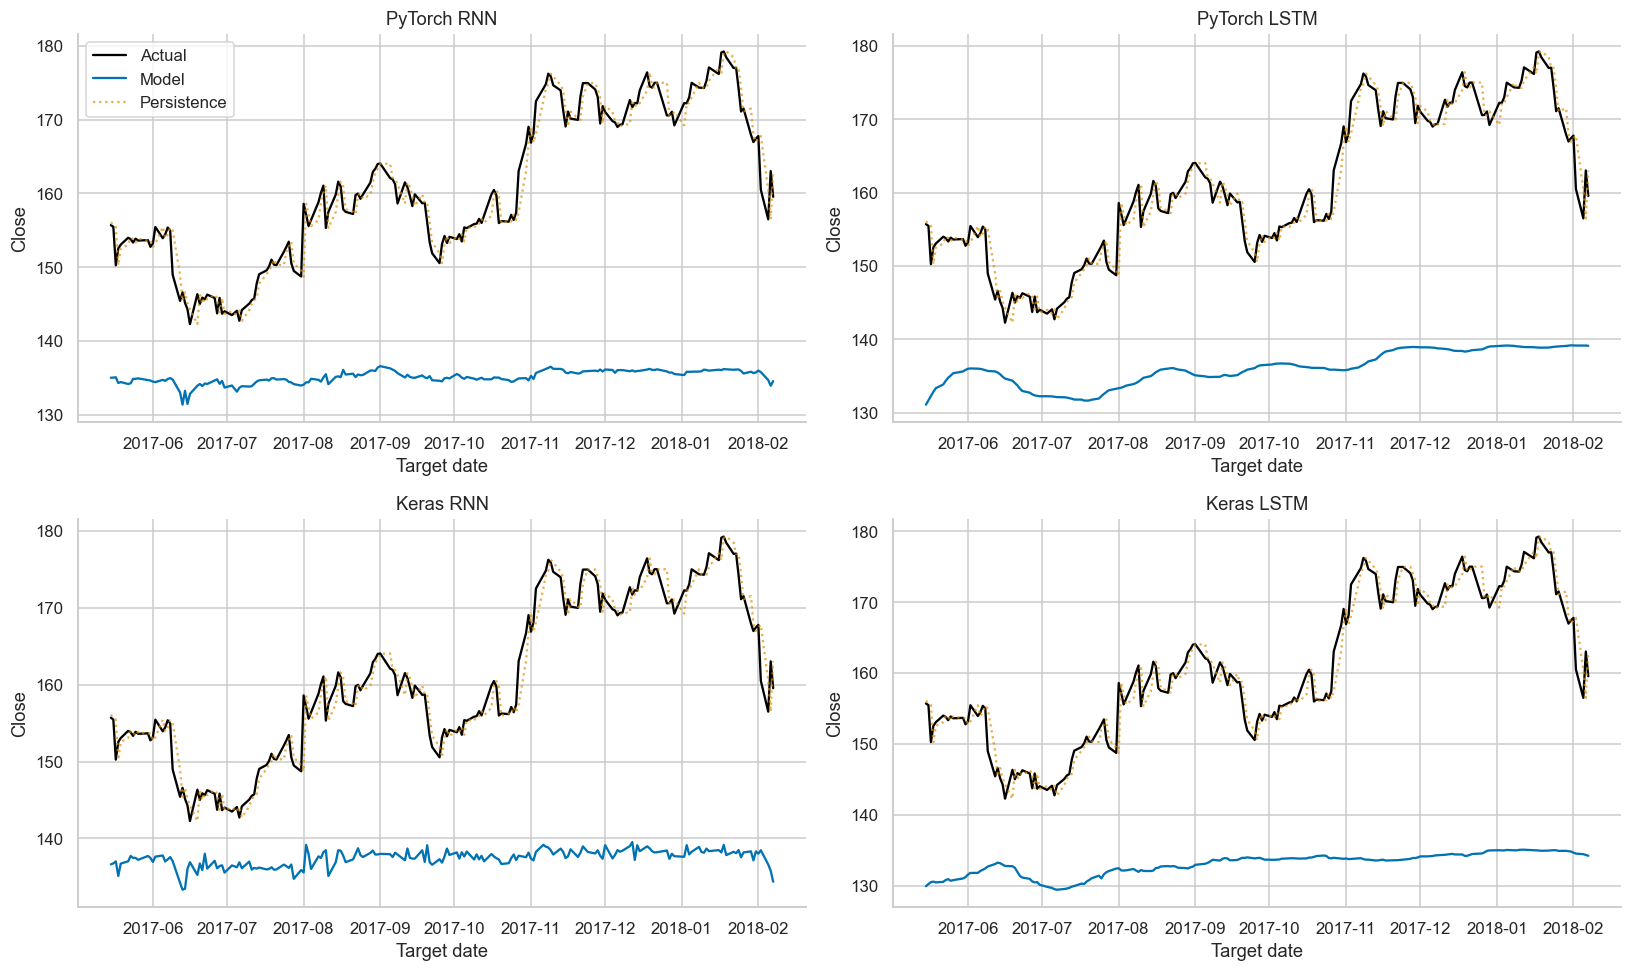

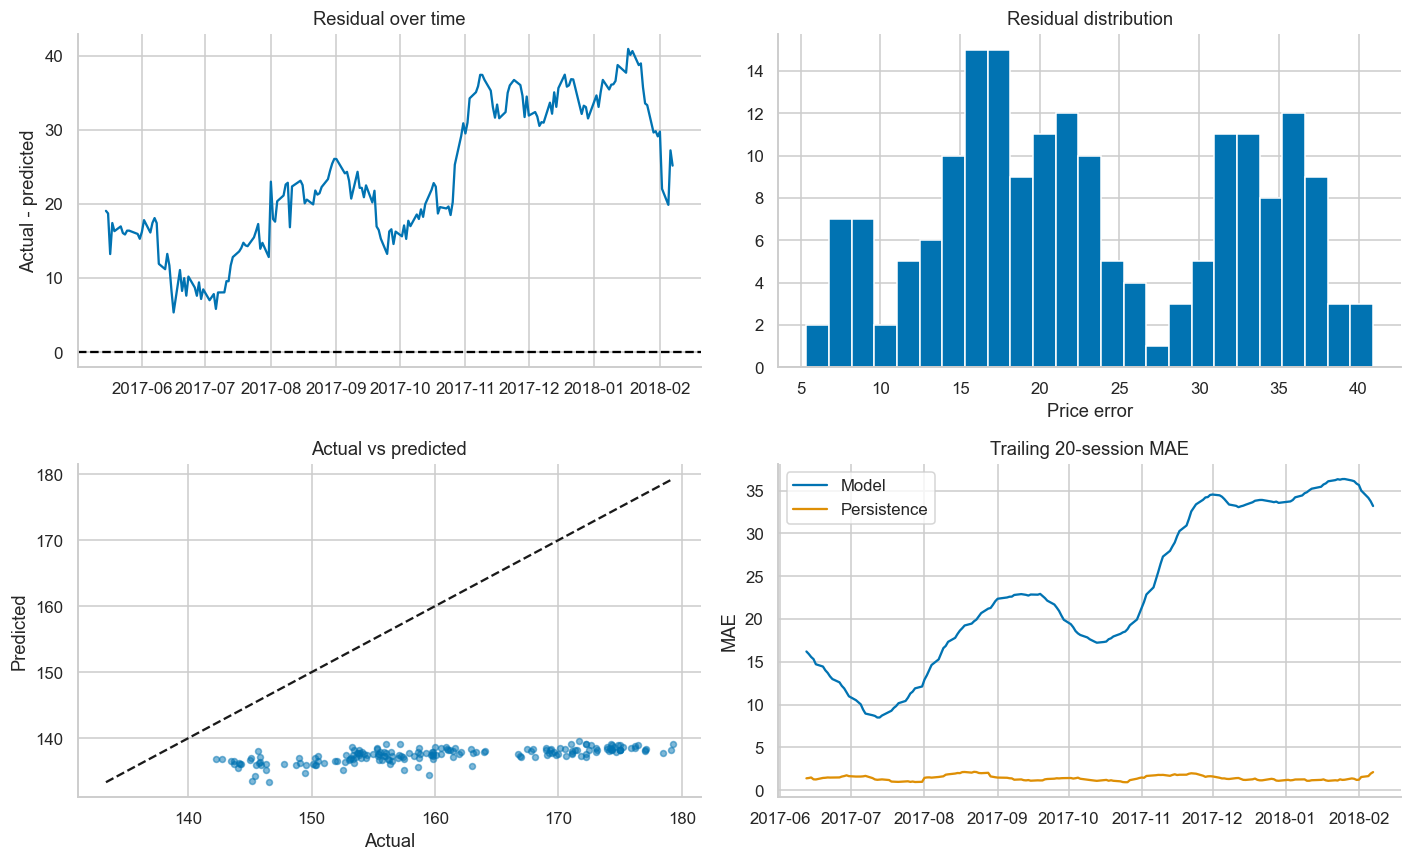

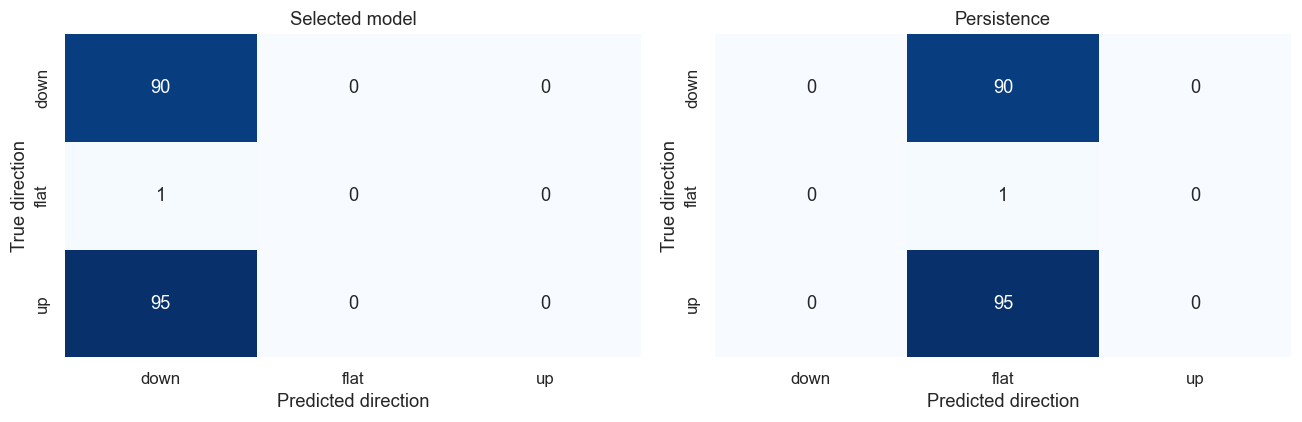

In [106]:
# Purpose: plot price forecasts and baseline together to reveal time-dependent price bias.
y_stock=STOCK['test']['true']; dates=pd.to_datetime(STOCK['test']['dates'])
fig,axes=plt.subplots(2,2,figsize=(15,9))
for ax,r in zip(axes.ravel(),[r for r in RESULTS if r['task']=='stock' and r['seed']==seed0]):
    ax.plot(dates,y_stock,label='Actual',color='black')
    ax.plot(dates,PREDICTIONS[r['key']],label='Model')
    ax.plot(dates,persistence,label='Persistence',ls=':',alpha=.7)
    ax.set(title=f"{r['framework']} {r['kind']}",ylabel='Close',xlabel='Target date')
axes[0,0].legend(); finish_figure('stock_actual_predicted')
stock_pred=PREDICTIONS[BEST_STOCK['key']]; residual=y_stock-stock_pred
fig,axes=plt.subplots(2,2,figsize=(13,8))
axes[0,0].plot(dates,residual); axes[0,0].axhline(0,color='black',ls='--')
axes[0,0].set(title='Residual over time',ylabel='Actual - predicted')
axes[0,1].hist(residual,bins=25); axes[0,1].set(title='Residual distribution',xlabel='Price error')
axes[1,0].scatter(y_stock,stock_pred,alpha=.5,s=15)
lo=min(y_stock.min(),stock_pred.min()); hi=max(y_stock.max(),stock_pred.max())
axes[1,0].plot([lo,hi],[lo,hi],'k--'); axes[1,0].set(title='Actual vs predicted',xlabel='Actual',ylabel='Predicted')
axes[1,1].plot(dates,pd.Series(abs(residual)).rolling(20).mean(),label='Model')
axes[1,1].plot(dates,pd.Series(abs(y_stock-persistence)).rolling(20).mean(),label='Persistence')
axes[1,1].set(title='Trailing 20-session MAE',ylabel='MAE'); axes[1,1].legend()
finish_figure('stock_error_diagnostics')
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,name,pred in [(axes[0],'Selected model',stock_pred),(axes[1],'Persistence',persistence)]:
    cm=confusion_matrix(direction(y_stock,STOCK['test']['previous']),
                        direction(pred,STOCK['test']['previous']),labels=[-1,0,1])
    sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=['down','flat','up'],
                yticklabels=['down','flat','up'],ax=ax,cbar=False)
    ax.set(title=name,xlabel='Predicted direction',ylabel='True direction')
finish_figure('stock_direction_confusion')


### F6. Hidden states and LSTM gates

The norm $\|h_t\|_2=\sqrt{\sum_jh_{tj}^2}$ measures vector magnitude; it does not directly measure “amount of memory.”
The heatmap's horizontal axis is hidden dimension and vertical axis is token/session position.
A forget gate near 1 retains more old state along the direct path; near 0 discards more. One gate trace cannot prove why a model predicted correctly.
Analyze the mechanism separately from empirical predictive quality.

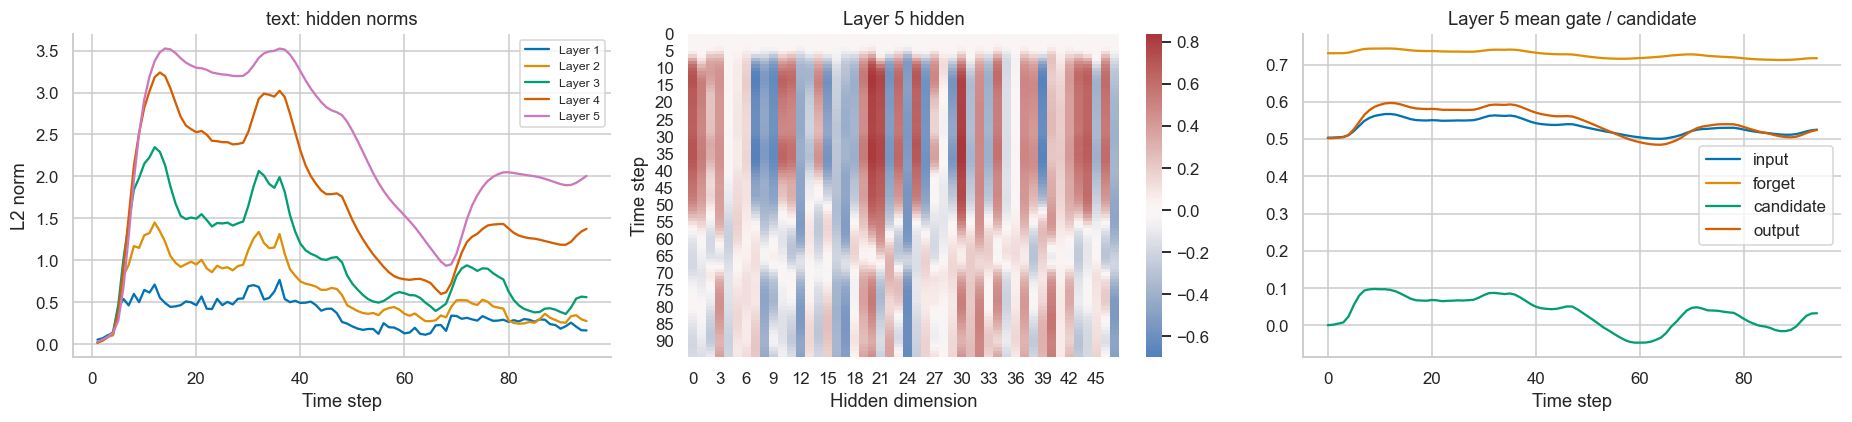

text_keras_lstm_s42 | NumPy vs framework max difference: 1.0543709374033483e-05


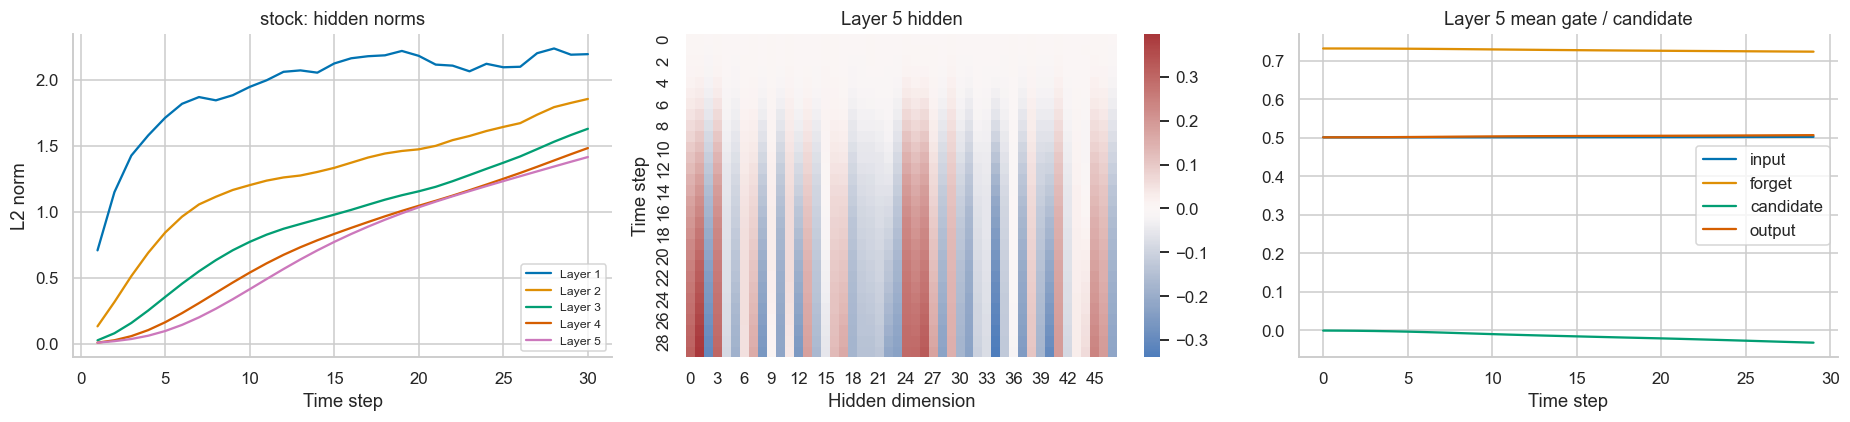

stock_pytorch_lstm_s42 | NumPy vs framework max difference: 1.5134311803777223e-08


In [107]:
# Purpose: inspect hidden-state changes across five layers and LSTM gates from trained weights.
for task in ['text','stock']:
    candidates=[r for r in RESULTS if r['task']==task and r['kind']=='LSTM']
    selected=(max(candidates,key=lambda r:r['validation_metrics']['macro_f1']) if task=='text'
              else min(candidates,key=lambda r:r['validation_metrics']['RMSE']))
    trace=TRACES[selected['key']]
    fig,axes=plt.subplots(1,3,figsize=(17,4))
    norms=np.asarray(trace['hidden_norms'])
    for layer in range(5): axes[0].plot(np.arange(1,norms.shape[1]+1),norms[layer],label=f'Layer {layer+1}')
    axes[0].set(title=f'{task}: hidden norms',xlabel='Time step',ylabel='L2 norm'); axes[0].legend(fontsize=8)
    sns.heatmap(np.asarray(trace['last_layer_hidden']),center=0,cmap='vlag',ax=axes[1])
    axes[1].set(title='Layer 5 hidden',xlabel='Hidden dimension',ylabel='Time step')
    for name,values in trace['gates'].items():
        axes[2].plot(np.asarray(values).mean(axis=1),label=name)
    axes[2].set(title='Layer 5 mean gate / candidate',xlabel='Time step'); axes[2].legend()
    finish_figure(f'{task}_hidden_and_gates')
    print(selected['key'],'| NumPy vs framework max difference:',trace['max_output_difference'])


### F7. Estimating uncertainty in the LSTM–RNN difference

Compare paired predictions on the **same test examples** from the same framework and first seed. For reviews, use a label-stratified bootstrap
to preserve class support. For stock, use a moving-block bootstrap (20-session blocks) to preserve some local dependence.
Five hundred resamples produce a 2.5%–97.5% percentile interval for the difference.

Reviews: $\Delta=F1_{LSTM}-F1_{RNN}$; positive favors LSTM. Stock: $\Delta=RMSE_{LSTM}-RMSE_{RNN}$; negative favors LSTM.
This interval describes sampling uncertainty in the test set under the resampling assumptions. It does **not** include uncertainty across all seeds,
market periods, or hyperparameter choices, and it is not automatically causal evidence.

In [108]:
# Purpose: quantify paired differences instead of only comparing two nearby numbers.
def paired_bootstrap(task, framework, repeats=500):
    """Paired bootstrap preserves prediction/label pairs; stratify reviews and use adjacent blocks for stock."""
    a=PREDICTIONS[f'{task}_{framework.lower()}_rnn_s{seed0}']
    b=PREDICTIONS[f'{task}_{framework.lower()}_lstm_s{seed0}']
    y=TEXT['test']['y'] if task=='text' else STOCK['test']['true']
    rng=np.random.default_rng(2026); differences=[]; n=len(y)
    for _ in range(repeats):
        if task=='text':
            index=np.concatenate([rng.choice(np.flatnonzero(y==c),size=int((y==c).sum()),replace=True) for c in range(3)])
            diff=f1_score(y[index],b[index].argmax(1),average='macro',zero_division=0)-f1_score(y[index],a[index].argmax(1),average='macro',zero_division=0)
        else:
            block=min(20,n)
            starts=rng.integers(0,n-block+1,size=math.ceil(n/block))
            index=np.concatenate([np.arange(start,start+block) for start in starts])[:n]
            diff=np.sqrt(mean_squared_error(y[index],b[index]))-np.sqrt(mean_squared_error(y[index],a[index]))
        differences.append(diff)
    low,high=np.quantile(differences,[.025,.975])
    return {'task':task,'framework':framework,'difference':'LSTM - RNN',
            'bootstrap_mean':float(np.mean(differences)),'lower_95':float(low),'upper_95':float(high)}

bootstrap_table=pd.DataFrame([paired_bootstrap(task,framework) for task in ['text','stock'] for framework in ['PyTorch','Keras']])
display(bootstrap_table); bootstrap_table.to_csv(OUT/'paired_bootstrap.csv',index=False)


,task,framework,difference,bootstrap_mean,lower_95,upper_95
0,text,PyTorch,LSTM - RNN,0.088636,0.062716,0.113187
1,text,Keras,LSTM - RNN,0.085668,0.059452,0.112262
2,stock,PyTorch,LSTM - RNN,-1.101765,-1.971556,-0.177274
3,stock,Keras,LSTM - RNN,4.066327,3.658625,4.454847


### F8. Interactive visualizations and conclusions generated from data

Plotly charts support zoom and hover and can be exported as HTML for offline viewing. The saved HTML bundles JavaScript and does not need an Internet connection.
The notebook may need Internet for the `notebook_connected` renderer; if a chart does not appear, open its HTML file under `outputs/<run_id>/`.
Do not plot a future trend or combine metrics with different units on one axis.
The conclusion below is displayed only after actual results are available.

In [109]:
# Purpose: export an interactive dashboard for this report and data for a future web app.
interactive=go.Figure()
interactive.add_trace(go.Scatter(x=dates,y=y_stock,name='Actual',line={'color':'black'}))
interactive.add_trace(go.Scatter(x=dates,y=persistence,name='Persistence',line={'dash':'dot'}))
for r in RESULTS:
    if r['task']=='stock' and r['seed']==seed0:
        interactive.add_trace(go.Scatter(x=dates,y=PREDICTIONS[r['key']],name=f"{r['framework']} {r['kind']}"))
interactive.update_layout(title='AAPL: historical one-step test forecasts',xaxis_title='Target session',
                          yaxis_title='Close (dataset price units)',template='plotly_white',hovermode='x unified',
                          xaxis={'rangeslider':{'visible':True}})
interactive.write_html(OUT/'stock_interactive.html',include_plotlyjs=True)
interactive.show()
market=go.Figure(go.Candlestick(x=stock_raw.date,open=stock_raw.open,high=stock_raw.high,
                              low=stock_raw.low,close=stock_raw.close,name='AAPL'))
market.update_layout(title='Historical AAPL OHLC — source data',template='plotly_white')
market.write_html(OUT/'stock_candlestick.html',include_plotlyjs=True)

text_summary=BEST_TEXT['metrics']; stock_summary=BEST_STOCK['metrics']
comparison='better than' if stock_summary['MAE']<base_mae else 'not better than'
mode_note='**SMOKE RUN: technical check only; do not use it to draw performance conclusions.**' if PRESET=='smoke' else ''
display(Markdown(f"""{mode_note}

### Findings from run `{RUN_ID}`
{mode_note}

- The sentiment model selected on validation: **{BEST_TEXT['key']}**; test macro-F1 **{text_summary['macro_f1']:.4f}**,
  accuracy **{text_summary['accuracy']:.4f}**. Review neutral/negative recall before making a quality claim.
- The TF-IDF baseline has test macro-F1 **{BASELINES[1]['macro_f1']:.4f}**; the neural network is not assumed to outperform the baseline.
- The stock model selected on validation is: **{BEST_STOCK['key']}**; test MAE **{stock_summary['MAE']:.4f}**,
  RMSE **{stock_summary['RMSE']:.4f}**, directional accuracy **{stock_summary['directional_accuracy']:.2%}**.
- By MAE, this model is **{comparison} persistence** (MAE baseline **{base_mae:.4f}**).
- There are **{len(SEEDS)} seeds**. The bootstrap table describes sampling uncertainty only; stronger conclusions require more seeds and data domains.
"""))




### Findings from run `full_1fea63a4c1b4`


- The sentiment model selected on validation: **text_keras_lstm_s42**; test macro-F1 **0.6232**,
  accuracy **0.8030**. Review neutral/negative recall before making a quality claim.
- The TF-IDF baseline has test macro-F1 **0.6273**; the neural network is not assumed to outperform the baseline.
- The stock model selected on validation is: **stock_keras_rnn_s42**; test MAE **23.1264**,
  RMSE **24.9485**, directional accuracy **48.39%**.
- By MAE, this model is **not better than persistence** (MAE baseline **1.4640**).
- There are **1 seeds**. The bootstrap table describes sampling uncertainty only; stronger conclusions require more seeds and data domains.


# G. Inference deployment, exported artifacts, and final report

### G1. Data contract for a future local web app

The web app will load trained artifacts; opening `python app.py` will not start training.
`dashboard.json` is schema version 1 and contains configuration, sources, labels, metrics, history, predictions, traces, sample reviews, and model information.
`model_registry.json` maps model keys to checkpoints and configurations. Larger data stays in CSV/NPY files instead of being sent to the browser on every request.

| Artifact | Purpose |
|---|---|
| `<model>.keras` | Complete Keras model architecture and weights |
| `<model>.pt` | PyTorch state_dict + configuration; requires the `StackedRecurrent` class |
| `tokenizer.json` | Vocabulary and max_len for the same text preprocessing |
| `stock_preprocess.joblib` | Feature order, lookback, and x/y scalers |
| `a7_inference.py` | Shared tokenizer, features, PyTorch model, and inference functions |
| `dashboard.json` | Chart and table data for the interface |
| `all_results.csv`, `predictions/`, `histories/` | Detailed data that can be audited |

Only load checkpoints/joblib files created by this project or from a trusted source. Do not put API keys in artifacts.
The sentiment model in this notebook is trained on **English**; entering Vietnamese does not demonstrate that it can classify Vietnamese correctly.
The stock demo predicts the next session after the last OHLCV row. Do not label it by adding one calendar day because weekends and holidays intervene.

In [110]:
# A7_EXPORT: inference
# Purpose: provide inference APIs independent of notebook variables for a future local Flask app.
def load_bundle(model_dir, key):
    """Load a model and preprocessing artifacts from one run directory; call once when the web app starts."""
    model_dir=Path(model_dir)
    registry=json.loads((model_dir/'model_registry.json').read_text(encoding='utf-8'))
    entry=registry[key]
    if entry['framework']=='PyTorch':
        checkpoint=torch.load(model_dir/entry['filename'],map_location='cpu',weights_only=True)
        model=StackedRecurrent(checkpoint['config'])
        model.load_state_dict(checkpoint['state_dict']); model.eval()
    else:
        import tensorflow as tf
        model=tf.keras.models.load_model(model_dir/entry['filename'],compile=False)
    bundle={'model':model,'entry':entry}
    if entry['task']=='text':
        bundle['preprocess']=json.loads((model_dir/'tokenizer.json').read_text(encoding='utf-8'))
    else: bundle['preprocess']=joblib.load(model_dir/'stock_preprocess.joblib')
    return bundle


def predict_review(bundle, text):
    """Predict sentiment for one English review; return class probabilities, label, token, OOV, and truncation details."""
    if bundle['entry']['task']!='text': raise ValueError('Selected model is not a sentiment model.')
    tokens=tokenize(text)
    if not tokens: raise ValueError('Review is empty after normalization.')
    pre=bundle['preprocess']
    x,lengths=encode_texts([text],pre['vocab'],pre['max_len'])
    if bundle['entry']['framework']=='PyTorch':
        with torch.no_grad(): logits=bundle['model'](torch.as_tensor(x),torch.as_tensor(lengths)).numpy()[0]
    else: logits=bundle['model'](x,training=False).numpy()[0]
    p=np.exp(logits-logits.max()); p=p/p.sum()
    return {'label':pre['labels'][int(p.argmax())],
            'probabilities':dict(zip(pre['labels'],map(float,p))),
            'confidence':float(p.max()),'tokens_total':len(tokens),'tokens_used':int(lengths[0]),
            'truncated':len(tokens)>pre['max_len'],
            'oov_rate':sum(t not in pre['vocab'] for t in tokens)/len(tokens)}


def predict_next_close(bundle, raw_frame):
    """Forecast one next session from completed OHLCV data; do not fabricate future inputs."""
    if bundle['entry']['task']!='stock': raise ValueError('Selected model is not a stock model.')
    frame=raw_frame.copy()
    frame.columns=frame.columns.str.lower()
    columns=['open','high','low','close','volume']
    if not set(['date']+columns).issubset(frame.columns): raise ValueError('Missing date/OHLCV columns.')
    frame['date']=pd.to_datetime(frame['date'],errors='raise')
    for col in columns: frame[col]=pd.to_numeric(frame[col],errors='raise')
    if not np.isfinite(frame[columns].to_numpy()).all(): raise ValueError('OHLCV contains NaN/Inf values.')
    if (frame[['open','high','low','close']]<=0).any().any() or (frame.volume<0).any():
        raise ValueError('Prices must be positive and volume must be nonnegative.')
    features,names=engineer_stock(frame)
    pre=bundle['preprocess']; L=pre['lookback']
    if names!=pre['features']: raise ValueError('Feature schema does not match training.')
    if len(features)<L: raise ValueError(f'At least {L+20} raw sessions are required for rolling warm-up and lookback.')
    x=pre['x'].transform(features[names].tail(L)).astype('float32')[None]
    if bundle['entry']['framework']=='PyTorch':
        with torch.no_grad(): scaled=bundle['model'](torch.as_tensor(x)).numpy()
    else: scaled=bundle['model'](x,training=False).numpy()
    predicted=float(pre['y'].inverse_transform(scaled)[0,0])
    previous=float(features.close.iloc[-1])
    return {'last_observed_session':features.date.iloc[-1].strftime('%Y-%m-%d'),
            'target':'next trading session','previous_close':previous,'predicted_close':predicted,
            'predicted_change_percent':100*(predicted/previous-1),'input_shape':list(x.shape)}


In [111]:
# Purpose: export the defined modules so the web app does not reimplement preprocessing.
registry={r['key']:{'framework':r['framework'],'task':r['task'],'kind':r['kind'],
                   'config':r['config'],'filename':Path(r['checkpoint']).name} for r in RESULTS}
save_json(MODEL_DIR/'model_registry.json',registry)
NOTEBOOK_FILENAME='A7_RNN_LSTM_5Layers.ipynb'
notebook_candidates=[ROOT/'notebooks'/NOTEBOOK_FILENAME,ROOT/NOTEBOOK_FILENAME,Path.cwd()/NOTEBOOK_FILENAME]
notebook_file=next((p for p in notebook_candidates if p.exists()),None)
if notebook_file is None:
    raise FileNotFoundError(f'Place the notebook named {NOTEBOOK_FILENAME} in {ROOT / "notebooks"}, save it, and rerun this cell.')
notebook_document=json.loads(notebook_file.read_text(encoding='utf-8'))
export_tags={'preprocessing','stock_features','torch_model','inference'}
export_cells=[''.join(c['source']) if isinstance(c['source'],list) else c['source']
              for c in notebook_document['cells'] if c['cell_type']=='code'
              and export_tags.intersection(c.get('metadata',{}).get('tags',[]))]
assert len(export_cells)==4, 'Notebook metadata tags are required to export the correct inference functions.'
module_header="""# A7 inference module generated from notebook; preprocessing schema v1.
from pathlib import Path
import json, re, html, unicodedata
import numpy as np
import pandas as pd
import joblib
import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence
"""
(MODEL_DIR/'a7_inference.py').write_text(module_header+'\n\n'.join(export_cells),encoding='utf-8')
metric_definitions={'macro_f1':'Mean F1 across negative, neutral, positive; higher is better.',
    'MAE':'Mean absolute close-price error in source units; lower is better.',
    'RMSE':'Root mean square close-price error; lower is better.',
    'directional_accuracy':'Three-way down/flat/up relative to previous observed close.',
    'confidence':'Maximum softmax score; not a guarantee and not calibrated by default.'}
payload={'schema_version':1,'run_id':RUN_ID,'status':'smoke_only' if PRESET=='smoke' else 'complete',
    'created_at_utc':datetime.now(timezone.utc).isoformat(),'protocol':protocol,
    'sources':{'reviews':'https://www.kaggle.com/datasets/nicapotato/womens-ecommerce-clothing-reviews',
               'stock':'https://www.kaggle.com/datasets/camnugent/sandp500'},
    'labels':LABELS,'feature_names':FEATURES,'metric_definitions':metric_definitions,
    'selected_on_validation':{'text':BEST_TEXT['key'],'stock':BEST_STOCK['key']},
    'experiments':RESULTS,'baselines':BASELINES,'histories':HISTORIES,'traces':TRACES,
    'stock_test':{'dates':STOCK['test']['dates'].tolist(),'actual':y_stock.tolist(),'previous':persistence.tolist(),
        'predictions':{r['key']:PREDICTIONS[r['key']].tolist() for r in RESULTS if r['task']=='stock'}},
    'text_examples':test_df[['row_id','text','label']].head(100).to_dict('records'),
    'text_example_probabilities':{r['key']:PREDICTIONS[r['key']][:100].tolist() for r in RESULTS if r['task']=='text'}}
save_json(OUT/'dashboard.json',payload)
save_json(ROOT/'outputs/latest_run.json',{'run_id':RUN_ID,'status':payload['status'],
    'dashboard':(OUT/'dashboard.json').relative_to(ROOT).as_posix(),
    'models':MODEL_DIR.relative_to(ROOT).as_posix()})
print('Exported:',OUT/'dashboard.json')
print('Inference module:',MODEL_DIR/'a7_inference.py')
print('Number of models:',len(registry),'| Web folder prepared:',ROOT/'web')


Exported: C:\Users\ADMIN\Downloads\Intelligent System\assignment 7\DATA\outputs\full_1fea63a4c1b4\dashboard.json
Inference module: C:\Users\ADMIN\Downloads\Intelligent System\assignment 7\DATA\models\full_1fea63a4c1b4\a7_inference.py
Number of models: 8 | Web folder prepared: C:\Users\ADMIN\Downloads\Intelligent System\assignment 7\DATA\web


### G2. Reload checks and inference demo in the notebook

Validate serialization by loading each saved model and comparing a few predictions with the values recorded before saving.
This check helps ensure the web app does not load a model or tokenizer that differs from the notebook.
Then try a new review and the latest OHLCV window. A next-session forecast after the final data row **has no ground truth yet**;
do not merge it into the test score or call it “today's tomorrow price.”

In [112]:
# Purpose: verify that all eight models reload before handing artifacts to the web app.
for r in RESULTS:
    bundle=load_bundle(MODEL_DIR,r['key'])
    if r['task']=='text':
        result=predict_review(bundle,test_df.text.iloc[0])
        restored=np.array([result['probabilities'][label] for label in LABELS])
        np.testing.assert_allclose(restored,PREDICTIONS[r['key']][0],rtol=2e-4,atol=2e-4)
    else:
        sample=STOCK['test']['X'][:1]
        if r['framework']=='PyTorch':
            with torch.no_grad(): scaled=bundle['model'](torch.as_tensor(sample)).numpy()
        else: scaled=bundle['model'](sample,training=False).numpy()
        restored=y_scaler.inverse_transform(scaled).ravel()[0]
        np.testing.assert_allclose(restored,PREDICTIONS[r['key']][0],rtol=2e-4,atol=2e-4)
    del bundle; tf.keras.backend.clear_session(); gc.collect()
print('PASS: all models reload and produce matching predictions.')
text_bundle=load_bundle(MODEL_DIR,BEST_TEXT['key'])
display(predict_review(text_bundle,'The fabric is comfortable, but the size is much smaller than expected.'))
del text_bundle; tf.keras.backend.clear_session(); gc.collect()
stock_bundle=load_bundle(MODEL_DIR,BEST_STOCK['key'])
display(predict_next_close(stock_bundle,stock_raw))
del stock_bundle; tf.keras.backend.clear_session(); gc.collect()


PASS: all models reload and produce matching predictions.


{'label': 'neutral',
 'probabilities': {'negative': 0.1459067016839981,
  'neutral': 0.4522806704044342,
  'positive': 0.4018125832080841},
 'confidence': 0.4522806704044342,
 'tokens_total': 12,
 'tokens_used': 12,
 'truncated': False,
 'oov_rate': 0.0}

{'last_observed_session': '2018-02-07',
 'target': 'next trading session',
 'previous_close': 159.54,
 'predicted_close': 135.2847137451172,
 'predicted_change_percent': -15.203263291264136,
 'input_shape': [1, 30, 11]}

0

### G3. Review questions and how to explain the project in a defense

**1. Why are RNNs suitable for ordered data?** The hidden state depends on the current input and the previous hidden state.
Changing token/session order can change the result. The network learns sequential relationships, not just statistics over an unordered set of values.

**2. How do five layers differ from 30 time steps?** Layers are vertical depth: a lower layer's output becomes the next layer's input.
Time steps are horizontal: the same cell in a layer repeats using shared weights. The unrolled stock network has five layers × 30 steps.

**3. What are the actual inputs and targets?** Reviews: input is review token IDs; target is the label derived from rating.
Stock: input is an $L\times F$ tensor of prior sessions; target is the next session's close. Features do not include the future target.

**4. Is an embedding one-hot encoding?** No. A one-hot vector has length $V$ and one value equal to 1; an embedding has length $E$ and is a learned dense vector.
Looking up an embedding is equivalent to multiplying a one-hot vector by the embedding matrix without constructing a huge one-hot vector.

**5. Why not include rating in the input?** Rating creates the target; the model could infer the answer without reading the review.
That is target leakage and makes sentiment evaluation meaningless.

**6. Why does an LSTM have both $h$ and $c$?** $c$ is an additive memory path with gates that retain/write information; $h$ is exposed through the output gate.
A basic RNN usually has only $h$. LSTM can help gradient flow but is not guaranteed to win on every dataset.

**7. Is sigmoid a class probability?** A gate sigmoid in $(0,1)$ regulates information flow; it is not a sentiment probability.
The class distribution at the output head uses softmax. Candidate $g$ uses tanh and can be negative.

**8. Why mask PAD?** PAD fills unused positions and is not content. Updating state through PAD can make sequence length distort the representation.
Keras uses a mask and PyTorch uses packing. The notebook also checks that adding PAD does not change a prediction.

**9. Why not shuffle stock before splitting?** That would mix future data into training and past data into test, failing to simulate forecasting.
Training windows may be shuffled after splitting without changing the time order inside each input window.

**10. Why use High/Low/Open when forecasting Close?** They describe prior-session movement and range and may provide additional signals.
There is no guarantee each feature helps; demonstrate that with a validation-set ablation, never by optimizing on test.

**11. Why fit the scaler/vocabulary on training data only?** Fitting on all data lets future statistics and tokens affect the learning procedure.
Validation/test must be transformed using rules learned from training.

**12. Why can accuracy be high while sentiment performance is poor?** The model may always predict positive when that class dominates.
Macro-F1 and per-class recall reveal missed negative/neutral reviews.

**13. Is a high $R^2$ enough to prove a good stock forecast?** No. Adjacent prices are similar, making persistence a strong baseline.
Compare MAE/RMSE, residuals, directional accuracy, and stability over time.

**14. Why not apply softmax before PyTorch CrossEntropy?** CrossEntropyLoss takes logits and combines log-softmax stably.
Applying softmax twice changes the objective. Keras uses the equivalent `from_logits=True` setting.

**15. Why do frameworks have slightly different parameter counts?** PyTorch uses two biases per branch; Keras uses one.
Even with the same hidden size, parameter count and optimization differ; the notebook checks the count against the formula.

**16. Can these probabilities be called confidence?** They may be shown as confidence scores, but clearly state they are not calibrated.
A reliability plot compares scores with observed accuracy. Do not create a stock confidence interval using softmax; this is point regression.

**17. Why not conclude in advance that “LSTM is best”?** Results depend on data, sequence length, budget, regularization, seed, and baselines.
The notebook generates its conclusion from measured metrics and states the limitations.

**18. Does this answer the KG/RAG/Agent exercises in the two earlier PDFs?** No. The agreed scope focuses only on RNN/LSTM.
The retained connection is that a useful application needs a predictive model, data, evaluation, and an interface.

### G4. Limitations, follow-up research, and environment troubleshooting

- The default laptop preset uses at most 10,000 training reviews; validation/test remain unchanged. Increase the data with the `full` preset.
  Do not compare models trained with different presets as though they had the same budget.
- Stock data covers only a few years and one ticker; a five-layer network may be too complex. Five layers are an assignment requirement, not evidence that this depth is optimal.
- Star-derived sentiment labels are noisy; text is English and only the review body is used. No product/customer holdout has been evaluated.
- Test is reserved for final reporting. If test errors are used to tune the model, obtain a new test set or use a nested/walk-forward protocol.
- One seed cannot establish stability. `SEEDS` supports repeated runs; rolling-origin stock evaluation is a possible follow-up.
- LSTM gate/hidden plots are diagnostics, not attention, causal explanations, or guarantees of faithful explanations.
- No experimental results are prefilled in the delivered notebook.

| Common issue | Action |
|---|---|
| `ModuleNotFoundError` | Check `sys.executable` and select the correct A7 kernel |
| TensorFlow DLL error on Windows | Follow TensorFlow/Microsoft runtime instructions; use 64-bit Python 3.11 |
| Kaggle download fails | Download the ZIP from the original source and place the CSV in `data/ecommerce` or `data/stock` |
| Run takes a long time | Try smoke, use laptop mode, inspect seconds/epoch; reduce batch if RAM is low, but do not reduce below five layers |
| Notebook closes mid-run | Run again with reuse enabled; completed models are reloaded |
| Old results appear after a configuration change | `run_id` should change; inspect `run_config.json`; set reuse False if training code changed |
| Plotly does not render | Open the exported HTML; PNG and tables are also saved |
| Export cannot find notebook | Keep the expected filename under `notebooks/`, save the notebook, and rerun the export cell |

### G5. A7 assignment checklist

| Requirement | Implemented in |
|---|---|
| Two Kaggle datasets: reviews and stock | A2, C1, D1; source links, hash, and audit |
| Five-layer RNN as function composition / elementary functions | B2–B3, depth×time diagram, NumPy cell |
| Five-layer LSTM as function composition / elementary functions | B4–B5, gate equations, NumPy cell |
| PyTorch for both datasets and both architectures | E1, E4, four experiment cells |
| Keras for both datasets and both architectures | E1, E5, four experiment cells |
| Compare RNN with LSTM | F1–F8; baselines, metrics, cost, bootstrap |
| Overview, sources, structure, representations, features | A–D |
| Varied visualizations matched to their purpose | EDA, learning curves, confusion matrix, ROC/PR, calibration, residuals, gates, Plotly |
| Explain before code; comments and docstrings | Interleaved Markdown and code throughout |
| Future reuse by a local `python app.py` web demo | G1–G2: model registry, inference module, dashboard JSON |

### G6. Official references

1. [Kaggle — Women's E-Commerce Clothing Reviews](https://www.kaggle.com/datasets/nicapotato/womens-ecommerce-clothing-reviews).
2. [Kaggle — S&P 500 stock data](https://www.kaggle.com/datasets/camnugent/sandp500).
3. [PyTorch RNN: equations, shapes, stacking, and bias](https://docs.pytorch.org/docs/stable/generated/torch.nn.RNN.html).
4. [PyTorch LSTM: gates, h/c, and num_layers](https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html).
5. [PyTorch pack_padded_sequence](https://docs.pytorch.org/docs/stable/generated/torch.nn.utils.rnn.pack_padded_sequence.html).
6. [Keras SimpleRNN](https://keras.io/api/layers/recurrent_layers/simple_rnn/).
7. [Keras LSTM](https://keras.io/api/layers/recurrent_layers/lstm/).
8. [Keras RNN masking](https://keras.io/api/layers/recurrent_layers/rnn/).
9. [TensorFlow installation](https://www.tensorflow.org/install/pip).
10. [Official KaggleHub repository](https://github.com/Kaggle/kagglehub).
11. [scikit-learn model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html).

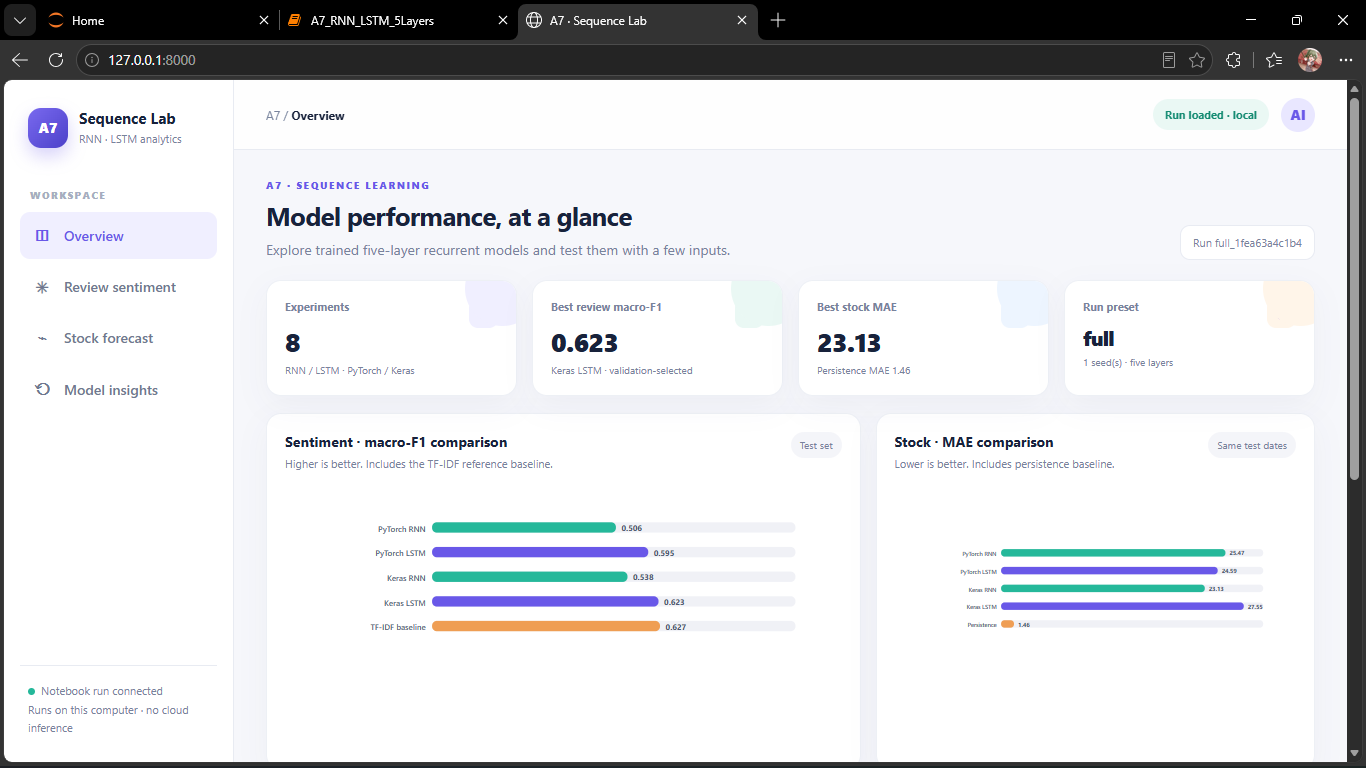
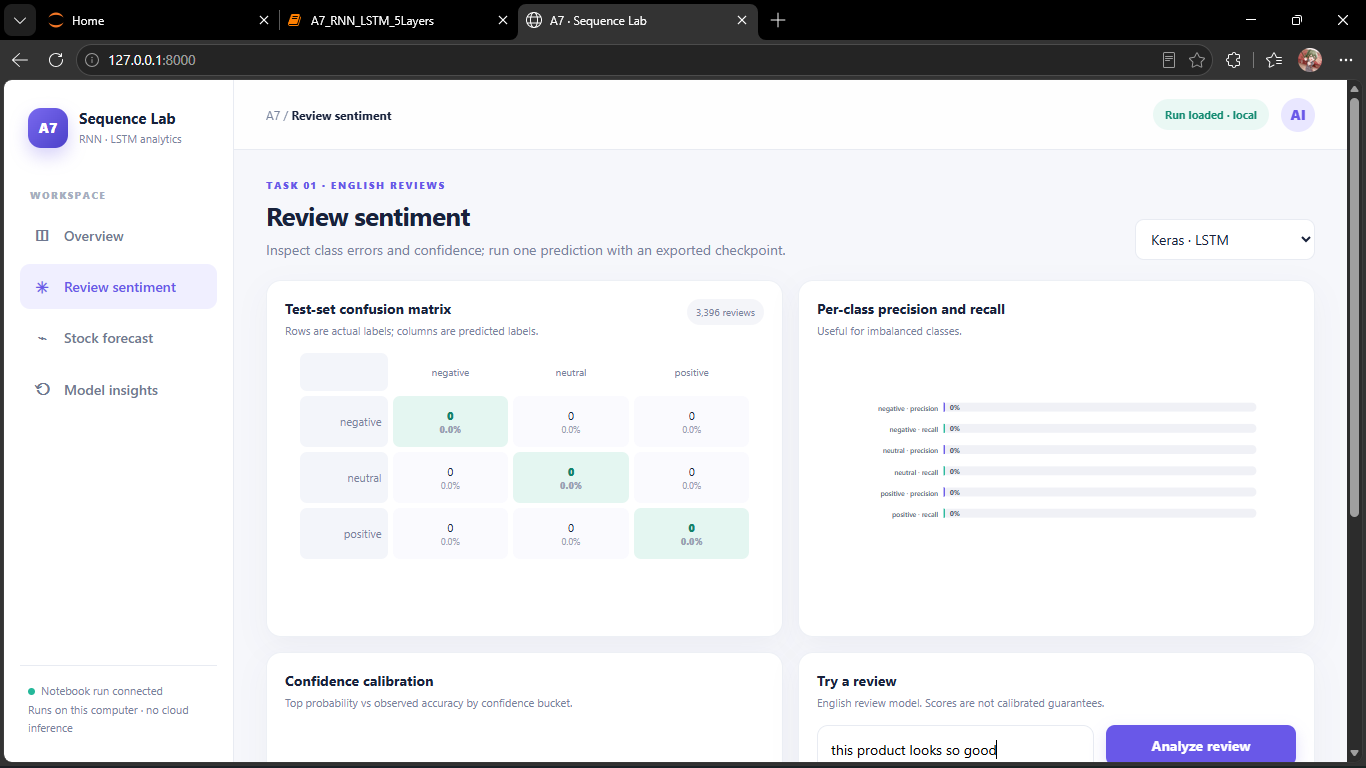
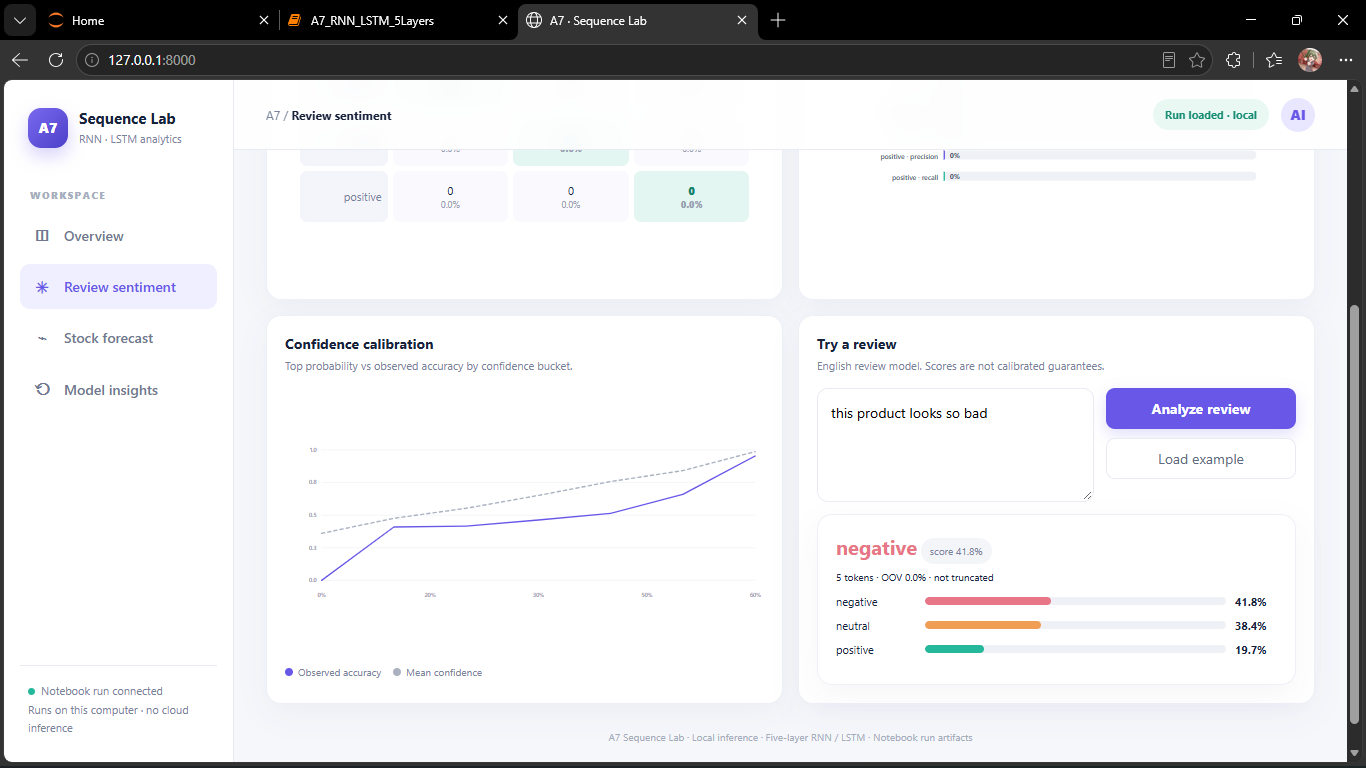
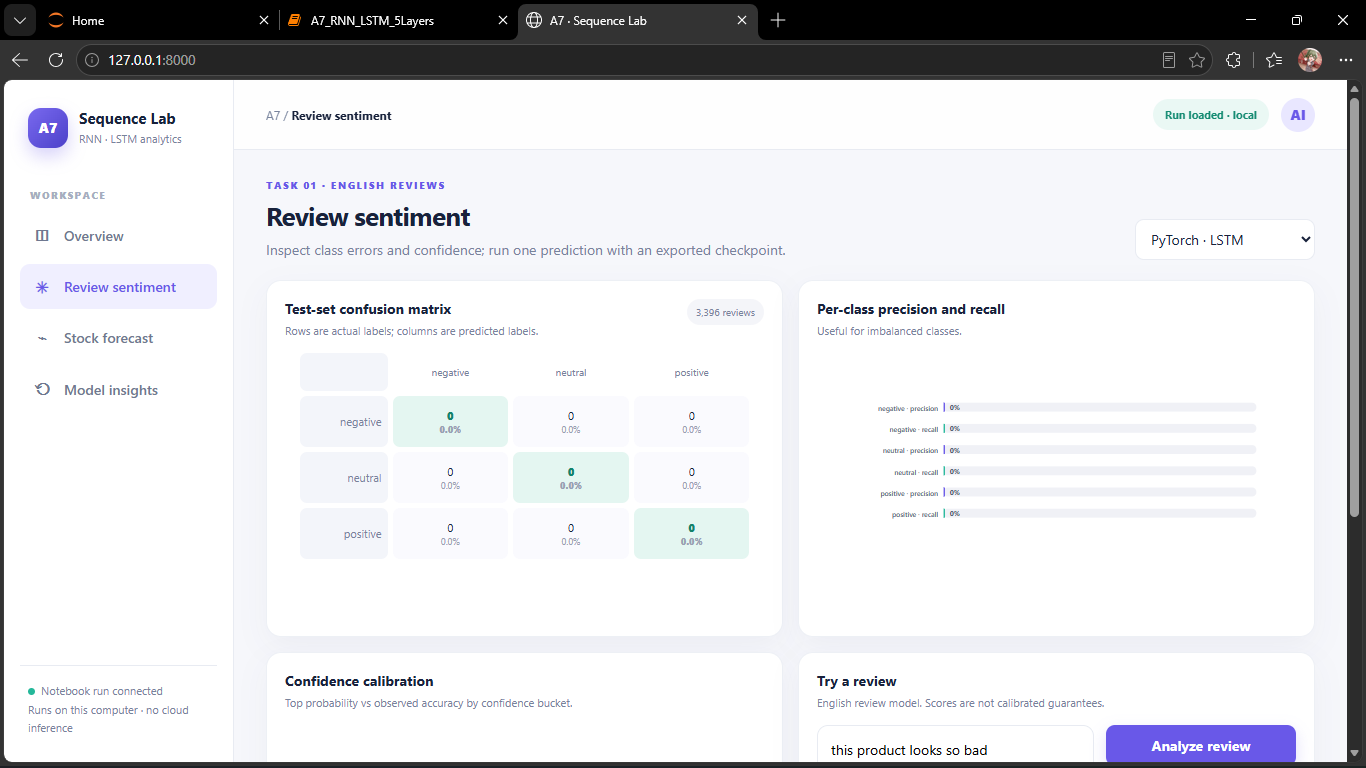
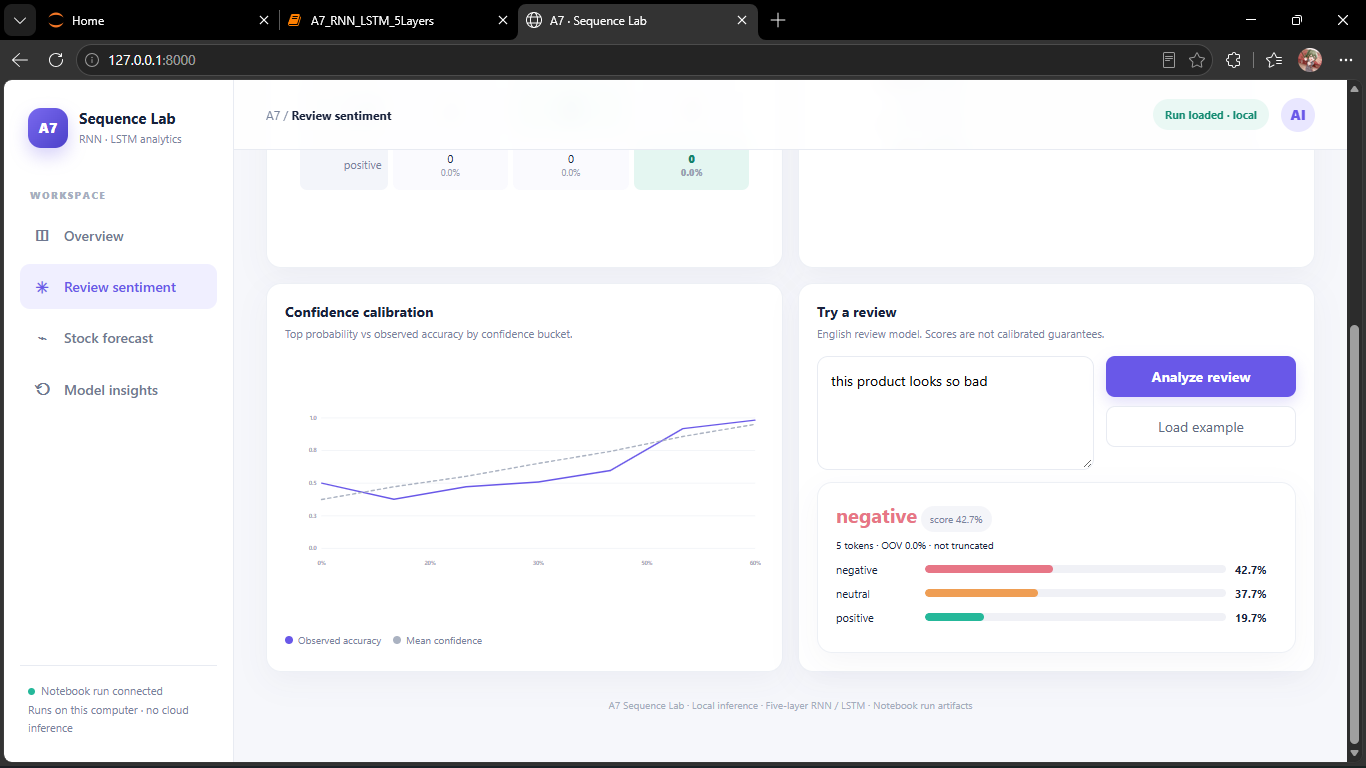
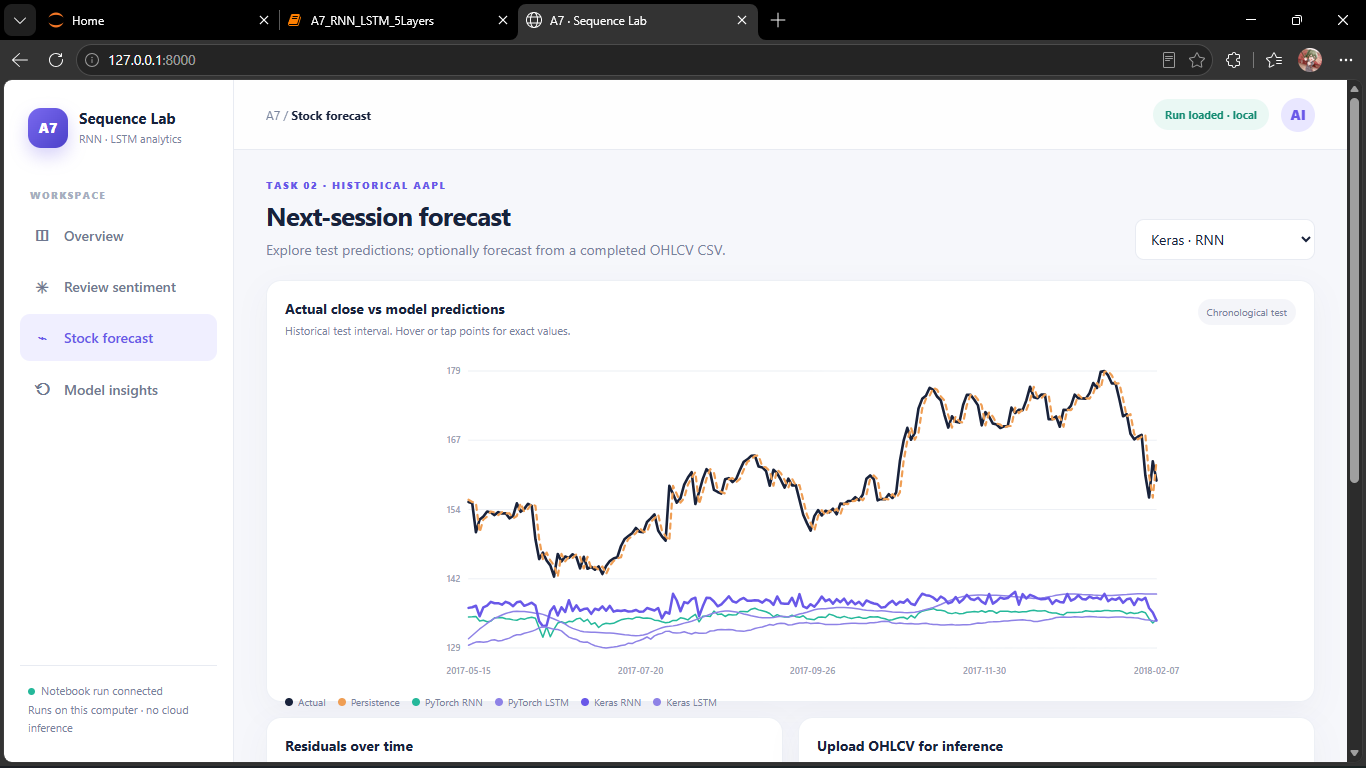
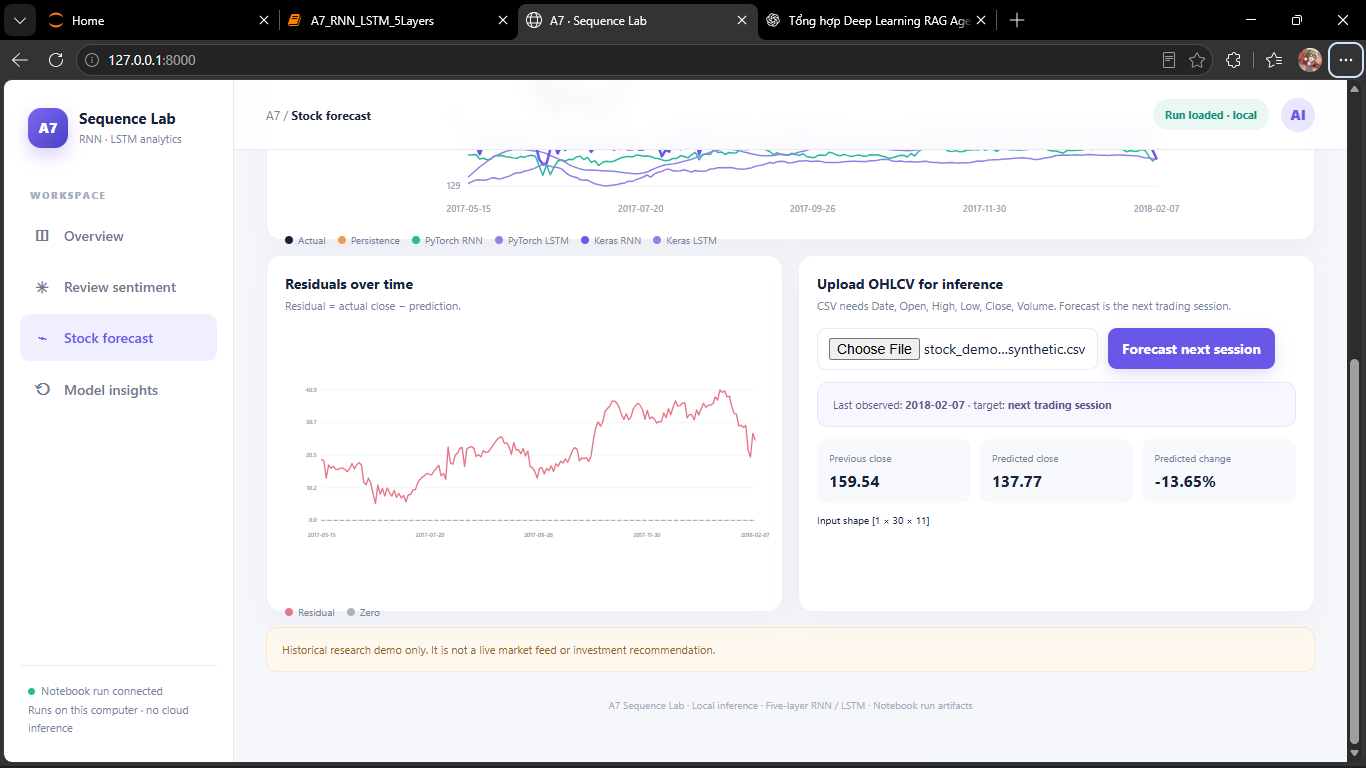
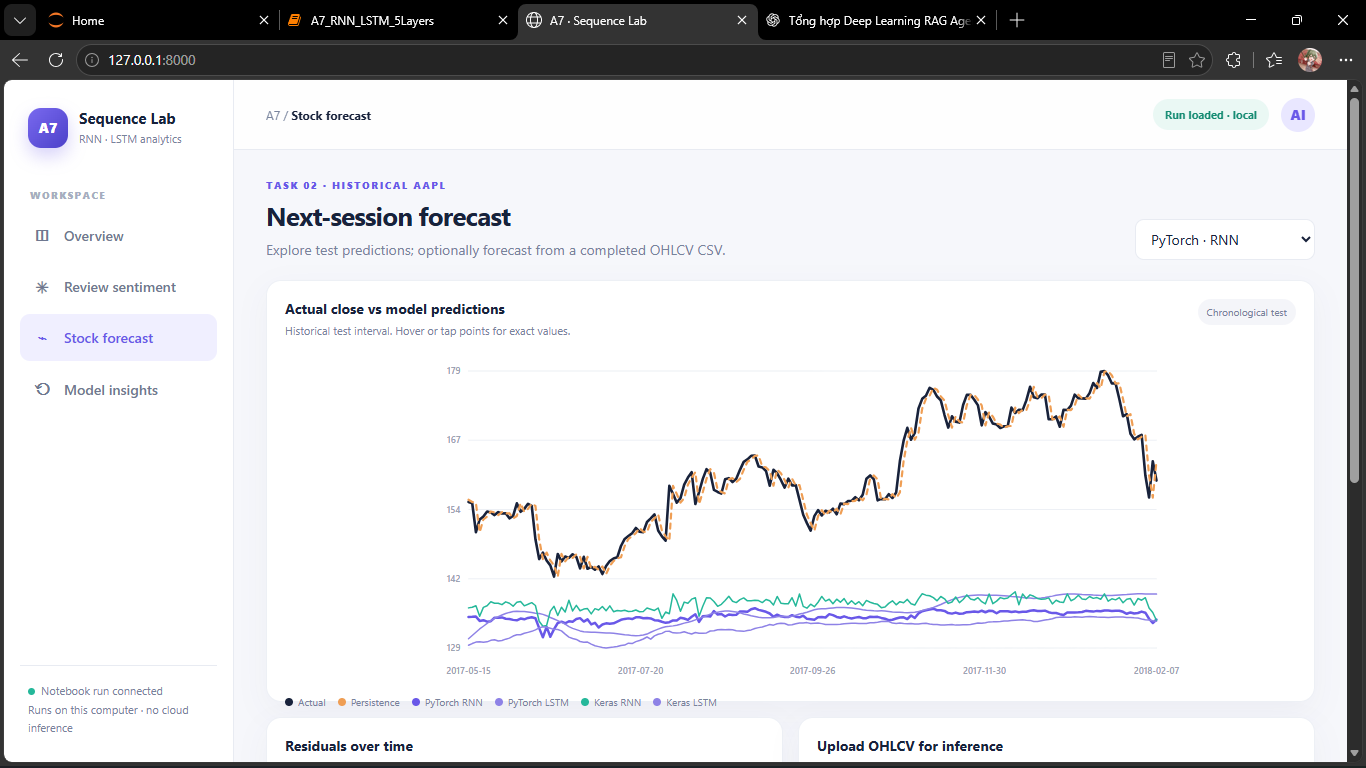
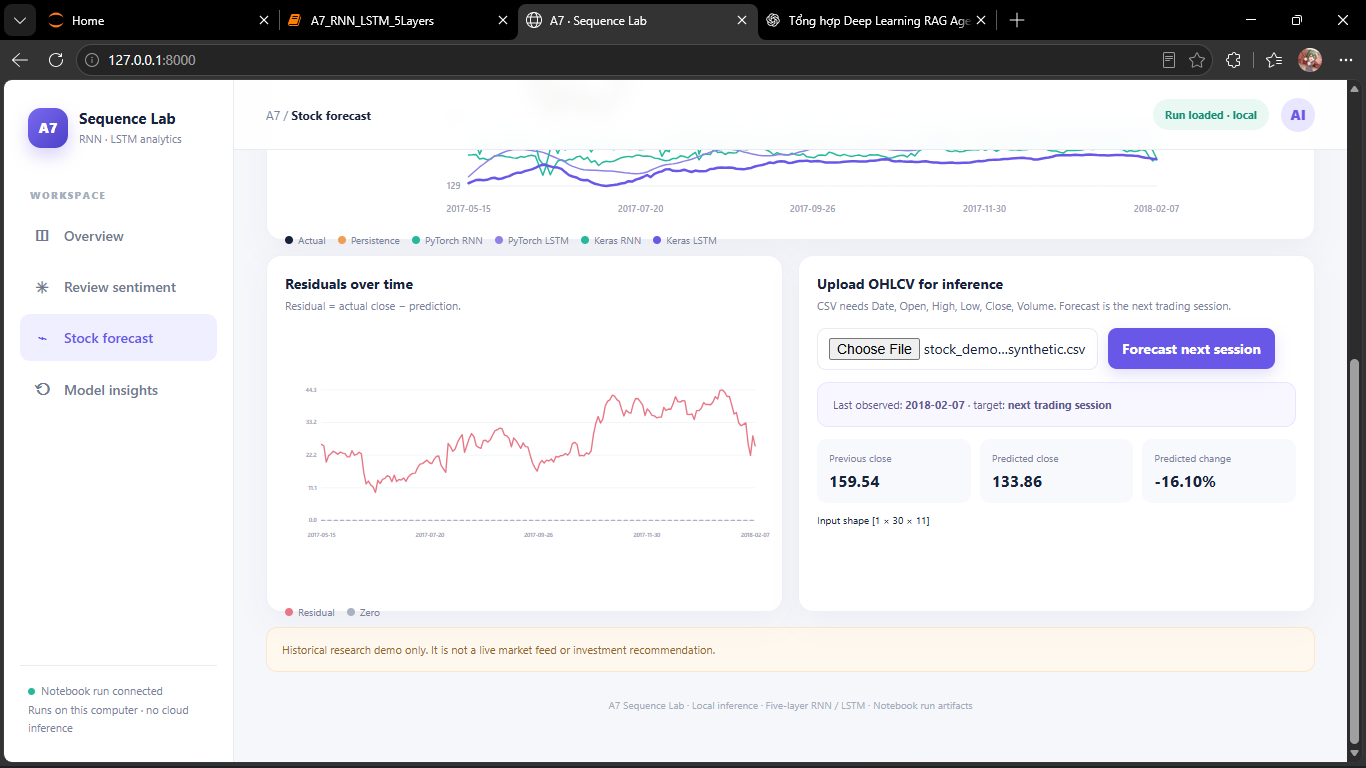